# Proyecto final. Punto 6: Entendimiento de los datos


El proyecto se hace con el área de Procurement. Se trabaja con el reporte *Spend FA x Transit x User ID*, que trae todas las facturas de 10.000 CAD o más creadas entre el 1 de junio de 2022 y el 20 de julio de 2026.

### Objetivo del notebook

En este notebook se hace el análisis exploratorio y de calidad de los datos. La idea es revisar si los datos sirven para las dos cosas que necesita el producto de datos. La primera es caracterizar el gasto aprobado y qué tan concentrado está. La segunda es construir un puntaje de probabilidad de pago duplicado para cada factura. A lo largo del notebook los análisis se conectan con las cuatro hipótesis del punto 4 (H1 duplicados, H2 canal y cadena de aprobación, H3 proveedores y H4 montos atípicos).

### Cómo se trabajó

Antes de empezar se fijaron unos criterios que se mantienen en todo el notebook. Cada problema de calidad que se encuentra termina en una decisión (corregir, marcar, excluir o conservar) y se dice qué efecto tiene esa decisión en los indicadores que usan ese dato. Los montos extremos se revisan antes de usarlos en una correlación o una prueba, y si no se pueden verificar se dejan por fuera de esos cálculos. El periodo de análisis se escoge revisando si las facturas de cada periodo se parecen entre sí, no solo mirando si las fechas cubren el año completo. Además, como los datos son observacionales, las relaciones que se encuentran se leen como asociaciones y no como efectos. Por último, todas las cifras que aparecen en el texto salen de las celdas ejecutadas, y el notebook corre completo sin errores.

### Confidencialidad

Los datos son información interna del Banco, así que no se suben al repositorio (la carpeta data/ está en el .gitignore). Al cargarlos se aplican las medidas del punto 3. Los nombres de personas y de proveedores se cambian por seudónimos (EMP_xxxxx y PROV_xxxx), se eliminan User Login, User ID y Original Approver ID, y los números de factura solo se muestran como patrón, donde cada letra se vuelve A y cada dígito se vuelve 9.

En la sección 6 hay una tabla que organiza todas las técnicas que se usaron según si son univariadas, bivariadas o multivariadas y si son gráficas o no gráficas.

In [1]:
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf
from Levenshtein import ratio
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100

ALPHA = 0.05
RANDOM_STATE = 42
RAW_PATH = "../data/raw/Spend_FA_x_Transit_x_User_ID.xlsx"
PROCESSED_PATH = "../data/processed/facturas_anonimizadas.parquet"
MONTO = "Invoice total with tax (CAD)"          # monto de la factura convertido a CAD
MONTO_ORIG = "Invoice Total with Tax Amount"     # monto en la moneda original

MESES = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]
def fmt_p(p):
    """Valor p en texto, sin notación científica."""
    return "p < 0,001" if p < 0.001 else f"p = {p:.4f}".replace(".", ",")

def ic_prop(k, n, alpha=ALPHA):
    """IC de una proporción con la aproximación normal vista en clase: p ± Z * SE, con SE = raíz(p(1 - p) / n)."""
    p = k / n
    z = stats.norm.ppf(1 - alpha / 2)
    se = np.sqrt(p * (1 - p) / n)
    return max(0.0, p - z * se), min(1.0, p + z * se)

def welch(a, b, alpha=ALPHA):
    """Prueba t de Welch (no exige varianzas iguales) con el IC de la diferencia de medias, como en el caso de negocio."""
    res = stats.ttest_ind(a, b, equal_var=False)
    ic = res.confidence_interval(confidence_level=1 - alpha)
    return np.mean(a) - np.mean(b), ic.low, ic.high, res.statistic, res.df, res.pvalue

def mes_es(p):
    """Periodo mensual en texto corto, por ejemplo 'sep 2024'."""
    p = pd.Period(p, "M")
    return f"{MESES[p.month - 1]} {p.year}"

## 1. Carga, anonimización y entendimiento inicial

### 1.1 Carga de los datos

Las columnas que son códigos (número de factura, contrato y segmentos contables) se leen como texto. Si se leyeran como números se perderían los ceros a la izquierda, por ejemplo el transit 06235 quedaría como 6235.

In [2]:
# Se leen como texto las columnas de códigos para no perder ceros a la izquierda (p. ej. transit "06235")
columnas_texto = ["Invoice Number", "Contract Number", "Account Segment 1", "Account Segment 2",
                  "Account Segment 3", "Account Segment 4"]
raw_df = pd.read_excel(RAW_PATH, dtype={c: str for c in columnas_texto})
raw_df.shape

(75631, 27)

### 1.2 Llave del proveedor y anonimización

El nombre del proveedor viene en un solo campo con el formato NOMBRE_ENTIDAD_CÓDIGO. La entidad es la sociedad del Banco que contrata (por ejemplo 10001 o 40048) y el código es el identificador del proveedor en el maestro. Separar estas partes es necesario por dos razones. La primera es que la llave real del proveedor es la entidad junto con el código, y no el nombre. La segunda es que comparar los nombres es la base para encontrar proveedores duplicados, que es el objetivo específico 3.

In [ ]:
#  Llave del proveedor: el nombre trae el formato NOMBRE_ENTIDAD_CÓDIGO
def separar_proveedor(nombre):
    """Devuelve (nombre_base, entidad, codigo, formato)."""
    if pd.isna(nombre):
        return (np.nan, np.nan, np.nan, "nulo")
    m = re.match(r"^(.*)_(\d+)_(\d+)$", nombre)
    if m:
        return (m.group(1).strip(), m.group(2), m.group(3), "estándar")
    m = re.match(r"^.*\((.*)_(\d+)_(\d+)\)$", nombre)
    if m:
        return (m.group(1).strip(), m.group(2), m.group(3), "nombre repetido entre paréntesis")
    return (nombre.strip(), np.nan, np.nan, "sin entidad ni código")

FORMAS_LEGALES = r"\b(INC|INCORPORATED|LTD|LTEE|LIMITED|LLC|LLP|LP|L P|ULC|CORP|CORPORATION|CO|COMPANY|SAS|S A S|SA|S A|SAA|SRL|S R L|SPA|LTDA|PLC|GMBH|BV|DE CV|S DE RL|THE)\b"

def normalizar_nombre(nombre):
    """Mayúsculas, sin puntuación y sin formas societarias, para comparar nombres de proveedores."""
    if pd.isna(nombre):
        return np.nan
    n = re.sub(r"[^A-Z0-9 ]", " ", str(nombre).upper())
    n = re.sub(FORMAS_LEGALES, " ", n)
    return re.sub(r"\s+", " ", n).strip()

df = raw_df.copy()
df[["prov_nombre_base", "prov_entidad", "prov_codigo", "prov_formato"]] = pd.DataFrame(
    df["Invoice Supplier Name"].apply(separar_proveedor).tolist(), index=df.index)
df["prov_nombre_norm"] = df["prov_nombre_base"].apply(normalizar_nombre)

# Regla de imputación: si un nombre sin código coincide (normalizado) con UN solo proveedor con código, se le asigna ese código
llaves_por_nombre = (df.dropna(subset=["prov_codigo"])
                       .groupby("prov_nombre_norm")[["prov_entidad", "prov_codigo"]]
                       .agg(lambda s: s.unique().tolist()))
sin_codigo = df["prov_formato"].eq("sin entidad ni código")
for idx in df.index[sin_codigo]:
    nombre = df.at[idx, "prov_nombre_norm"]
    if nombre in llaves_por_nombre.index and len(llaves_por_nombre.at[nombre, "prov_codigo"]) == 1:
        df.at[idx, "prov_entidad"] = llaves_por_nombre.at[nombre, "prov_entidad"][0]
        df.at[idx, "prov_codigo"] = llaves_por_nombre.at[nombre, "prov_codigo"][0]

df["prov_llave"] = df["prov_entidad"] + "_" + df["prov_codigo"]
df["prov_formato"].value_counts(dropna=False)

prov_formato
estándar                            75578
nulo                                   42
nombre repetido entre paréntesis       10
sin entidad ni código                   1
Name: count, dtype: int64

Casi todos los nombres siguen el formato esperado (75.578). Hay 42 facturas sin proveedor, 10 donde el nombre aparece repetido entre paréntesis y una que no tiene entidad ni código. Para esa última se usó una regla de imputación: su nombre normalizado coincide con un único proveedor que sí tiene código, así que se le asignó esa llave. Las 42 facturas sin proveedor se conservan, pero quedan por fuera de los análisis por proveedor.

Hay algunas señales que solo se pueden calcular con los nombres reales. Por ejemplo, saber si el proveedor es una entidad del mismo grupo del Banco, si quien solicita la compra es el mismo aprobador original o cuántos nombres distintos tiene cada llave de proveedor. Por eso se calculan antes de anonimizar y después se eliminan los nombres. En ningún momento el notebook imprime un nombre real.

In [ ]:
# Señales que necesitan los nombres reales y que se calculan ANTES de anonimizar

# Entidades del mismo grupo (pagos intragrupo). Se identifican por nombre; no se imprime ningún nombre.
PATRON_INTRAGRUPO = (r"^(?:THE )?BANK OF NOVA SCOTIA|SCOTIABANK|^SCOTIA (?:GBS|GLOBAL|CAPITAL|WEALTH|SERVICIOS|DEALER|"
                     r"LOYALTY|MCLEOD|MORTGAGE|REALTY|LIFE)|SCOTIAMCLEOD|SCOTIATRUST|BANQUE SCOTIA|TANGERINE BANK|"
                     r"1832 ASSET MANAGEMENT|JARISLOWSKY|MD FINANCIAL MANAGEMENT")
df["prov_intragrupo"] = df["prov_nombre_base"].str.upper().str.contains(PATRON_INTRAGRUPO, regex=True, na=False)

# Segregación de funciones: quien solicita es el mismo aprobador original
df["solicitante_es_aprobador"] = (df["Requested by Name"].notna()
                                  & (df["Requested by Name"] == df["Original Approver Name"]))

# Singularidad de identificadores de personas (un login/ID con más de un nombre)
logins_multinombre = df.groupby("User Login")["Requested by Name"].nunique().gt(1).sum()
ids_aprob_multinombre = df.groupby("Original Approver ID")["Original Approver Name"].nunique().gt(1).sum()

# Variantes de nombre por llave de proveedor (sinónimos) y nombres con varias llaves (posibles duplicados del maestro)
variantes_por_llave = df.dropna(subset=["prov_llave"]).groupby("prov_llave")["prov_nombre_base"].nunique()
llaves_por_nombre_norm = df.dropna(subset=["prov_llave"]).groupby("prov_nombre_norm")["prov_llave"].nunique()

print(f"Facturas de proveedores intragrupo:            {df['prov_intragrupo'].sum():,}")
print(f"Facturas donde solicitante = aprobador original: {df['solicitante_es_aprobador'].sum():,}")
print(f"Logins asociados a más de un nombre:            {logins_multinombre}")
print(f"IDs de aprobador asociados a más de un nombre:  {ids_aprob_multinombre}")
print(f"Llaves de proveedor con más de un nombre:       {(variantes_por_llave > 1).sum()}")
print(f"Nombres normalizados con más de una llave:      {(llaves_por_nombre_norm > 1).sum()}")

Facturas de proveedores intragrupo:            3,187
Facturas donde solicitante = aprobador original: 8,373
Logins asociados a más de un nombre:            0
IDs de aprobador asociados a más de un nombre:  1
Llaves de proveedor con más de un nombre:       117
Nombres normalizados con más de una llave:      122


Hay 3.187 facturas de proveedores que pertenecen al mismo grupo del Banco. Son pagos entre entidades relacionadas y funcionan distinto a los de un proveedor externo, por eso se marcan con la bandera prov_intragrupo. En 8.373 facturas el solicitante también aparece como aprobador original; esto se revisa en la sección 3.3 antes de interpretarlo como una falta de segregación de funciones.

En cuanto al maestro de proveedores, 117 llaves aparecen con más de un nombre (por ejemplo el mismo nombre con y sin punto final) y 122 nombres normalizados están asociados a más de una llave, lo que podría indicar proveedores duplicados. Los dos casos se analizan en la sección 3.5. Por último, un ID de aprobador tiene dos nombres distintos y ningún login tiene más de un nombre, así que el problema de singularidad en las personas es muy pequeño.

Ahora se crean los seudónimos y se eliminan los identificadores directos. Desde este punto el dataframe df ya no tiene nombres de personas ni de proveedores.

In [ ]:
# Seudonimización y eliminación de datos personales (punto 3 de la entrega)
llaves = sorted(df["prov_llave"].dropna().unique())
mapa_proveedores = {k: f"PROV_{i:04d}" for i, k in enumerate(llaves, start=1)}
df["proveedor_id"] = df["prov_llave"].map(mapa_proveedores)

# Grupo de proveedor por nombre normalizado (se usa en la sección de duplicados del maestro)
nombres = sorted(df["prov_nombre_norm"].dropna().unique())
mapa_nombres = {n: f"GRUPO_{i:04d}" for i, n in enumerate(nombres, start=1)}
df["grupo_nombre_id"] = df["prov_nombre_norm"].map(mapa_nombres)

cols_personas = ["Requested by Name", "Finance Approver", "Finance Approver2", "Original Approver Name"]
personas = sorted(pd.unique(pd.concat([df[c] for c in cols_personas]).dropna()))
mapa_personas = {p: f"EMP_{i:05d}" for i, p in enumerate(personas, start=1)}
for c in cols_personas:
    df[c] = df[c].map(mapa_personas)

# Número de factura: se conserva solo una versión normalizada (sin espacios, guiones ni ceros a la izquierda)
df["num_factura_norm"] = (df["Invoice Number"].str.upper()
                          .str.replace(r"[^A-Z0-9]", "", regex=True).str.lstrip("0"))
# Patrón del número (las letras se vuelven A y los dígitos 9) para mostrar ejemplos sin exponer el número real
df["num_factura_patron"] = (df["Invoice Number"].str.replace(r"[0-9]", "9", regex=True)
                            .str.replace(r"[A-Za-z]", "A", regex=True))
df["num_factura_original"] = df["Invoice Number"]   # se usa internamente; nunca se imprime

# Se eliminan identificadores directos (decisión del punto 3)
df = df.drop(columns=["User Login", "User ID", "Original Approver ID", "Invoice Supplier Name",
                      "prov_nombre_base", "Invoice Number"])
del raw_df, mapa_personas, personas, nombres   # no se conservan los nombres reales en memoria
df.shape

(75631, 34)

### 1.3 Dimensiones, tipos de datos y granularidad

In [6]:
print("Dimensiones:", df.shape)
originales = [c for c in df.columns if c[0].isupper()]
tipos = pd.DataFrame({
    "tipo_pandas": df[originales].dtypes.astype(str),
    "valores_unicos": df[originales].nunique(),
    "pct_nulos": (df[originales].isna().mean() * 100).round(1),
})
tipos

Dimensiones: (75631, 34)


,tipo_pandas,valores_unicos,pct_nulos
Requested by Name,str,2848,16.00
Finance Approver,str,106,61.40
Finance Approver2,str,78,83.20
Original Approver Name,str,2553,56.30
Number of Approvers,float64,18,57.30
Invoice Status,str,10,0.00
Invoice Created Date,datetime64[us],1345,0.00
Invoice Total with Tax Amount,float64,50461,0.00
Invoice Currency Code,str,14,0.00
Invoice Currency Name,str,14,0.00


In [7]:
df[originales + ["proveedor_id"]].sample(5, random_state=RANDOM_STATE).assign(
    **{"Invoice Created Date": lambda t: t["Invoice Created Date"].dt.strftime("%d/%m/%Y")})

,Requested by Name,Finance Approver,Finance Approver2,Original Approver Name,Number of Approvers,Invoice Status,Invoice Created Date,Invoice Total with Tax Amount,Invoice Currency Code,Invoice Currency Name,Contract Number,Commodity Level 1,Commodity Level 2,Commodity Name,Account Segment 1,Account Segment 2,Account Segment 3,Account Segment 4,Creation Method,Invoice Channel,Invoice Created by Type,Invoice total with tax (CAD),proveedor_id
42970,NaN,NaN,NaN,EMP_03702,3.00,approved,05/12/2025,"12,204.00",CAD,"Canada, Dollars",NaN,NaN,NaN,NaN,14647,10173,1633,150037-000,enterprise_ui,ui,NaN,"12,204.00",PROV_3085
14998,EMP_01000,EMP_01210,EMP_01210,NaN,NaN,approved,06/03/2024,"470,880.38",CAD,"Canada, Dollars",3637,Advertising & Marketing,Advertising,Other Advertising,54502,1B001,90010-000,600650-000,csp_po_flip,csp,SupplierUser,"470,880.38",PROV_0822
37725,EMP_00548,NaN,NaN,EMP_00250,4.00,approved,18/02/2025,"278,408.45",CAD,"Canada, Dollars",NaN,NaN,NaN,NaN,36467,10198,18230-001,606203-000,inbound_invoice,email,NaN,"278,408.45",PROV_0758
17904,EMP_00397,EMP_01206,NaN,EMP_00639,5.00,approved,09/12/2024,"46,137.89",CAD,"Canada, Dollars",27363,NaN,NaN,NaN,04234,1B001,10212-000,607000-000,csp_create,csp,SupplierUser,"46,137.89",PROV_0395
8842,EMP_02883,EMP_01222,EMP_01222,NaN,NaN,approved,16/11/2023,"34,833.53",CAD,"Canada, Dollars",4915,External Labour Services,Consulting Services,Human Resources Consulting,14472,1B001,91070-000,607650-000,csp_po_flip,csp,SupplierUser,"34,833.53",PROV_1337


El conjunto original tiene 75.631 facturas y 27 atributos. Después de eliminar los identificadores personales y agregar las llaves con seudónimo quedan 34 columnas. Aunque el archivo es grande, casi toda la información es categórica o de texto. Solo tres atributos son cuantitativos: el monto en moneda original, el monto convertido a CAD y el número de aprobadores. Los dos campos numéricos que se eliminaron (User ID y Original Approver ID) eran identificadores y no cantidades. Además, hay una sola fecha (Invoice Created Date), lo que limita el análisis de tiempos porque no se sabe cuándo se pagó ni cuándo se aprobó cada factura.

La tabla de tipos ya muestra algo que se estudia en la sección 3. Los atributos de aprobación (Finance Approver2, Finance Approver, Number of Approvers y Original Approver Name) tienen entre 56% y 83% de nulos, mientras que los de la factura (estado, fecha, montos, moneda y canal) están completos.

In [8]:
# ¿Qué representa una fila? Se verifica si el número de factura identifica de forma única cada registro
print("Filas totalmente duplicadas:             ", df.duplicated().sum())
print("Facturas sin número:                      ", df["num_factura_original"].isna().sum(),
      df.loc[df["num_factura_original"].isna(), "Invoice Status"].value_counts().to_dict())
print("Números de factura repetidos (no nulos):  ",
      df["num_factura_original"].dropna().duplicated().sum())
print("Rango de fechas de creación:              ",
      df["Invoice Created Date"].min().strftime("%d/%m/%Y"), "a", df["Invoice Created Date"].max().strftime("%d/%m/%Y"))
print("Monto mínimo en CAD:                      ", df[MONTO].min())
print("Facturas con monto en moneda original < 10.000 pero >= 10.000 CAD:",
      ((df[MONTO_ORIG] < 10_000) & (df["Invoice Currency Code"] != "CAD")).sum())
df["Invoice Status"].value_counts(dropna=False).to_frame("facturas")

Filas totalmente duplicadas:              0
Facturas sin número:                       288 {'voided': 186, 'draft': 94, 'new': 7, 'approved': 1}
Números de factura repetidos (no nulos):   0
Rango de fechas de creación:               01/06/2022 a 20/07/2026
Monto mínimo en CAD:                       10000.0
Facturas con monto en moneda original < 10.000 pero >= 10.000 CAD: 1311


,facturas
Invoice Status,
approved,70651
voided,4126
disputed,214
pending_receipt,188
draft,127
rejected,124
pending_approval,83
on_hold,55
pending_action,50


Cada fila es una factura. No hay filas duplicadas y ningún número de factura se repite, porque el sistema no lo permite. Las 288 facturas sin número son casi todas anuladas (186) o borradores (94) y solo una está aprobada.

El monto mínimo es exactamente 10.000 CAD, lo que muestra que la extracción filtró por el monto ya convertido a CAD. Por eso entran 1.311 facturas en otra moneda cuyo monto original es menor a 10.000, es decir, el umbral no es igual para todas las monedas.

El estado de la factura está muy desbalanceado. Hay 70.651 facturas aprobadas (93,4%), 4.126 anuladas, 214 en disputa, 124 rechazadas y unas pocas en estados intermedios. En los datos no existe una etiqueta de pago duplicado ni de fraude, así que las variables objetivo provisionales se definen más adelante, en la sección 5.

## 2. Cobertura temporal y comparabilidad de periodos

Que cada año tenga fechas de enero a diciembre no es suficiente para compararlos. Lo que hay que revisar es si las facturas de cada periodo se parecen, es decir, si entran por los mismos canales, si tienen la misma proporción de contratos y si tienen los mismos campos informados. Si la composición cambia, una diferencia entre años puede deberse a un cambio en el proceso o en lo que entra al sistema, y no a un cambio en el riesgo.

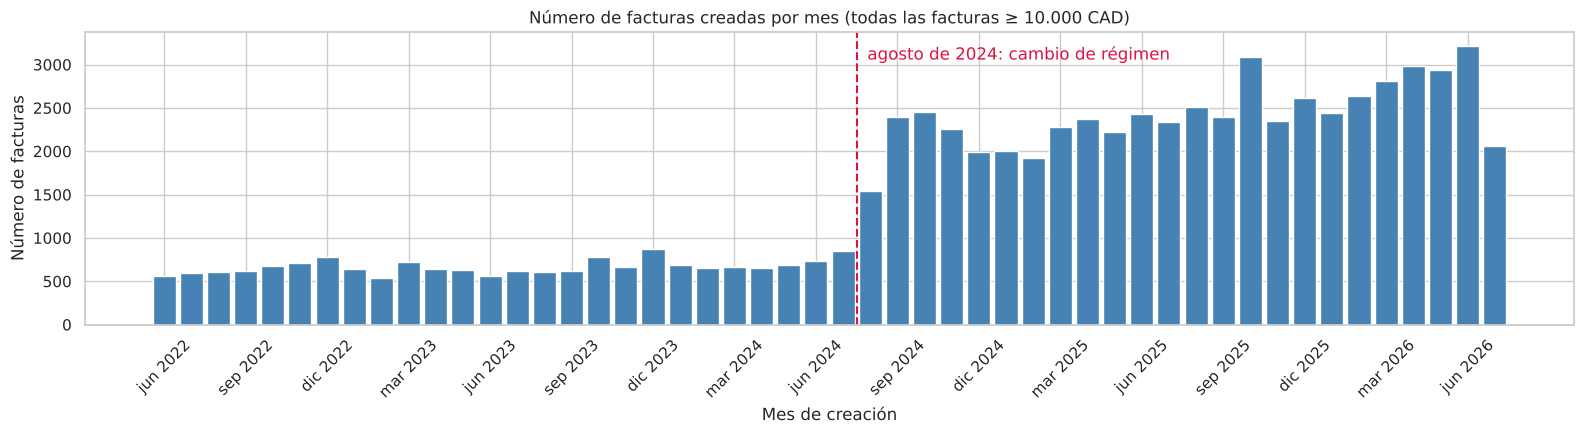

Antes de agosto de 2024: entre 542 y 868 facturas por mes (mediana 654)
Desde septiembre de 2024: entre 1922 y 3219 facturas por mes (mediana 2397)
Julio, agosto y septiembre de 2024: [845, 1538, 2397]


,min,max,count
anio,,,
2022,01/06/2022,31/12/2022,4558
2023,01/01/2023,31/12/2023,7895
2024,01/01/2024,31/12/2024,15565
2025,01/01/2025,31/12/2025,28530
2026,01/01/2026,20/07/2026,19083


In [9]:
df["mes"] = df["Invoice Created Date"].dt.to_period("M")
df["anio"] = df["Invoice Created Date"].dt.year

mensual = df.groupby("mes").agg(facturas=(MONTO, "size"))
pos = np.arange(len(mensual))
pos_ruptura = list(mensual.index).index(pd.Period("2024-08", "M"))
fig, ax = plt.subplots(figsize=(16, 4.5))
ax.bar(pos, mensual["facturas"], color="steelblue", width=0.85)
ax.axvline(pos_ruptura - 0.5, color="crimson", ls="--", lw=1.5)
ax.text(pos_ruptura - 0.3, mensual["facturas"].max() * 0.95, " agosto de 2024: cambio de régimen", color="crimson")
ax.set_title("Número de facturas creadas por mes (todas las facturas ≥ 10.000 CAD)")
ax.set_xlabel("Mes de creación"); ax.set_ylabel("Número de facturas")
ax.set_xticks(pos[::3]); ax.set_xticklabels([mes_es(p) for p in mensual.index[::3]], rotation=45)
plt.tight_layout(); plt.show()
antes = mensual.loc[mensual.index < pd.Period("2024-08", "M"), "facturas"]
despues = mensual.loc[mensual.index >= pd.Period("2024-09", "M"), "facturas"]
print(f"Antes de agosto de 2024: entre {antes.min()} y {antes.max()} facturas por mes (mediana {antes.median():.0f})")
print(f"Desde septiembre de 2024: entre {despues.min()} y {despues.max()} facturas por mes (mediana {despues.median():.0f})")
print("Julio, agosto y septiembre de 2024:", mensual.loc["2024-07":"2024-09", "facturas"].tolist())

df.groupby("anio")["Invoice Created Date"].agg(["min", "max", "count"]).assign(
    min=lambda t: t["min"].dt.strftime("%d/%m/%Y"), max=lambda t: t["max"].dt.strftime("%d/%m/%Y"))

Los años de los extremos están incompletos, porque 2022 empieza el 1 de junio y 2026 termina el 20 de julio. Sin embargo, lo más importante de la gráfica es otra cosa. Hasta julio de 2024 el volumen se mueve entre 542 y 868 facturas por mes (mediana de 654), y en agosto de 2024 salta: pasa de 845 facturas en julio a 1.538 en agosto y 2.397 en septiembre. Desde septiembre se queda en otro nivel, entre 1.922 y 3.219 facturas por mes. Un salto así de brusco suele indicar un cambio en el proceso y no un aumento real de las compras, así que en las siguientes celdas se revisa qué fue lo que cambió.

In [ ]:
# Los periodos se parecen? Se compara la composición de las facturas por trimestre
df["trimestre"] = df["Invoice Created Date"].dt.to_period("Q")
pendientes = ["pending_receipt", "pending_approval", "pending_action", "on_hold", "draft", "new"]
composicion = df.groupby("trimestre").agg(
    facturas=(MONTO, "size"),
    pct_canal_sftp=("Invoice Channel", lambda s: (s == "sftp").mean() * 100),
    pct_canal_csp=("Invoice Channel", lambda s: (s == "csp").mean() * 100),
    pct_con_contrato=("Contract Number", lambda s: s.notna().mean() * 100),
    pct_sin_n_aprobadores=("Number of Approvers", lambda s: s.isna().mean() * 100),
    pct_sin_categoria=("Commodity Level 1", lambda s: s.isna().mean() * 100),
    pct_anuladas=("Invoice Status", lambda s: (s == "voided").mean() * 100),
    pct_sin_resolver=("Invoice Status", lambda s: s.isin(pendientes).mean() * 100),
)
composicion.round(1)

,facturas,pct_canal_sftp,pct_canal_csp,pct_con_contrato,pct_sin_n_aprobadores,pct_sin_categoria,pct_anuladas,pct_sin_resolver
trimestre,,,,,,,,
2022Q2,566,0.00,59.00,82.30,83.90,77.20,6.70,0.40
2022Q3,1816,0.00,61.50,76.10,82.60,72.40,11.60,0.40
2022Q4,2176,0.00,62.70,75.00,83.30,61.90,12.90,0.40
2023Q1,1904,0.00,52.80,73.00,79.70,63.70,7.20,0.30
2023Q2,1844,0.00,52.70,73.30,74.70,54.60,7.00,0.20
2023Q3,1840,0.50,57.30,71.70,74.50,47.60,5.70,0.20
2023Q4,2307,5.50,57.20,70.00,71.00,50.20,10.20,0.20
2024Q1,2005,9.00,50.00,67.30,68.10,45.80,5.10,0.60
2024Q2,2082,10.90,50.30,64.90,66.30,45.60,6.30,0.40


La composición de las facturas cambia al mismo tiempo que el volumen. El canal sftp, que son cargas automáticas por API, pasa de 0% en 2022 a cerca de 10% en el primer semestre de 2024, sube a 24% en el tercer trimestre de 2024 y sigue creciendo hasta 37,7% en el segundo trimestre de 2026. Las facturas con contrato bajan de entre 65% y 82% antes de mediados de 2024 a entre 24,7% y 31,7% después. Algo parecido pasa con las facturas sin categoría, que bajan de 77% en 2022 a entre 23,1% y 38,5% desde el tercer trimestre de 2024, y con las que no tienen número de aprobadores, que pasan de 84% a 39%.

Las facturas sin resolver se mantienen entre 0,2% y 0,7% por trimestre, pero suben a 1,9% en el segundo trimestre de 2026 y a 5,1% en el tercero. Esto indica que las facturas más recientes todavía no tienen su estado final, algo que se revisa en la sección 3.6.

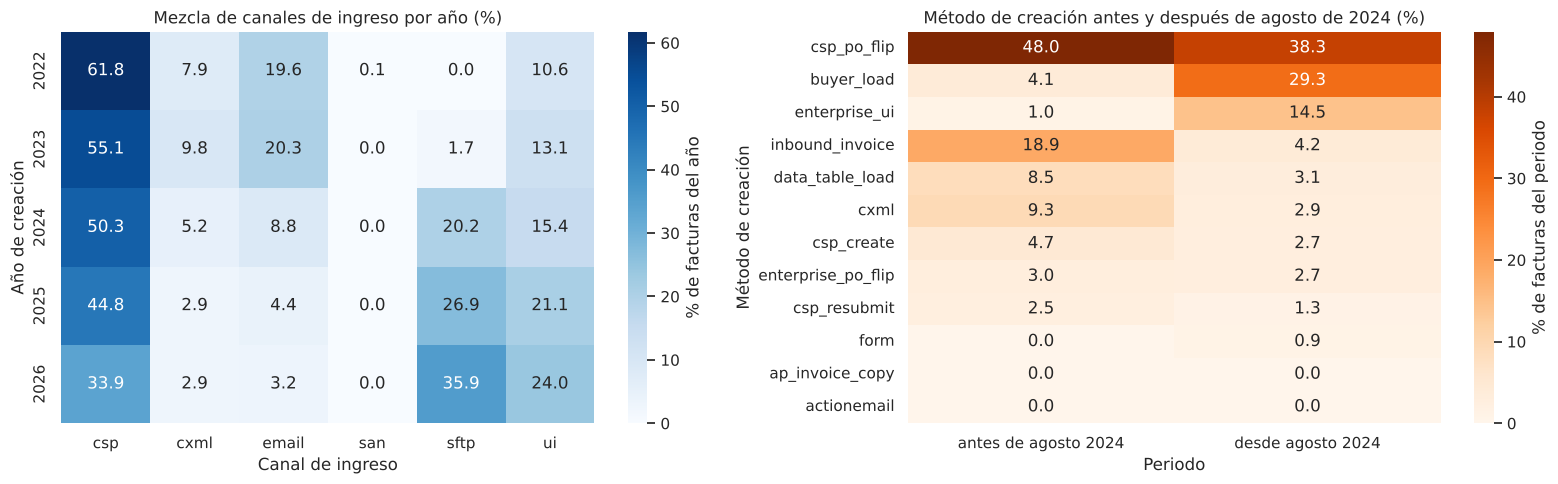

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
canal_anio = pd.crosstab(df["anio"], df["Invoice Channel"], normalize="index") * 100
sns.heatmap(canal_anio, annot=True, fmt=".1f", cmap="Blues", ax=axes[0], cbar_kws={"label": "% de facturas del año"})
axes[0].set_title("Mezcla de canales de ingreso por año (%)")
axes[0].set_xlabel("Canal de ingreso"); axes[0].set_ylabel("Año de creación")

metodo_periodo = pd.crosstab(
    np.where(df["Invoice Created Date"] < "2024-08-01", "antes de agosto 2024", "desde agosto 2024"),
    df["Creation Method"], normalize="index") * 100
sns.heatmap(metodo_periodo.T.sort_values("desde agosto 2024", ascending=False), annot=True, fmt=".1f",
            cmap="Oranges", ax=axes[1], cbar_kws={"label": "% de facturas del periodo"})
axes[1].set_title("Método de creación antes y después de agosto de 2024 (%)")
axes[1].set_xlabel("Periodo"); axes[1].set_ylabel("Método de creación")
plt.tight_layout(); plt.show()

El mapa de métodos de creación muestra de dónde viene el cambio. Desde agosto de 2024 el método buyer_load (facturas que el Banco carga por sftp) pasa de 4,1% a 29,3% de las facturas, y enterprise_ui (facturas que digita el personal interno) pasa de 1,0% a 14,5%. Al mismo tiempo inbound_invoice, que son las facturas que llegan por correo, baja de 18,9% a 4,2%. Lo más probable es que desde agosto de 2024 empezaran a entrar a SmartBuy facturas sin orden de compra que antes se procesaban por fuera de la herramienta. Esta hipótesis hay que validarla con el stakeholder.

In [ ]:
# Prueba formal: la composición cambia entre el régimen anterior y el actual?
def cramers_v(tabla):
    chi2 = stats.chi2_contingency(tabla)[0]
    n = tabla.to_numpy().sum()
    r, k = tabla.shape
    return np.sqrt(chi2 / (n * (min(r, k) - 1)))

df["regimen"] = np.where(df["Invoice Created Date"] < "2024-08-01", "anterior (junio 2022 a julio 2024)", "actual (agosto 2024 a julio 2026)")
resultados = []
for var, serie in {"canal": df["Invoice Channel"],
                   "tiene contrato": df["Contract Number"].notna(),
                   "categoría informada": df["Commodity Level 1"].notna(),
                   "entidad del proveedor": df["prov_entidad"].fillna("sin dato")}.items():
    tabla = pd.crosstab(df["regimen"], serie)
    chi2, p, dof, _ = stats.chi2_contingency(tabla)
    resultados.append({"variable": var, "chi2": chi2, "gl": dof, "p_valor": p, "V_de_Cramer": cramers_v(tabla)})

# Monto: como es muy asimétrico se compara en escala log10 con la prueba t de Welch
ant = df.loc[df["regimen"].str.startswith("anterior"), MONTO].dropna()
act = df.loc[df["regimen"].str.startswith("actual"), MONTO].dropna()
dif, lo, hi, t, gl, p = welch(np.log10(ant), np.log10(act))
print(f"Mediana del monto: anterior {ant.median():,.0f} CAD | actual {act.median():,.0f} CAD")
print(f"Diferencia de medias en log10 (anterior menos actual): {dif:.3f}, IC 95% [{lo:.3f}, {hi:.3f}] | "
      f"t de Welch = {t:.1f}, gl = {gl:,.0f}, {fmt_p(p)} | en escala original el monto típico anterior es {10**dif:.2f} veces el actual")
pd.DataFrame(resultados).round(4)

Mediana del monto: anterior 36,449 CAD | actual 30,849 CAD
Diferencia de medias en log10 (anterior menos actual): 0.062, IC 95% [0.052, 0.071] | t de Welch = 13.1, gl = 27,610, p < 0,001 | en escala original el monto típico anterior es 1.15 veces el actual


,variable,chi2,gl,p_valor,V_de_Cramer
0,canal,"9,713.97",5,0.00,0.36
1,tiene contrato,"11,618.42",1,0.00,0.39
2,categoría informada,"3,958.30",1,0.00,0.23
3,entidad del proveedor,"2,886.51",4,0.00,0.20


Las pruebas chi cuadrado confirman que la composición del régimen anterior (junio de 2022 a julio de 2024) y la del actual (agosto de 2024 a julio de 2026) es distinta. La asociación es moderada para el canal (V de Cramér de 0,36) y para tener contrato (0,39), y está entre débil y moderada para la categoría informada (0,23) y la entidad del proveedor (0,20). La mediana del monto también cambia, de 36.449 CAD antes a 30.849 CAD después. Como el monto es muy asimétrico, la comparación se hizo en escala log10 con la prueba t de Welch, que no exige varianzas iguales. La diferencia de medias en log10 es 0,062 (IC 95% de 0,052 a 0,071; p < 0,001), es decir, el monto típico del régimen anterior era unas 1,15 veces el actual. Con 75 mil facturas casi cualquier diferencia sale significativa, así que acá lo que importa es el tamaño de la V de Cramér, y en canal y contrato no es pequeño.

In [ ]:
# Dentro del régimen actual, los semestres se parecen? (se excluyen jun-jul 2026 por estar sin resolver, ver sección 3.7)
dentro = df[(df["Invoice Created Date"] >= "2024-09-01") & (df["Invoice Created Date"] < "2026-06-01")].copy()
dentro["semestre"] = dentro["Invoice Created Date"].dt.year.astype(str) + " S" + np.where(dentro["Invoice Created Date"].dt.month <= 6, "1", "2")
estabilidad = dentro.groupby("semestre").agg(
    facturas_por_mes=(MONTO, lambda s: len(s) / dentro.loc[s.index, "mes"].nunique()),
    mediana_monto_cad=(MONTO, "median"),
    pct_sftp=("Invoice Channel", lambda s: (s == "sftp").mean() * 100),
    pct_con_contrato=("Contract Number", lambda s: s.notna().mean() * 100),
    pct_anuladas=("Invoice Status", lambda s: (s == "voided").mean() * 100),
    pct_disputa_rechazo=("Invoice Status", lambda s: s.isin(["disputed", "rejected"]).mean() * 100),
)
print("Meses por semestre:", dentro.groupby("semestre")["mes"].nunique().to_dict())
estabilidad.round(1)

Meses por semestre: {'2024 S2': 4, '2025 S1': 6, '2025 S2': 6, '2026 S1': 5}


,facturas_por_mes,mediana_monto_cad,pct_sftp,pct_con_contrato,pct_anuladas,pct_disputa_rechazo
semestre,,,,,,
2024 S2,"2,273.80","29,457.10",23.80,25.40,5.80,0.20
2025 S1,"2,204.50","29,172.50",24.20,26.90,5.50,0.30
2025 S2,"2,550.50","31,159.10",29.20,26.20,3.50,0.70
2026 S1,"2,761.00","32,634.50",35.20,25.60,4.70,0.90


**Decisión sobre el periodo de análisis**

Dentro del régimen actual los semestres se parecen bastante más entre sí. Las facturas por mes van de 2.274 a 2.761, la mediana del monto está entre 29,2 y 32,6 mil CAD y la proporción con contrato se mantiene estable entre 25,4% y 26,9%. Eso sí, hay dos cosas que siguen cambiando: el canal sftp sigue ganando peso (de 23,8% a 35,2%) y la disputa o el rechazo sube de 0,2% a 0,9%.

Por eso la ventana analítica va del 1 de septiembre de 2024 al 31 de mayo de 2026, que son 21 meses. Agosto de 2024 se deja por fuera porque es el mes de transición, y junio y julio de 2026 también, porque esas facturas aún no tienen su estado final (sección 3.6). Como dentro de la ventana todavía hay algo de cambio, el semestre se incluye como control en el análisis multivariado y las tasas se reportan por canal, así el aumento de sftp no se confunde con un aumento del riesgo. La historia anterior a la ventana no se descarta del todo: se usa solo para calcular la antigüedad de cada proveedor, donde lo que importa es la fecha de su primera factura y no la composición del periodo.

## 3. Calidad de los datos por dimensión

Para revisar la calidad se usan las dimensiones vistas en clase (completitud, conformidad, consistencia, precisión, unicidad, temporalidad y credibilidad) y para cada problema se dice en qué nivel de la taxonomía ocurre (atributo, registro, columna o tabla). Cada subsección termina con la decisión que se tomó.

### 3.1 Completitud

In [14]:
nulos = (df[originales].isna().mean() * 100).sort_values(ascending=False)
nulos = nulos[nulos > 0].to_frame("pct_nulos").round(1)
nulos["facturas_nulas"] = df[nulos.index].isna().sum()
nulos

,pct_nulos,facturas_nulas
Finance Approver2,83.20,62929
Contract Number,63.60,48100
Finance Approver,61.40,46415
Number of Approvers,57.30,43364
Original Approver Name,56.30,42550
Account Segment 4,39.50,29867
Commodity Level 2,35.90,27160
Commodity Name,35.50,26827
Commodity Level 1,35.50,26827
Invoice Created by Type,26.80,20261


Ninguno de los atributos centrales de la factura tiene nulos: estado, fecha, montos, moneda, canal y método de creación están completos. Los nulos se concentran en tres grupos, que son los campos de aprobación (entre 56% y 83%), el contrato (63,6%) y la categoría (35,5%). Antes de decidir qué hacer con ellos hay que entender si aparecen al azar o si dependen del proceso.

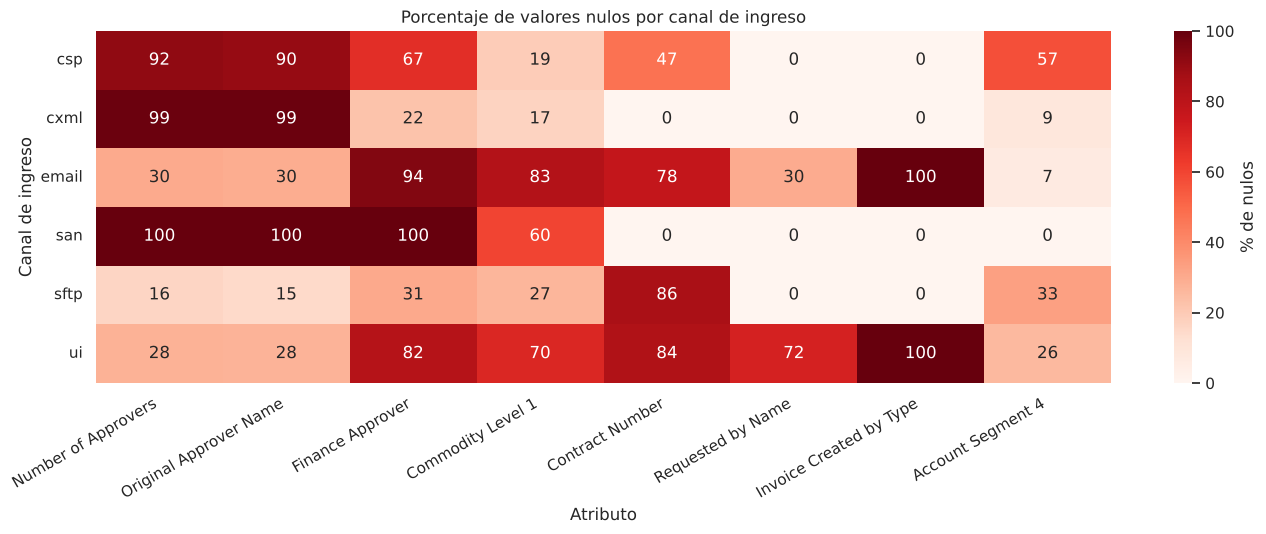

,facturas,Number of Approvers,Original Approver Name,Finance Approver,Commodity Level 1,Contract Number,Requested by Name,Invoice Created by Type,Account Segment 4
Invoice Channel,,,,,,,,,
csp,34242,91.60,90.50,66.90,19.50,47.30,0.00,0.00,57.00
cxml,3318,98.90,98.90,22.40,17.10,0.10,0.00,0.00,8.50
email,5744,30.20,29.50,94.20,82.70,77.70,30.00,100.00,6.50
san,5,100.00,100.00,100.00,60.00,0.00,0.00,0.00,0.00
sftp,17805,16.30,14.50,30.50,26.60,85.70,0.10,0.00,33.40
ui,14517,28.00,27.60,82.20,69.60,83.90,71.50,100.00,25.60


In [15]:
# ¿Los nulos son aleatorios o dependen del proceso? Se cruza el % de nulos con el canal de ingreso
cols_nulos = ["Number of Approvers", "Original Approver Name", "Finance Approver", "Commodity Level 1",
              "Contract Number", "Requested by Name", "Invoice Created by Type", "Account Segment 4"]
nulos_canal = df.groupby("Invoice Channel")[cols_nulos].apply(lambda g: g.isna().mean() * 100)
nulos_canal.insert(0, "facturas", df["Invoice Channel"].value_counts())
plt.figure(figsize=(14, 5.5))
sns.heatmap(nulos_canal.drop(columns="facturas"), annot=True, fmt=".0f", cmap="Reds", vmin=0, vmax=100,
            cbar_kws={"label": "% de nulos"})
plt.title("Porcentaje de valores nulos por canal de ingreso")
plt.xlabel("Atributo"); plt.ylabel("Canal de ingreso"); plt.yticks(rotation=0); plt.xticks(rotation=30, ha="right")
plt.tight_layout(); plt.show()
nulos_canal.round(1)

El mapa de calor muestra que los nulos dependen del canal por el que entra la factura. Number of Approvers está vacío en 91,6% de las facturas del portal de proveedores (csp) y en 98,9% de las de cxml, mientras que en sftp solo falta en 16,3%. Las facturas del portal y de cxml se emiten contra una orden de compra que ya fue aprobada, así que normalmente no pasan por una cadena de aprobación propia. En este caso el nulo describe el proceso y no es un dato que se haya perdido.

Lo mismo pasa con Invoice Created by Type, que está vacío en el 100% de las facturas de email y ui y en 0% de las demás, porque en esos canales la factura la crea el personal interno. Por su parte, Requested by Name falta sobre todo en ui (71,5%) y en email (30,0%), y el contrato falta en 85,7% de sftp y 83,9% de ui. Ambos patrones son coherentes con facturas que no tienen orden de compra.

Esto tiene una consecuencia directa para la hipótesis 2 del punto 4. Que una factura no tenga aprobador no quiere decir que no haya tenido control, en muchos casos solo quiere decir que se emitió contra una orden de compra.

In [16]:
# Tratamiento de completitud (cada decisión se justifica en el texto)
# a) Invoice Created by Type: es nulo solo en email y ui, donde la factura la digita personal interno (regla determinística)
print(pd.crosstab(df["Invoice Channel"], df["Invoice Created by Type"].fillna("NULO")))
df["creada_por"] = df["Invoice Created by Type"].fillna("InternalUser")

# b) Contract Number: nulo significa factura sin contrato asociado, así que se crea una variable binaria
df["tiene_contrato"] = df["Contract Number"].notna()

# c) Number of Approvers: nulo = la factura no pasó por cadena de aprobación propia; se deja nulo y se crea bandera
df["sin_cadena_aprobacion"] = df["Number of Approvers"].isna()

# d) Commodity: nulo significa factura sin categoría (casi siempre sin orden de compra), así que se crea una categoría explícita
for c in ["Commodity Level 1", "Commodity Level 2", "Commodity Name"]:
    df[c] = df[c].fillna("Sin categoría")

Invoice Created by Type  ApiUser  CxmlUser   NULO  SupplierUser
Invoice Channel                                                
csp                            0         0      0         34242
cxml                           0      3318      0             0
email                          0         0   5744             0
san                            0         0      0             5
sftp                       17805         0      0             0
ui                             0         0  14517             0


**Decisiones de completitud**

| Atributo | Tipo de nulo | Decisión |
|---|---|---|
| Invoice Created by Type | Estructural (email y ui) | Se imputa con la regla InternalUser en la columna creada_por. La tabla cruzada muestra que la relación entre canal y tipo de creador es exacta, así que la imputación no inventa información. |
| Contract Number | Tiene significado | No es un error, así que se crea la variable tiene_contrato. |
| Number of Approvers | Depende del proceso y, como se ve en la sección 5, también del resultado | Se deja nulo y se crea la bandera sin_cadena_aprobacion. No se imputa con 0 ni con la moda porque eso cambiaría su significado. |
| Commodity Level 1, 2 y Name | Facturas sin orden de compra | Se crea la categoría Sin categoría para no perder estas facturas en el gasto por categoría. |
| Aprobadores y solicitante | Depende del proceso | Se conservan nulos, porque no hay una forma confiable de reconstruirlos. |

### 3.2 Conformidad (sintaxis y dominio)

In [ ]:
# Conformidad: ¿los valores cumplen el formato esperado?
# Nombre del proveedor (formato NOMBRE_ENTIDAD_CÓDIGO)
print(df["prov_formato"].value_counts(dropna=False), "\n")
print("Filas sin llave de proveedor tras la imputación:", df["proveedor_id"].isna().sum(), "\n")

# Account Segment 1 debería ser un transit de 5 dígitos
patron_seg1 = (df["Account Segment 1"].str.replace(r"[0-9]", "9", regex=True)
               .str.replace(r"[A-Za-z]", "A", regex=True))
print("Patrones de Account Segment 1:")
print(patron_seg1.value_counts(dropna=False).head(8))
df["seg1_es_transit"] = df["Account Segment 1"].str.fullmatch(r"\d{5}", na=False)

# Number of Approvers = 0 aunque la factura tiene aprobadores registrados
cero_aprob = df["Number of Approvers"].eq(0)
print("\nFacturas con Number of Approvers = 0:", cero_aprob.sum(),
      "| de ellas con Finance Approver informado:", (cero_aprob & df["Finance Approver"].notna()).sum())

# Código de moneda vs nombre de moneda (debe ser 1 a 1)
print("Códigos de moneda con más de un nombre:",
      df.groupby("Invoice Currency Code")["Invoice Currency Name"].nunique().gt(1).sum())

prov_formato
estándar                            75578
nulo                                   42
nombre repetido entre paréntesis       10
sin entidad ni código                   1
Name: count, dtype: int64 

Filas sin llave de proveedor tras la imputación: 42 

Patrones de Account Segment 1:
Account Segment 1
99999        48280
AA999999     13910
AAAA9999     11823
NaN            917
AA999999A      583
AAAAAAAA        51
AAAAA999        34
9               21
Name: count, dtype: int64

Facturas con Number of Approvers = 0: 23 | de ellas con Finance Approver informado: 12
Códigos de moneda con más de un nombre: 0


In [18]:
# Number of Approvers = 0 con aprobadores registrados es imposible: se trata como nulo (no como "0 aprobadores")
df["n_aprobadores"] = df["Number of Approvers"].where(~cero_aprob, np.nan)
df.loc[cero_aprob, "sin_cadena_aprobacion"] = True
print("Valores 0 convertidos a nulo:", cero_aprob.sum())

Valores 0 convertidos a nulo: 23


En el nombre del proveedor solo 53 facturas no cumplen el formato estándar (42 nulas, 10 con el nombre repetido entre paréntesis y 1 sin código). Después de la extracción con expresiones regulares y de la imputación de la sección 1.2, solo quedan sin llave las 42 nulas.

Account Segment 1 tiene un problema a nivel de columna. Por el nombre del reporte se esperaría que fuera el transit (un código de área de 5 dígitos), pero solo 48.280 valores tienen ese formato. Los demás son códigos de proyecto con otro patrón (AA999999 en 13.910 casos, AAAA9999 en 11.823 y otros) y 917 están vacíos, así que en la misma columna se guardan dos tipos de dato distintos según el plan de cuentas. Por eso se crea la bandera seg1_es_transit y los análisis por área usan solo los transits válidos.

Además, hay 23 facturas con Number of Approvers igual a 0 y 12 de ellas tienen un aprobador financiero registrado. Un 0 contradice el propio campo, que queda vacío cuando no hay cadena de aprobación. Igual que pasó en el parcial con kms_run = 0, un valor imposible se trata como nulo y no como un dato válido. Por último, cada código de moneda tiene un solo nombre, así que en la moneda no hay problemas de conformidad.

### 3.3 Consistencia (entre atributos y con el proceso)

El monto en CAD debería ser igual al monto original multiplicado por la tasa de cambio. Como el reporte no trae la tasa, se calcula la tasa implícita de cada factura y se compara con la mediana de su moneda en el mismo mes.

In [19]:
# Consistencia entre atributos: monto en CAD = monto original x tasa de cambio
df["tasa_implicita"] = df[MONTO] / df[MONTO_ORIG]
df["tasa_mediana_mes"] = df.groupby(["Invoice Currency Code", "mes"])["tasa_implicita"].transform("median")
df["desvio_tasa"] = df["tasa_implicita"] / df["tasa_mediana_mes"] - 1

print("Tasa implícita por moneda (mediana y rango):")
print(df.groupby("Invoice Currency Code")["tasa_implicita"].agg(["count", "median", "min", "max"]).round(4))
fx_inconsistente = df["desvio_tasa"].abs() > 0.10
print("\nFacturas cuya tasa se aleja más de 10% de la mediana de su moneda en el mes:", fx_inconsistente.sum())
df.loc[fx_inconsistente, ["Invoice Currency Code", "mes", MONTO_ORIG, MONTO, "tasa_implicita",
                          "tasa_mediana_mes", "Invoice Status"]].assign(mes=lambda t: t["mes"].map(mes_es))

Tasa implícita por moneda (mediana y rango):
                       count  median  min  max
Invoice Currency Code                         
AUD                        2    0.99 0.98 0.99
BSD                       17    1.41 1.36 1.44
CAD                    60318    1.00 0.85 1.09
CHF                        4    1.75 1.75 1.77
COP                     2498    0.00 0.00 0.00
DOP                     1264    0.02 0.02 0.03
EUR                      231    1.60 1.30 1.64
GBP                      558    1.85 1.58 1.90
JMD                        1    0.01 0.01 0.01
JPY                        1    0.01 0.01 0.01
KYD                        1    1.63 1.63 1.63
MXN                        3    0.08 0.08 0.08
SGD                       17    1.07 1.04 1.08
USD                    10716    1.38 1.00 1.47

Facturas cuya tasa se aleja más de 10% de la mediana de su moneda en el mes: 3


,Invoice Currency Code,mes,Invoice Total with Tax Amount,Invoice total with tax (CAD),tasa_implicita,tasa_mediana_mes,Invoice Status
66816,USD,abr 2026,"88,057.58","88,057.58",1.00,1.38,approved
66829,USD,abr 2026,"136,687.21","136,687.21",1.00,1.38,approved
71719,CAD,jun 2026,"104,986.00","89,731.62",0.85,1.00,approved


Las tasas implícitas son muy estables dentro de cada moneda (por ejemplo, el USD tiene una mediana de 1,38 CAD), lo que muestra que casi todas las conversiones se hicieron bien. Solo 3 facturas se alejan más de 10% de la tasa de su mes. Dos son facturas en USD de abril de 2026 que se convirtieron uno a uno, así que su monto en CAD quedó subestimado, y la otra es una factura en CAD de junio de 2026 con tasa 0,85, cuando una factura en CAD debería tener tasa 1.

In [20]:
# Regla clara de corrección: se recalcula el monto en CAD con la tasa mediana del mes y la moneda
df["monto_cad"] = df[MONTO].copy()
df.loc[fx_inconsistente, "monto_cad"] = df.loc[fx_inconsistente, MONTO_ORIG] * df.loc[fx_inconsistente, "tasa_mediana_mes"]
df["fx_corregido"] = fx_inconsistente

# Con el monto corregido, ¿alguna factura queda por debajo del umbral de 10.000 CAD que define la población?
bajo_umbral = df["monto_cad"] < 10_000
print("Facturas que quedan bajo 10.000 CAD tras corregir la tasa:", bajo_umbral.sum())
df["fuera_de_poblacion"] = bajo_umbral
df.loc[fx_inconsistente, [MONTO, "monto_cad", "fuera_de_poblacion"]]

Facturas que quedan bajo 10.000 CAD tras corregir la tasa: 0


,Invoice total with tax (CAD),monto_cad,fuera_de_poblacion
66816,"88,057.58","121,185.99",False
66829,"136,687.21","188,110.72",False
71719,"89,731.62","104,986.00",False


En este caso sí existe una regla clara para corregir, que es usar la tasa del mes de esa moneda, así que se recalcula el monto en CAD en la columna monto_cad. Las dos facturas en USD pasan de 88.058 a 121.186 CAD y de 136.687 a 188.111 CAD, y la de CAD vuelve a su monto original de 104.986. Ninguna queda por debajo del umbral de 10.000 CAD, así que todas siguen en la población. Desde aquí todos los análisis usan monto_cad.

In [21]:
# Consistencia del proceso: canal, método de creación y tipo de usuario creador
print(pd.crosstab(df["Creation Method"], df["Invoice Channel"]), "\n")
combos = df.groupby("Creation Method")["Invoice Channel"].nunique()
print("Métodos de creación asociados a más de un canal:", (combos > 1).sum())

Invoice Channel       csp  cxml  email  san   sftp    ui
Creation Method                                         
actionemail             0     0      0    5      0     0
ap_invoice_copy         0     0      0    0      0    10
buyer_load              0     0      0    0  17805     0
csp_create           2399     0      0    0      0     0
csp_po_flip         30662     0      0    0      0     0
csp_resubmit         1181     0      0    0      0     0
cxml                    0  3318      0    0      0     0
data_table_load         0     0      0    0      0  3259
enterprise_po_flip      0     0      0    0      0  2076
enterprise_ui           0     0      0    0      0  8619
form                    0     0      0    0      0   553
inbound_invoice         0     0   5744    0      0     0 

Métodos de creación asociados a más de un canal: 0


El canal, el método de creación y el tipo de creador forman una jerarquía consistente. Cada método de creación pertenece a un solo canal, por ejemplo buyer_load siempre llega por sftp y csp_resubmit siempre por el portal. No hay nada que corregir y esto confirma que el canal resume bien de dónde viene cada factura.

In [22]:
# Segregación de funciones: solicitante = aprobador original, por canal y número de aprobadores
sod = pd.crosstab(df["Invoice Channel"], df["solicitante_es_aprobador"], normalize="index") * 100
sod["facturas_solicitante_es_aprobador"] = pd.crosstab(df["Invoice Channel"], df["solicitante_es_aprobador"])[True]
print(sod.round(1), "\n")
print(pd.crosstab(df["n_aprobadores"].fillna(-1).clip(upper=4).map(
        {-1: "sin dato", 1: "1", 2: "2", 3: "3", 4: "4 o más"}), df["solicitante_es_aprobador"]))

solicitante_es_aprobador  False  True  facturas_solicitante_es_aprobador
Invoice Channel                                                         
csp                       96.80  3.20                               1087
cxml                      99.50  0.50                                 17
email                     71.20 28.80                               1657
san                      100.00  0.00                                  0
sftp                      72.20 27.80                               4951
ui                        95.40  4.60                                661 

solicitante_es_aprobador  False  True 
n_aprobadores                         
1                          4362    483
2                          4073   3229
3                          6184   1974
4 o más                    9587   2352
sin dato                  43052    335


La coincidencia entre solicitante y aprobador original no se reparte al azar. Aparece en 27,8% de las facturas de sftp y 28,8% de las de email, mientras que en el portal solo aparece en 3,2%, y se concentra en facturas con 2 aprobadores (3.229 de 7.302). Este patrón es compatible con que, en las facturas sin orden de compra, el sistema asigne al solicitante como primer aprobador y después siga con el resto de la cadena. Si es así, sería una regla del flujo y no una autoaprobación indebida.

Por eso no se trata como un error. Se conserva como la bandera solicitante_es_aprobador, la regla se valida con el stakeholder y en la sección 5.3 se prueba si se asocia con los candidatos a duplicado.

### 3.4 Precisión: verificación de los montos extremos

Antes de calcular cualquier estadístico o correlación se revisan uno por uno los montos más altos. En cada caso se mira el estado de la factura, la moneda, si el proveedor es intragrupo y cuántas veces supera la mediana de su proveedor (veces_mediana_proveedor).

In [23]:
# Precisión: verificación caso a caso de los montos más extremos ANTES de usarlos en estadísticas o correlaciones
med_prov = df[df["Invoice Status"] == "approved"].groupby("proveedor_id")["monto_cad"].median()
n_prov = df[df["Invoice Status"] == "approved"].groupby("proveedor_id").size()
df["veces_mediana_proveedor"] = df["monto_cad"] / df["proveedor_id"].map(med_prov)
df["facturas_aprobadas_proveedor"] = df["proveedor_id"].map(n_prov).fillna(0)

top = df.nlargest(12, "monto_cad")[["proveedor_id", "prov_intragrupo", "prov_entidad", "Invoice Status",
                                     "Invoice Currency Code", "monto_cad", "veces_mediana_proveedor",
                                     "facturas_aprobadas_proveedor", "Invoice Channel", "Commodity Level 1"]]
top

,proveedor_id,prov_intragrupo,prov_entidad,Invoice Status,Invoice Currency Code,monto_cad,veces_mediana_proveedor,facturas_aprobadas_proveedor,Invoice Channel,Commodity Level 1
21744,PROV_1634,True,10001,voided,CAD,"1,070,691,117.00","17,295.32",597.00,sftp,Sin categoría
75454,PROV_1347,False,10001,draft,USD,"660,009,372.21",424.07,143.00,ui,Sin categoría
15966,PROV_0593,False,10001,approved,CAD,"134,955,900.00","2,741.89",523.00,ui,Software
69295,PROV_0173,True,10001,voided,CAD,"114,061,010.00",402.02,14.00,ui,Operations
75466,PROV_0420,False,10001,draft,USD,"88,259,535.41","1,466.03",59.00,ui,Sin categoría
75390,PROV_0593,False,10001,draft,CAD,"61,033,683.46","1,240.02",523.00,ui,Sin categoría
63623,PROV_3284,False,40048,voided,EUR,"50,983,013.76",NaN,0.00,csp,Sin categoría
70342,PROV_0699,False,10001,approved,CAD,"40,801,578.24",563.53,563.00,csp,Software
7922,PROV_0699,False,10001,approved,CAD,"34,584,632.60",477.66,563.00,csp,Software
63142,PROV_0758,True,10001,voided,CAD,"34,258,000.00",168.62,282.00,ui,Sin categoría


Entre los 12 montos más altos hay facturas que no fueron aprobadas (anuladas y borradores) y facturas aprobadas de proveedores de software que tienen cientos de facturas. La primera fila llama la atención, con 1.070 millones de CAD y 17.295 veces la mediana de su proveedor, así que se revisa en la siguiente celda.

In [24]:
# El caso más extremo: ¿el monto tiene sentido en la moneda declarada?
caso = df.loc[df["monto_cad"].idxmax()]
hist_prov = df[(df["proveedor_id"] == caso["proveedor_id"]) & (df.index != caso.name)]
print("Moneda declarada:", caso["Invoice Currency Code"], "| entidad del proveedor:", caso["prov_entidad"],
      "| intragrupo:", caso["prov_intragrupo"], "| estado:", caso["Invoice Status"])
print(f"Monto declarado: {caso['monto_cad']:,.0f} CAD")
print("Otras facturas del mismo proveedor:", len(hist_prov),
      f"| mediana {hist_prov['monto_cad'].median():,.0f} CAD | máximo {hist_prov['monto_cad'].max():,.0f} CAD")
print("Monedas usadas por el proveedor:", hist_prov["Invoice Currency Code"].value_counts().to_dict())
tasa_cop = df.loc[(df["Invoice Currency Code"] == "COP") & (df["mes"] == caso["mes"]), "tasa_implicita"].median()
print(f"Si el monto estuviera en COP equivaldría a {caso[MONTO_ORIG] * tasa_cop:,.0f} CAD")

Moneda declarada: CAD | entidad del proveedor: 10001 | intragrupo: True | estado: voided
Monto declarado: 1,070,691,117 CAD
Otras facturas del mismo proveedor: 619 | mediana 61,151 CAD | máximo 578,786 CAD
Monedas usadas por el proveedor: {'COP': 609, 'CAD': 10}
Si el monto estuviera en COP equivaldría a 346,422 CAD


La factura de 1.070.691.117 CAD no tiene sentido en la moneda que declara. Está registrada en CAD, pero es de una entidad del mismo grupo cuyas otras 619 facturas están casi todas en pesos colombianos (609 en COP y 10 en CAD). La mediana de ese proveedor es 61.151 CAD y su máximo es 578.786 CAD. Si el monto estuviera en COP equivaldría a unos 346.422 CAD, un valor coherente con su historia. Además la factura está anulada, lo que sugiere que el mismo Banco detectó el error.

Por eso se clasifica como un error de moneda (precisión, a nivel de atributo) y su monto pasa a nulo. No se reemplaza por el valor en COP porque eso sería suponer una moneda que no está confirmada. Como la factura está anulada no afecta el gasto aprobado, pero sí distorsionaría cualquier estadística de las facturas anuladas o de los montos en general, como se ve en la siguiente celda.

La revisión no se puede quedar solo en el caso más grande, así que se define una regla que se aplica a todas las facturas por encima del percentil 99,9. Un extremo se considera verificado por recurrencia si el mismo proveedor factura montos parecidos (más o menos 15%) al menos otras dos veces. Es lo que pasa con las licencias o los servicios recurrentes de gran tamaño, donde el monto es alto pero es el normal para ese proveedor. Si no hay esa recurrencia, el extremo queda como no verificado: se excluye de las correlaciones y las pruebas, se conserva en el gasto total si fue aprobado y se lleva a validación con el Banco.

In [25]:
# Regla de verificación de extremos, aplicada a TODAS las facturas por encima del percentil 99,9:
#  error_monto: monto inverosímil para la moneda declarada (caso verificado arriba), pasa a nulo
#  extremo verificado: el proveedor factura montos similares (±15%) al menos otras 2 veces (patrón recurrente,
#    por ejemplo licencias o servicios anuales), se conserva en todos los análisis
#  extremo_no_verificado: no hay recurrencia que lo respalde, se excluye de correlaciones y pruebas,
#    se conserva en el gasto total y se lleva a validación con el Banco
p999 = df[MONTO].quantile(0.999)
df["error_monto"] = False
df.loc[caso.name, "error_monto"] = True

def montos_similares(fila, tolerancia=0.15):
    otros = df.loc[(df["proveedor_id"] == fila["proveedor_id"]) & (df.index != fila.name), "monto_cad"]
    return int(((otros - fila["monto_cad"]).abs() <= tolerancia * fila["monto_cad"]).sum())

extremos = df[(df["monto_cad"] > p999) & ~df["error_monto"]].copy()
extremos["montos_similares_del_proveedor"] = extremos.apply(montos_similares, axis=1)
extremos["verificado_por_recurrencia"] = extremos["montos_similares_del_proveedor"] >= 2
df["extremo_no_verificado"] = df.index.isin(extremos.index[~extremos["verificado_por_recurrencia"]])

print(f"Percentil 99,9 del monto: {p999:,.0f} CAD | facturas por encima (sin el error): {len(extremos)}")
print("Verificadas por recurrencia:", extremos["verificado_por_recurrencia"].sum(),
      "| no verificadas:", (~extremos["verificado_por_recurrencia"]).sum())
print(extremos.loc[~extremos["verificado_por_recurrencia"],
                   ["proveedor_id", "Invoice Status", "monto_cad", "veces_mediana_proveedor",
                    "montos_similares_del_proveedor"]].sort_values("monto_cad", ascending=False))

# ¿Cuánto distorsiona el error si no se trata? Ejemplo con las facturas anuladas de todo el periodo
anuladas = df[df["Invoice Status"] == "voided"]
print(f"\nFacturas anuladas, media con el error: {anuladas['monto_cad'].mean():,.0f} CAD | "
      f"sin el error: {anuladas.loc[~anuladas['error_monto'], 'monto_cad'].mean():,.0f} CAD | "
      f"suma con el error: {anuladas['monto_cad'].sum() / 1e6:,.0f} M | sin el error: "
      f"{anuladas.loc[~anuladas['error_monto'], 'monto_cad'].sum() / 1e6:,.0f} M")

# Decisión: el monto con error pasa a nulo
df.loc[df["error_monto"], "monto_cad"] = np.nan

Percentil 99,9 del monto: 17,527,986 CAD | facturas por encima (sin el error): 75
Verificadas por recurrencia: 57 | no verificadas: 18
      proveedor_id Invoice Status      monto_cad  veces_mediana_proveedor  montos_similares_del_proveedor
75454    PROV_1347          draft 660,009,372.21                   424.07                               0
15966    PROV_0593       approved 134,955,900.00                 2,741.89                               0
69295    PROV_0173         voided 114,061,010.00                   402.02                               0
75466    PROV_0420          draft  88,259,535.41                 1,466.03                               0
75390    PROV_0593          draft  61,033,683.46                 1,240.02                               0
63623    PROV_3284         voided  50,983,013.76                      NaN                               0
70342    PROV_0699       approved  40,801,578.24                   563.53                               0
63142    PROV_075

El percentil 99,9 es 17.527.986 CAD y, sin contar el error, hay 75 facturas por encima. De ellas, 57 están verificadas por recurrencia y 18 no. Entre las 18 no verificadas hay borradores y anuladas, como el borrador de 660 millones de CAD, y también algunas aprobadas, como una de 134,96 millones de CAD que es 2.742 veces la mediana de su proveedor. Ninguna se declara error porque no hay evidencia para hacerlo, pero tampoco entran a las correlaciones sin verificar.

La última parte de la salida muestra por qué era importante tratar el error. Con la factura de 1.070 millones, la media de las facturas anuladas es 544.451 CAD y su suma es 2.246 millones; sin ella, la media baja a 285.021 CAD y la suma a 1.176 millones. Una sola factura casi duplica el total anulado.

### 3.5 Unicidad: duplicados de facturas y del maestro de proveedores

Esta parte es la más importante para el producto de datos. Se revisan los duplicados exactos, los duplicados aproximados por número de factura, los duplicados aproximados por monto y los duplicados en el maestro de proveedores.

In [26]:
# Unicidad (nivel tabla): duplicados exactos y por número de factura
print("Filas duplicadas exactas:", df.duplicated(subset=[c for c in df.columns if c != "mes"]).sum())
print("Números de factura repetidos dentro del mismo proveedor:",
      df.dropna(subset=["num_factura_original"]).duplicated(["proveedor_id", "num_factura_original"]).sum())

# Duplicados aproximados: el mismo número de factura una vez normalizado (sin espacios, guiones, ceros a la izquierda)
con_num = df.dropna(subset=["num_factura_norm", "proveedor_id"])
colision = con_num[con_num.duplicated(["proveedor_id", "num_factura_norm"], keep=False)]
grupos = colision.groupby(["proveedor_id", "num_factura_norm"]).agg(
    facturas=("Invoice Status", "size"),
    estados=("Invoice Status", lambda s: " + ".join(sorted(s))),
    montos_distintos=("monto_cad", "nunique"),
    monto_cad_max=("monto_cad", "max"),
    monto_cad_total=("monto_cad", "sum"))
print("Facturas en colisión de número normalizado:", len(colision), "| grupos:", len(grupos))
grupos["estados"].value_counts().to_frame("grupos")

Filas duplicadas exactas: 0
Números de factura repetidos dentro del mismo proveedor: 0
Facturas en colisión de número normalizado: 321 | grupos: 158


,grupos
estados,
approved + voided,95
approved + approved,26
voided + voided,17
approved + disputed,9
approved + voided + voided,3
approved + pending_receipt,2
approved + on_hold,2
approved + approved + approved,1
approved + on_hold + on_hold,1


No hay duplicados exactos y ningún número de factura se repite dentro de un proveedor, porque el sistema lo impide. Sin embargo, el control se puede evadir cambiando muy poco el número. Al normalizar los números (quitando espacios, guiones, puntos y ceros a la izquierda), 321 facturas de 158 grupos coinciden con otra factura del mismo proveedor.

La mayoría de estos grupos (95) son una factura aprobada y otra anulada. Ese es el patrón normal de una corrección: el proveedor manda una factura con un error, se anula y la vuelve a mandar con el número un poco cambiado, así que no es un pago duplicado. Los casos que más interesan son los 27 grupos donde todas las facturas están aprobadas (26 pares y un trío), y se revisan a continuación.

In [27]:
# Lo más relevante para el negocio: colisiones donde TODAS las facturas fueron aprobadas
aprob = grupos[grupos["estados"].str.fullmatch(r"approved( \+ approved)+")].copy()
aprob["mismo_monto"] = aprob["montos_distintos"].eq(1)
aprob["monto_cad_adicional"] = aprob["monto_cad_total"] - aprob["monto_cad_max"]   # lo pagado de más si fueran duplicados
# Facturas aprobadas que comparten número normalizado con al menos otra factura APROBADA (las anuladas no cuentan)
n_aprob_grupo = colision.groupby(["proveedor_id", "num_factura_norm"])["Invoice Status"].transform(lambda s: (s == "approved").sum())
colision_aprob_idx = colision.index[(colision["Invoice Status"] == "approved") & (n_aprob_grupo >= 2)]
print("Facturas aprobadas en grupos con dos o más aprobadas:", len(colision_aprob_idx))
print("Grupos con todas las facturas aprobadas:", len(aprob))
print("…de ellos con el mismo monto:", aprob["mismo_monto"].sum())
print(f"Monto potencialmente pagado dos veces (grupos con mismo monto): {aprob.loc[aprob['mismo_monto'], 'monto_cad_adicional'].sum():,.0f} CAD")

# Ejemplos sin exponer números reales: se muestra el patrón (A = letra, 9 = dígito)
ejemplos = colision.merge(aprob[aprob["mismo_monto"]].reset_index()[["proveedor_id", "num_factura_norm"]])
ejemplos.sort_values(["proveedor_id", "num_factura_norm"])[
    ["proveedor_id", "num_factura_patron", "Invoice Created Date", "monto_cad", "Invoice Channel"]].head(10).assign(
    **{"Invoice Created Date": lambda t: t["Invoice Created Date"].dt.strftime("%d/%m/%Y")})

Facturas aprobadas en grupos con dos o más aprobadas: 55
Grupos con todas las facturas aprobadas: 27
…de ellos con el mismo monto: 6
Monto potencialmente pagado dos veces (grupos con mismo monto): 120,379 CAD


,proveedor_id,num_factura_patron,Invoice Created Date,monto_cad,Invoice Channel
0,PROV_0606,9999AAAA99-999(A999A9),31/08/2022,"18,362.50",csp
1,PROV_0606,9999AAAA99-999 (A999A9),10/08/2022,"18,362.50",csp
10,PROV_0769,A999999,03/06/2026,"20,884.57",csp
11,PROV_0769,A-99-9999,22/06/2026,"20,884.57",sftp
2,PROV_0769,AA-99-9999,25/04/2023,"30,429.58",csp
3,PROV_0769,AA999999,11/04/2023,"30,429.58",csp
4,PROV_0940,999999999,06/10/2023,"15,405.98",csp
5,PROV_0940,99999999,06/10/2023,"15,405.98",csp
6,PROV_0940,99999999 A,23/02/2024,"19,194.00",csp
7,PROV_0940,99999999A,23/02/2024,"19,194.00",csp


De los 27 grupos con todas las facturas aprobadas, 6 tienen exactamente el mismo monto, y lo que se habría pagado de más si fueran duplicados suma 120.379 CAD. En los patrones de los números se ve cómo se evade el control: un espacio antes de un paréntesis, un guion que se quita, una letra final separada por un espacio o un cero a la izquierda. En uno de los casos la misma factura entró primero por el portal (csp) y 19 días después por sftp. Los otros 21 grupos tienen montos distintos, así que pueden ser facturas parciales o de periodos diferentes con una numeración parecida, y no necesariamente duplicados.

Con esto se crea la bandera num_factura_colision. Estos 6 grupos son los primeros casos para validar con el Banco y más adelante van a servir como positivos de referencia para evaluar el modelo.

Facturas aprobadas: 70651 | con una factura previa del mismo proveedor y monto: 17778
                        pares
dias_desde_mismo_monto       
0 (mismo día)            2702
1 a 7                    1400
8 a 20                   1453
21 a 40                  5940
41 a 75                  2112
76 a 100                 1241
101 a 200                1402
201 a 400                1256
más de 400                272


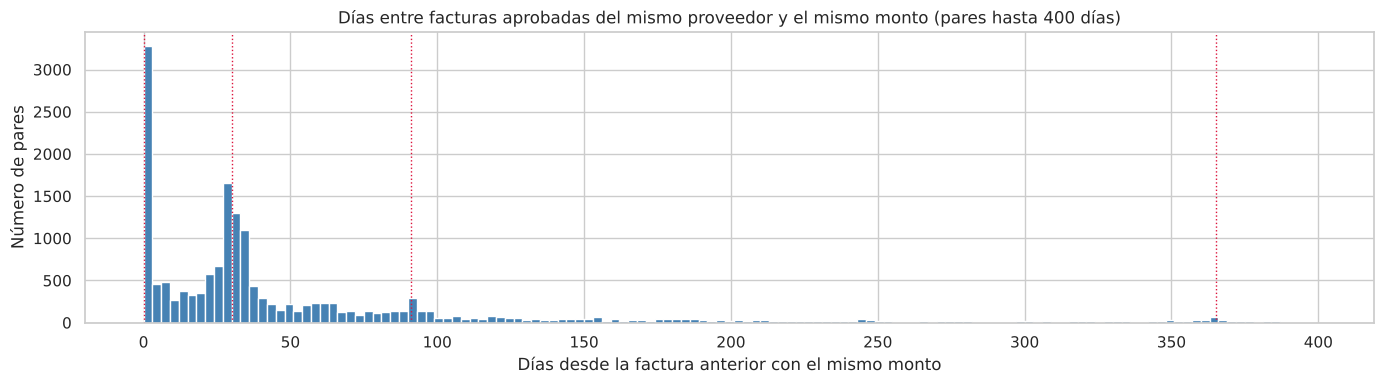

In [28]:
# Duplicados aproximados por monto: mismo proveedor, misma moneda y mismo monto original, entre facturas aprobadas
ap = df[(df["Invoice Status"] == "approved") & df["proveedor_id"].notna()].sort_values("Invoice Created Date").copy()
claves = ["proveedor_id", "Invoice Currency Code", MONTO_ORIG]
ap["dias_desde_mismo_monto"] = ap.groupby(claves)["Invoice Created Date"].diff().dt.days
ap["mismo_monto_mismo_transit"] = ap.duplicated(claves + ["Account Segment 1", "Invoice Created Date"], keep=False)

gaps = ap["dias_desde_mismo_monto"].dropna()
print("Facturas aprobadas:", len(ap), "| con una factura previa del mismo proveedor y monto:", len(gaps))
tramos = pd.cut(gaps, [-1, 0, 7, 20, 40, 75, 100, 200, 400, 2000],
                labels=["0 (mismo día)", "1 a 7", "8 a 20", "21 a 40", "41 a 75", "76 a 100", "101 a 200", "201 a 400", "más de 400"])
print(tramos.value_counts().sort_index().to_frame("pares"))

fig, ax = plt.subplots(figsize=(14, 4))
ax.hist(gaps[gaps <= 400], bins=range(0, 401, 3), color="steelblue")
for x in [0, 30, 91, 365]:
    ax.axvline(x, color="crimson", ls=":", lw=1)
ax.set_title("Días entre facturas aprobadas del mismo proveedor y el mismo monto (pares hasta 400 días)")
ax.set_xlabel("Días desde la factura anterior con el mismo monto"); ax.set_ylabel("Número de pares")
plt.tight_layout(); plt.show()

Que dos facturas tengan el mismo proveedor y el mismo monto no las vuelve duplicadas. De las 70.651 facturas aprobadas, 17.778 tienen una factura anterior del mismo proveedor con exactamente el mismo monto y la misma moneda. El histograma explica por qué: además del pico en el mismo día (2.702 pares), hay picos claros cerca de 30, 91 y 365 días, que corresponden a facturación mensual, trimestral y anual. Por ejemplo, 5.940 pares están separados entre 21 y 40 días, o sea que son cuotas recurrentes legítimas. En cambio, 1.400 pares están separados entre 1 y 7 días, un plazo que no encaja con una facturación periódica.

Para el modelo esto significa que la coincidencia de monto por sí sola daría miles de falsos positivos. Hacen falta variables que separen la recurrencia normal de un duplicado, como los días entre facturas, qué tanto se aleja ese intervalo de la periodicidad habitual del proveedor, qué tan parecido es el número de factura y si coinciden el transit y el canal.

In [29]:
# Los pares del mismo día: ¿son el mismo cargo duplicado o facturación en lote?
mismo_dia = ap[ap["dias_desde_mismo_monto"] == 0]
lote = ap[ap.duplicated(claves + ["Invoice Created Date"], keep=False)].copy()
g_lote = lote.groupby(claves + ["Invoice Created Date"]).agg(
    facturas=("monto_cad", "size"), transits=("Account Segment 1", "nunique"),
    monto_cad=("monto_cad", "first"))
print("Grupos mismo proveedor + mismo monto + mismo día:", len(g_lote))
print("…con todas las facturas en el mismo transit:", (g_lote["transits"] <= 1).sum())
print("…en transits distintos (probable reparto de un cargo entre áreas):", (g_lote["transits"] > 1).sum())
print("Tamaño de los grupos:", g_lote["facturas"].value_counts().sort_index().to_dict())

Grupos mismo proveedor + mismo monto + mismo día: 1888
…con todas las facturas en el mismo transit: 1372
…en transits distintos (probable reparto de un cargo entre áreas): 516
Tamaño de los grupos: {2: 1462, 3: 238, 4: 95, 5: 50, 6: 25, 7: 6, 8: 4, 9: 2, 10: 1, 11: 3, 13: 1, 24: 1}


Hay 1.888 grupos de facturas del mismo proveedor, con el mismo monto y del mismo día. En 516 de ellos las facturas se cargaron a transits distintos, lo que sugiere un mismo cargo repartido entre varias áreas. En los otros 1.372 todas las facturas van al mismo transit. La mayoría son pares (1.462), aunque hay grupos de hasta 24 facturas, que es un patrón típico de facturación en lote, cuando se facturan varias cuotas o periodos juntos. Este subconjunto es el de mayor riesgo, pero sin etiquetas no se puede saber cuántos son duplicados reales, así que se va a llevar una muestra al stakeholder para que la etiquete (ver próximos pasos).

In [ ]:
# Duplicados aproximados en el maestro de proveedores (nivel columna / tabla)
# Sinónimos: una misma llave con varios nombres
print("Llaves con más de una variante de nombre:", (variantes_por_llave > 1).sum(), "de", len(variantes_por_llave))

# Homónimos / posibles proveedores duplicados: un mismo nombre normalizado con varias llaves
multi = df.dropna(subset=["proveedor_id"]).groupby("grupo_nombre_id").agg(
    llaves=("proveedor_id", "nunique"), entidades=("prov_entidad", "nunique"),
    facturas=("proveedor_id", "size"), gasto_aprobado_cad=("monto_cad", lambda s: s[df.loc[s.index, "Invoice Status"] == "approved"].sum()))
multi = multi[multi["llaves"] > 1]
print("Nombres normalizados con más de una llave:", len(multi),
      "| misma entidad:", (multi["entidades"] == 1).sum(), "| entre entidades:", (multi["entidades"] > 1).sum())
print(f"Gasto aprobado asociado: {multi['gasto_aprobado_cad'].sum():,.0f} CAD "
      f"({multi['gasto_aprobado_cad'].sum() / df.loc[df['Invoice Status'] == 'approved', 'monto_cad'].sum():.1%} del total)")
multi.sort_values("gasto_aprobado_cad", ascending=False).head(8)

Llaves con más de una variante de nombre: 117 de 3354


Nombres normalizados con más de una llave: 122 | misma entidad: 22 | entre entidades: 100
Gasto aprobado asociado: 2,720,861,902 CAD (24.4% del total)


,llaves,entidades,facturas,gasto_aprobado_cad
grupo_nombre_id,,,,
GRUPO_1803,2,2,535,"412,687,225.42"
GRUPO_1543,2,2,717,"350,428,659.37"
GRUPO_0328,5,1,378,"197,142,141.18"
GRUPO_1936,2,2,42,"162,717,492.72"
GRUPO_2754,2,2,877,"152,137,976.13"
GRUPO_2247,2,2,440,"137,871,253.08"
GRUPO_0532,2,2,703,"134,770,060.70"
GRUPO_0631,2,2,463,"116,404,264.18"


En el maestro de proveedores hay dos situaciones. La primera son los sinónimos (a nivel de columna): 117 de las 3.354 llaves aparecen con más de un nombre, por ejemplo con y sin punto final o con la forma societaria abreviada. Como la llave es la entidad junto con el código y no el nombre, esto no fragmenta el gasto por proveedor.

La segunda son nombres con varias llaves (a nivel de tabla). Hay 122 nombres normalizados con más de una llave. En 100 casos las llaves están en entidades distintas, que es la misma empresa registrada en varias sociedades del Banco, algo esperable en un grupo multinacional. En 22 casos, en cambio, las llaves están en la misma entidad, y esos son los candidatos más claros a proveedor duplicado en el maestro. Uno de ellos (GRUPO_0328) tiene 5 llaves en la misma entidad y 197 millones de CAD aprobados. En total estos grupos concentran 2.720,9 millones de CAD, el 24,4% del gasto aprobado. Si no se consolidan, se subestima cuánto se le compra realmente a cada empresa, que es justo el riesgo que plantea el punto 1.

In [ ]:
# Nombres casi iguales (Levenshtein) dentro de la misma entidad: candidatos a ser el mismo proveedor
prov = (df.dropna(subset=["proveedor_id"]).groupby("proveedor_id")
          .agg(nombre=("prov_nombre_norm", "first"), entidad=("prov_entidad", "first"),
               facturas=("prov_nombre_norm", "size")).reset_index())
pares = []
for entidad, g in prov.groupby("entidad"):
    g = g.sort_values("nombre").reset_index(drop=True)
    nombres_g = g["nombre"].tolist()
    for i in range(len(g)):
        for j in range(i + 1, len(g)):
            if nombres_g[j][:3] != nombres_g[i][:3]:     # bloqueo por las 3 primeras letras (eficiencia)
                break
            r = ratio(nombres_g[i], nombres_g[j])
            if r >= 0.90:
                pares.append({"entidad": entidad, "prov_a": g.at[i, "proveedor_id"], "prov_b": g.at[j, "proveedor_id"],
                              "similitud": round(r, 3), "identico": nombres_g[i] == nombres_g[j]})
pares = pd.DataFrame(pares)
print("Pares de proveedores con similitud de nombre >= 0,90 en la misma entidad:", len(pares))
print("…nombre normalizado idéntico:", pares["identico"].sum(), "| casi idéntico (0,90 a 0,99):", (~pares["identico"]).sum())
pares.sort_values("similitud").head(8)

Pares de proveedores con similitud de nombre >= 0,90 en la misma entidad: 56
…nombre normalizado idéntico: 36 | casi idéntico (0,90 a 0,99): 20


,entidad,prov_a,prov_b,similitud,identico
43,10001,PROV_0857,PROV_2274,0.90,False
37,10001,PROV_0408,PROV_0095,0.91,False
18,10001,PROV_0537,PROV_0768,0.91,False
17,10001,PROV_0809,PROV_0537,0.91,False
21,10001,PROV_2646,PROV_2645,0.92,False
50,10001,PROV_0553,PROV_2440,0.93,False
6,10001,PROV_1228,PROV_2848,0.93,False
3,10001,PROV_2860,PROV_2516,0.94,False


Usando la similitud de Levenshtein, como en el tutorial de calidad, aparecen 56 pares de proveedores en la misma entidad con una similitud de 0,90 o más. De ellos, 36 tienen el nombre normalizado idéntico y 20 son casi idénticos (similitud entre 0,90 y 0,99). Estos 20 son justamente los que una búsqueda exacta no encontraría.

Con esto se crea grupo_nombre_id para consolidar el gasto por nombre normalizado. Las llaves no se fusionan automáticamente, porque dos empresas distintas pueden tener nombres parecidos (homónimos), así que la lista de pares se entrega al stakeholder para que confirme cuáles son la misma empresa.

### 3.6 Temporalidad: facturas que aún no tienen su estado final

In [32]:
# Temporalidad: el estado final de una factura tarda en llegar; las facturas recientes siguen abiertas
ult = df[df["Invoice Created Date"] >= "2025-12-01"]
estado_mes = pd.crosstab(ult["mes"].map(mes_es), ult["Invoice Status"].where(ult["Invoice Status"].isin(
    ["approved", "voided", "disputed"]), "sin resolver"), normalize="index") * 100
print(estado_mes.round(1))
print("\nFecha máxima de creación (corte de la extracción):", df["Invoice Created Date"].max().strftime("%d/%m/%Y"))

Invoice Status  approved  disputed  sin resolver  voided
mes                                                     
abr 2026           94.20      0.50          1.10    4.20
dic 2025           93.40      1.30          0.70    4.60
ene 2026           92.90      0.30          0.70    6.20
feb 2026           93.20      0.80          1.10    5.00
jul 2026           92.10      0.30          5.10    2.40
jun 2026           91.70      0.70          3.80    3.90
mar 2026           93.30      0.70          1.60    4.50
may 2026           93.80      0.50          1.60    4.00

Fecha máxima de creación (corte de la extracción): 20/07/2026


Entre diciembre de 2025 y mayo de 2026 las facturas sin resolver se mantienen entre 0,7% y 1,6%. En junio de 2026 suben a 3,8% y en julio a 5,1%, y en julio las anuladas bajan a 2,4% cuando en los meses anteriores estaban entre 4% y 6%. Esto pasa porque las facturas recientes no han tenido tiempo de anularse o disputarse. Si se incluyeran, parecería que la fricción baja cuando en realidad lo que falta es tiempo de observación. Por eso la ventana analítica termina el 31 de mayo de 2026.

### 3.7 Credibilidad y sesgo de selección

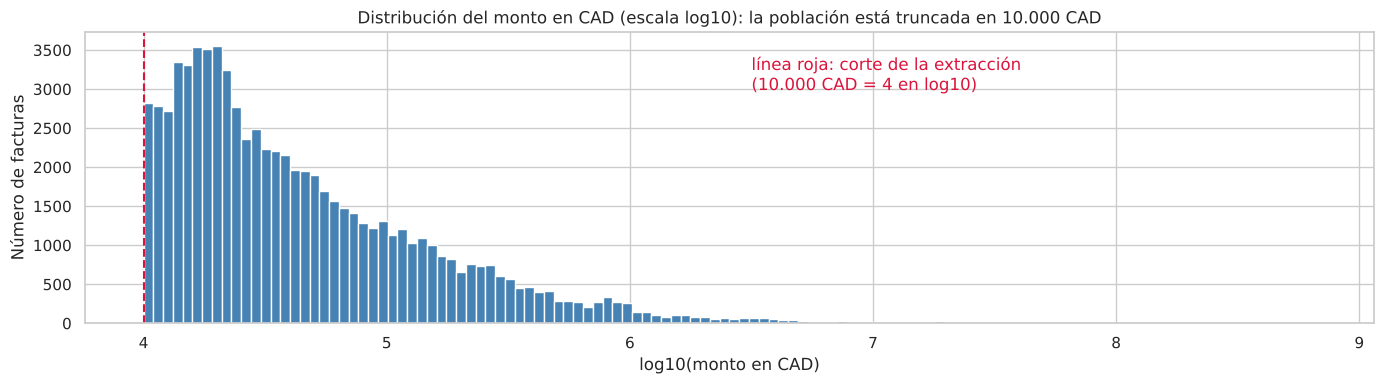

Facturas entre 10.000 y 10.500 CAD: 1608 | entre 10.500 y 11.000 CAD: 1338


In [33]:
# Credibilidad / sesgo de selección: la extracción solo trae facturas >= 10.000 CAD
fig, ax = plt.subplots(figsize=(14, 4))
ax.hist(np.log10(df["monto_cad"].dropna()), bins=120, color="steelblue")
ax.axvline(4, color="crimson", ls="--"); ax.text(6.5, ax.get_ylim()[1] * 0.8, "línea roja: corte de la extracción\n(10.000 CAD = 4 en log10)", color="crimson")
ax.set_title("Distribución del monto en CAD (escala log10): la población está truncada en 10.000 CAD")
ax.set_xlabel("log10(monto en CAD)"); ax.set_ylabel("Número de facturas")
plt.tight_layout(); plt.show()
print("Facturas entre 10.000 y 10.500 CAD:", df["monto_cad"].between(10_000, 10_500).sum(),
      "| entre 10.500 y 11.000 CAD:", df["monto_cad"].between(10_500, 11_000).sum())

La credibilidad de la fuente es alta, porque SmartBuy es el sistema oficial de registro de las compras y la extracción la entregó el área dueña del proceso. El problema está en otro lado: la población está truncada en 10.000 CAD. No hay ninguna factura por debajo del corte y la distribución empieza de forma abrupta en él. Tampoco hay una acumulación rara justo encima del umbral (1.608 facturas entre 10.000 y 10.500 CAD frente a 1.338 entre 10.500 y 11.000), lo que es coherente con un corte de la extracción y no con un comportamiento de los proveedores.

Esto afecta la hipótesis 1. El fraccionamiento de compras para quedar justo debajo de un umbral no se puede estudiar en el umbral de 10.000 CAD, porque no hay datos por debajo, ni tampoco en los umbrales internos de aprobación, porque no se conocen. Por eso se le va a pedir al Banco la tabla de niveles de aprobación por monto.

### 3.8 Resumen de calidad

In [34]:
resumen_calidad = pd.DataFrame([
    ["Número de aprobadores nulo (57%) y dependiente del canal", "Completitud", "Atributo", df["Number of Approvers"].isna().sum(), "Se conserva nulo + bandera sin_cadena_aprobacion; no se imputa", "Hipótesis 2 se analiza por canal, no como 'sin control'"],
    ["Categoría (commodity) nula en facturas sin orden de compra", "Completitud", "Atributo", (df["Commodity Level 1"] == "Sin categoría").sum(), "Categoría explícita 'Sin categoría'", "Se reporta aparte en el gasto por categoría"],
    ["Invoice Created by Type nulo en canales email y ui", "Completitud", "Atributo", df["Invoice Created by Type"].isna().sum(), "Imputación por regla: InternalUser", "Ninguno: regla determinística"],
    ["Contract Number nulo", "Completitud", "Atributo", (~df["tiene_contrato"]).sum(), "No es error: variable tiene_contrato", "Se usa como variable explicativa"],
    ["Proveedor sin entidad ni código o con nombre repetido entre paréntesis", "Conformidad", "Atributo", (df["prov_formato"] != "estándar").sum(), "Extracción por regex e imputación de la llave cuando el nombre es único", "Llave de proveedor completa salvo nulos"],
    ["Account Segment 1 mezcla transits (5 dígitos) con códigos de proyecto", "Conformidad", "Columna", (~df["seg1_es_transit"]).sum(), "Bandera seg1_es_transit", "El análisis por transit usa solo los válidos"],
    ["Number of Approvers = 0 con aprobadores registrados", "Conformidad / dominio", "Registro", int(cero_aprob.sum()), "Se convierte a nulo", "No contamina el conteo de aprobadores"],
    ["Tasa de cambio implícita inconsistente (>10%)", "Consistencia", "Registro", int(fx_inconsistente.sum()), "Recalcular CAD con la tasa mediana del mes", "Las que quedan < 10.000 CAD salen de la población"],
    ["Monto inverosímil para la moneda declarada", "Precisión", "Atributo", int(df["error_monto"].sum()), "Monto a nulo", "Excluido de estadísticas y correlaciones"],
    ["Montos > p99,9 sin recurrencia que los respalde", "Precisión", "Atributo", int(df["extremo_no_verificado"].sum()), "Excluidos de correlaciones y pruebas; conservados en el gasto total", "Se validan con el Banco"],
    ["Campos de aprobación se llenan solo si la factura completa la aprobación", "Consistencia con el proceso (fuga)", "Atributo", int(df["Number of Approvers"].isna().sum()), "No se usan para explicar la fricción; solo dentro de facturas aprobadas", "Evita una relación espuria con la etiqueta"],
    ["Número de factura casi idéntico (guion/espacio) en el mismo proveedor", "Unicidad", "Tabla", len(colision), "Bandera num_factura_colision", "Variable clave del modelo de duplicados"],
    ["Proveedor con varias variantes de nombre (sinónimos)", "Unicidad", "Columna", int((variantes_por_llave > 1).sum()), "La llave es entidad + código, no el nombre", "Gasto por proveedor no se fragmenta"],
    ["Mismo nombre normalizado con varias llaves", "Unicidad", "Tabla", len(multi), "grupo_nombre_id para consolidar gasto", "Validar con el Banco antes de fusionar"],
    ["Login o ID de aprobador con más de un nombre", "Unicidad (singularidad)", "Columna", int(logins_multinombre + ids_aprob_multinombre), "Se usa el seudónimo por nombre", "Impacto mínimo"],
    ["Estados sin resolver en las facturas recientes", "Temporalidad", "Registro", int(df["Invoice Status"].isin(pendientes).sum()), "Ventana analítica hasta mayo-2026", "Tasas de fricción sin sesgo por facturas abiertas"],
    ["Cambio de régimen en ago-2024 (canales, contratos, volumen)", "Consistencia temporal", "Tabla", int((df["Invoice Created Date"] < "2024-09-01").sum()), "Ventana analítica sep-2024 a may-2026; historia completa solo para antigüedad del proveedor", "Comparaciones entre periodos homogéneos"],
    ["Población truncada en 10.000 CAD", "Credibilidad / selección", "Tabla", len(df), "Se declara como limitación", "No se puede estudiar el fraccionamiento bajo 10.000 CAD"],
], columns=["problema", "dimensión", "nivel", "facturas", "decisión", "efecto en el análisis"])
resumen_calidad

,problema,dimensión,nivel,facturas,decisión,efecto en el análisis
0,Número de aprobadores nulo (57%) y dependiente...,Completitud,Atributo,43364,Se conserva nulo + bandera sin_cadena_aprobaci...,"Hipótesis 2 se analiza por canal, no como 'sin..."
1,Categoría (commodity) nula en facturas sin ord...,Completitud,Atributo,26827,Categoría explícita 'Sin categoría',Se reporta aparte en el gasto por categoría
2,Invoice Created by Type nulo en canales email ...,Completitud,Atributo,20261,Imputación por regla: InternalUser,Ninguno: regla determinística
3,Contract Number nulo,Completitud,Atributo,48100,No es error: variable tiene_contrato,Se usa como variable explicativa
4,Proveedor sin entidad ni código o con nombre r...,Conformidad,Atributo,53,Extracción por regex e imputación de la llave ...,Llave de proveedor completa salvo nulos
5,Account Segment 1 mezcla transits (5 dígitos) ...,Conformidad,Columna,27351,Bandera seg1_es_transit,El análisis por transit usa solo los válidos
6,Number of Approvers = 0 con aprobadores regist...,Conformidad / dominio,Registro,23,Se convierte a nulo,No contamina el conteo de aprobadores
7,Tasa de cambio implícita inconsistente (>10%),Consistencia,Registro,3,Recalcular CAD con la tasa mediana del mes,Las que quedan < 10.000 CAD salen de la población
8,Monto inverosímil para la moneda declarada,Precisión,Atributo,1,Monto a nulo,Excluido de estadísticas y correlaciones
9,"Montos > p99,9 sin recurrencia que los respalde",Precisión,Atributo,18,Excluidos de correlaciones y pruebas; conserva...,Se validan con el Banco


La tabla resume las 18 decisiones de calidad. En general los atributos de la factura tienen buena calidad: los montos y las monedas son consistentes (solo hubo 3 conversiones mal hechas y un error de moneda), las fechas están completas y la jerarquía de canales no tiene contradicciones. Los problemas importantes tienen más que ver con el proceso y el contexto que con errores de digitación. Está el cambio de régimen de agosto de 2024, los campos de aprobación que dependen del canal y del resultado, el maestro de proveedores con duplicados y la falta de una etiqueta de duplicado confirmado. Ninguno de estos problemas impide hacer el proyecto, pero todos influyen en cómo se construye y se evalúa el modelo.

## 4. Análisis univariado de los atributos clave

Se escogieron cinco atributos por su relación directa con los objetivos y las hipótesis. El monto en CAD (monto_cad) se escogió porque mide la exposición económica y es la base de H4 y de la detección de duplicados por monto. El estado de la factura (Invoice Status) se escogió porque es la única señal de resultado que hay y de él sale la variable de fricción. El canal de ingreso (Invoice Channel) resume de dónde viene cada factura y es clave para H2, igual que el número de aprobadores (Number of Approvers), que describe la cadena de control. Por último, el proveedor (proveedor_id) permite medir qué tan concentrado está el gasto y cuál es el riesgo por proveedor (H3 y objetivo 1).

Como complemento también se describen el transit, la categoría de compra, la moneda, la entidad y la evolución mensual del gasto. Desde aquí se trabaja con la ventana analítica definida en la sección 2.

In [35]:
# Bases de análisis (definidas a partir de las decisiones de calidad)
VENTANA_INI, VENTANA_FIN = "2024-09-01", "2026-06-01"
ESTADOS_FRICCION = ["voided", "disputed", "rejected"]

df["num_factura_colision"] = df.index.isin(colision.index)
en_ventana = (df["Invoice Created Date"] >= VENTANA_INI) & (df["Invoice Created Date"] < VENTANA_FIN)
base = df[en_ventana & ~df["fuera_de_poblacion"] & df["monto_cad"].notna()].copy()
aprobadas = base[base["Invoice Status"] == "approved"].copy()
resueltas = base[base["Invoice Status"].isin(["approved"] + ESTADOS_FRICCION)].copy()
resueltas["con_friccion"] = resueltas["Invoice Status"].isin(ESTADOS_FRICCION).astype(int)

print("Ventana analítica: 1 de septiembre de 2024 a 31 de mayo de 2026")
print(f"Facturas en la ventana: {len(base):,} | aprobadas: {len(aprobadas):,} | resueltas: {len(resueltas):,}")
print(f"Gasto aprobado en la ventana: {aprobadas['monto_cad'].sum() / 1e6:,.1f} millones de CAD")

Ventana analítica: 1 de septiembre de 2024 a 31 de mayo de 2026
Facturas en la ventana: 51,429 | aprobadas: 48,457 | resueltas: 51,187
Gasto aprobado en la ventana: 7,138.0 millones de CAD


La ventana analítica tiene 51.429 facturas. De ellas, 48.457 están aprobadas y 51.187 están resueltas (aprobadas, anuladas, disputadas o rechazadas). El gasto aprobado en la ventana es de 7.138,0 millones de CAD.

In [36]:
x = aprobadas["monto_cad"]
q1, q3 = x.quantile([.25, .75])
log_x = np.log10(x)
lq1, lq3 = log_x.quantile([.25, .75]); liqr = lq3 - lq1
estad = pd.Series({
    "facturas": len(x), "media": x.mean(), "mediana": x.median(), "desv_estandar": x.std(),
    "IQR": q3 - q1, "p5": x.quantile(.05), "Q1": q1, "Q3": q3,
    "p95": x.quantile(.95), "p99": x.quantile(.99), "máximo": x.max(),
    "asimetria": x.skew(), "curtosis": x.kurtosis(),
    "asimetria_log10": log_x.skew(),
    "pct_atipicos_IQR_escala_original": ((x > q3 + 1.5 * (q3 - q1)).mean() * 100),
    "pct_atipicos_IQR_escala_log": (((log_x > lq3 + 1.5 * liqr) | (log_x < lq1 - 1.5 * liqr)).mean() * 100),
})
estad.to_frame("monto_cad (facturas aprobadas)")

,monto_cad (facturas aprobadas)
facturas,"48,457.00"
media,"147,305.91"
mediana,"30,359.12"
desv_estandar,"817,774.98"
IQR,"62,138.41"
p5,"11,300.00"
Q1,"17,111.59"
Q3,"79,250.00"
p95,"467,706.55"
p99,"1,882,025.75"


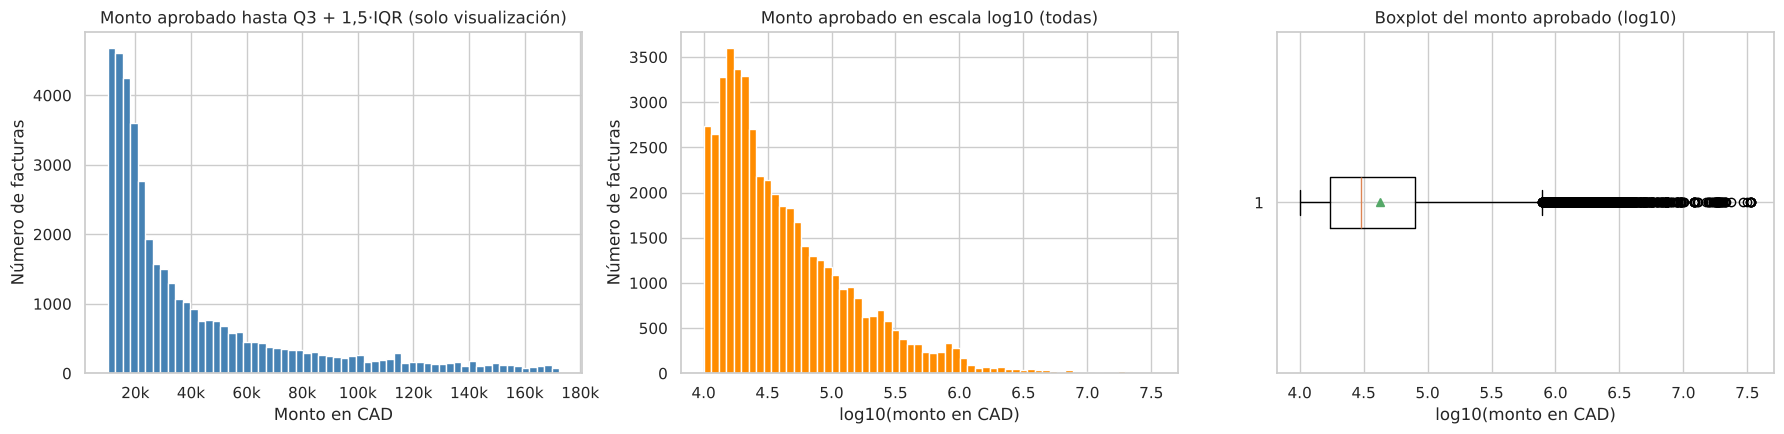

In [37]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
axes[0].hist(x[x <= q3 + 1.5 * (q3 - q1)], bins=60, color="steelblue")
axes[0].set_title("Monto aprobado hasta Q3 + 1,5·IQR (solo visualización)")
axes[0].set_xlabel("Monto en CAD"); axes[0].set_ylabel("Número de facturas")
axes[0].xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v/1000:,.0f}k"))
axes[1].hist(log_x, bins=60, color="darkorange")
axes[1].set_title("Monto aprobado en escala log10 (todas)")
axes[1].set_xlabel("log10(monto en CAD)"); axes[1].set_ylabel("Número de facturas")
axes[2].boxplot(log_x, orientation="horizontal", showmeans=True)
axes[2].set_title("Boxplot del monto aprobado (log10)"); axes[2].set_xlabel("log10(monto en CAD)")
plt.tight_layout(); plt.show()

**Atributo 1: monto aprobado (cuantitativa continua)**

El monto aprobado tiene una distribución muy asimétrica a la derecha. La media (147.306 CAD) es casi cinco veces la mediana (30.359 CAD) y la desviación estándar (817.775 CAD) es muy grande comparada con el rango intercuartílico (62.138 CAD), porque la desviación estándar se deja mover por los valores extremos. El 50% central de las facturas está entre 17.112 CAD (Q1) y 79.250 CAD (Q3), el percentil 95 es 467.707 CAD, el percentil 99 llega a 1.882.026 CAD y el máximo, 34.043.279 CAD, es un extremo verificado por recurrencia en la sección 3.4. La asimetría (22,26) y la curtosis (663,28) confirman que la cola derecha es muy larga.

Con el criterio de 1,5 veces el IQR en la escala original, el 12,87% de las facturas sale como atípica, porque el criterio no distingue entre una cola natural y un error. En escala log10, en cambio, la asimetría baja a 1,31 y solo el 2,95% queda por fuera de los bigotes. Por eso el monto se trabaja en escala logarítmica y con medidas que no se dejan mover por los extremos, como la mediana, los cuantiles y el IQR. El histograma recortado se usa solo para ver mejor la distribución y no se elimina ninguna factura por ser atípica.

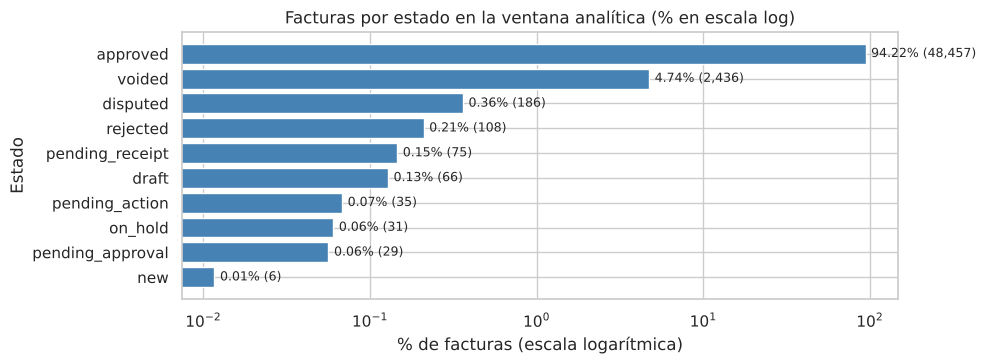

,facturas,pct,gasto_millones_cad
Invoice Status,,,
approved,48457,94.22,"7,138.00"
voided,2436,4.74,799.08
disputed,186,0.36,70.95
rejected,108,0.21,54.53
pending_receipt,75,0.15,8.59
draft,66,0.13,670.03
pending_action,35,0.07,3.13
on_hold,31,0.06,3.07
pending_approval,29,0.06,2.33


In [38]:
estado = base["Invoice Status"].value_counts().to_frame("facturas")
estado["pct"] = estado["facturas"] / estado["facturas"].sum() * 100
estado["gasto_millones_cad"] = base.groupby("Invoice Status")["monto_cad"].sum() / 1e6
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.barh(estado.index[::-1], estado["pct"][::-1], color="steelblue")
ax.set_xscale("log")
for i, (v, n) in enumerate(zip(estado["pct"][::-1], estado["facturas"][::-1])):
    ax.text(v * 1.08, i, f"{v:.2f}% ({n:,})", va="center", fontsize=9)
ax.set_title("Facturas por estado en la ventana analítica (% en escala log)")
ax.set_xlabel("% de facturas (escala logarítmica)"); ax.set_ylabel("Estado")
plt.tight_layout(); plt.show()
estado.round(2)

**Atributo 2: estado de la factura (cualitativa nominal)**

En la ventana, el 94,22% de las facturas está aprobado, el 4,74% está anulado, el 0,36% está en disputa y el 0,21% fue rechazado, mientras que todos los estados intermedios juntos suman menos de 0,5%. Por eso la gráfica usa escala logarítmica, ya que con una escala normal casi todas las barras serían invisibles. Los 66 borradores suman 670,03 millones de CAD, pero casi todo ese valor es el borrador extremo no verificado de la sección 3.4. Este es otro ejemplo de por qué no se pueden sumar montos sin verificar los extremos.

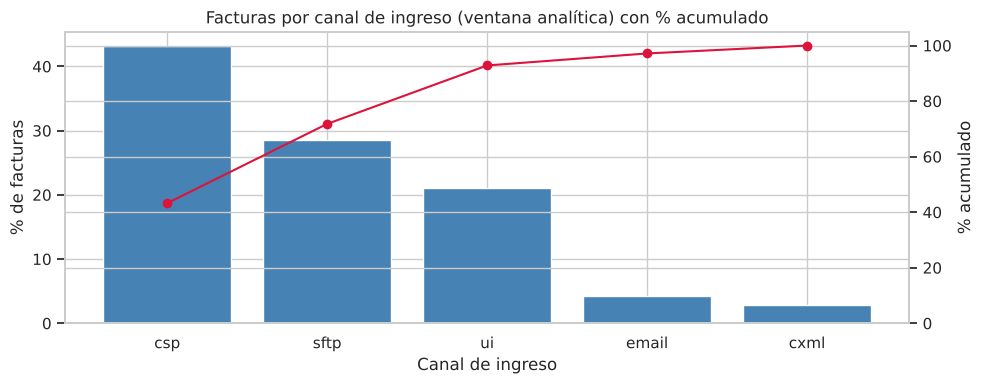

,facturas,pct,pct_acumulado,mediana_monto_cad
Invoice Channel,,,,
csp,22245,43.30,43.30,"29,576.50"
sftp,14677,28.50,71.80,"36,705.90"
ui,10820,21.00,92.80,"24,712.80"
email,2222,4.30,97.20,"36,990.20"
cxml,1465,2.80,100.00,"30,361.40"


In [39]:
canal = base["Invoice Channel"].value_counts().to_frame("facturas")
canal["pct"] = canal["facturas"] / canal["facturas"].sum() * 100
canal["pct_acumulado"] = canal["pct"].cumsum()
canal["mediana_monto_cad"] = base.groupby("Invoice Channel")["monto_cad"].median()
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(canal.index, canal["pct"], color="steelblue")
ax2 = ax.twinx(); ax2.plot(canal.index, canal["pct_acumulado"], color="crimson", marker="o")
ax2.set_ylim(0, 105); ax2.set_ylabel("% acumulado")
ax.set_title("Facturas por canal de ingreso (ventana analítica) con % acumulado")
ax.set_xlabel("Canal de ingreso"); ax.set_ylabel("% de facturas")
plt.tight_layout(); plt.show()
canal.round(1)

**Atributo 3: canal de ingreso (cualitativa nominal)**

Tres canales concentran el 92,8% de las facturas. El portal de proveedores (csp) tiene el 43,3%, sftp el 28,5% y ui el 21,0%, mientras que email (4,3%) y cxml (2,8%) tienen muy pocas. El monto típico también cambia según el canal: la mediana va de 24.713 CAD en ui a cerca de 37.000 CAD en sftp y email. Esa diferencia se prueba formalmente en la sección 5.5.

n_aprobadores  1.00   2.00   3.00   4.00   5.00   6.00   7.00   8.00   9.00   10.00  11.00  12.00  16.00  17.00  18.00  19.00  20.00  NaN  
facturas        3783   4776   6168   4828   2432   1183    518    205    110     50      3      3      2      1      4      4      1  27358

Facturas sin dato de aprobadores en la ventana: 27,358 (53.2%)

Con dato: 24,071 facturas | mediana 3 | p95 6 | máximo 20


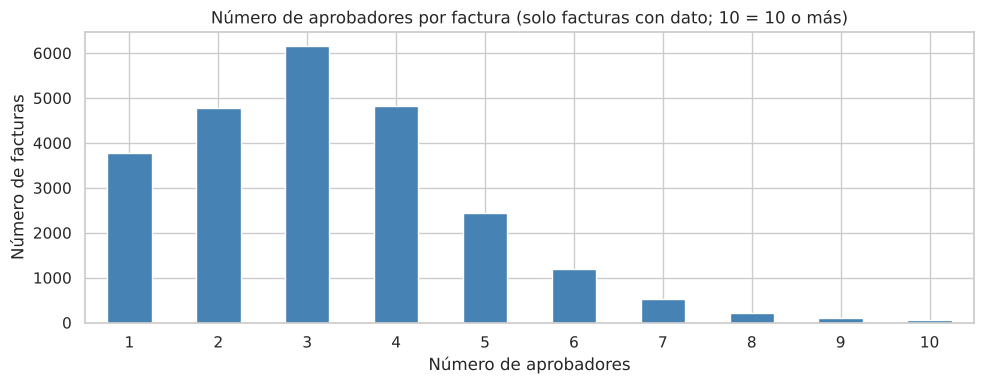

In [40]:
aprob_dist = base["n_aprobadores"].value_counts(dropna=False).sort_index()
print(aprob_dist.to_frame("facturas").T)
print(f"\nFacturas sin dato de aprobadores en la ventana: {base['n_aprobadores'].isna().sum():,} ({base['n_aprobadores'].isna().mean():.1%})")
con_dato = base["n_aprobadores"].dropna()
print(f"\nCon dato: {len(con_dato):,} facturas | mediana {con_dato.median():.0f} | p95 {con_dato.quantile(.95):.0f} | máximo {con_dato.max():.0f}")
fig, ax = plt.subplots(figsize=(10, 4))
con_dato.clip(upper=10).astype(int).value_counts().sort_index().plot(kind="bar", ax=ax, color="steelblue", rot=0)
ax.set_title("Número de aprobadores por factura (solo facturas con dato; 10 = 10 o más)")
ax.set_xlabel("Número de aprobadores"); ax.set_ylabel("Número de facturas")
plt.tight_layout(); plt.show()

**Atributo 4: número de aprobadores (cuantitativa discreta)**

En la ventana, el 53,2% de las facturas no tiene este dato, por las razones de proceso que se explicaron en la sección 3.1. Entre las 24.071 facturas que sí lo tienen, la mediana es de 3 aprobadores, el percentil 95 es 6 y el máximo es 20. La distribución tiene una sola moda en 3 y una cola corta hacia valores altos, que probablemente corresponde a montos grandes que necesitan más niveles de aprobación. Esto se verifica en la sección 5.3.

Proveedores con gasto aprobado en la ventana: 2,775
Proveedores que explican el 80% del gasto: 150 (5.4%)
Participación del top 10: 33.0%
Facturas por proveedor: mediana 2, p90 26, máximo 5942; proveedores con una sola factura: 36.0%


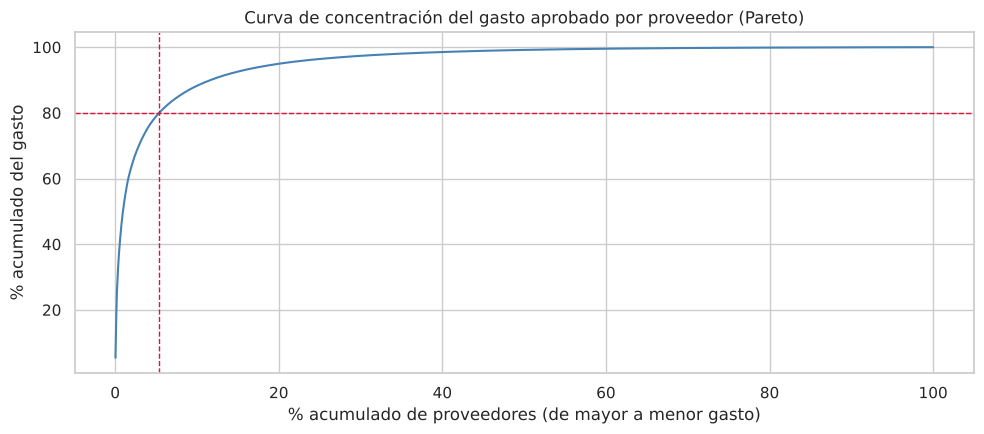

In [41]:
gasto_prov = aprobadas.groupby("proveedor_id")["monto_cad"].sum().sort_values(ascending=False)
acum = gasto_prov.cumsum() / gasto_prov.sum()
n80 = int((acum < 0.80).sum() + 1)

print(f"Proveedores con gasto aprobado en la ventana: {len(gasto_prov):,}")
print(f"Proveedores que explican el 80% del gasto: {n80} ({n80 / len(gasto_prov):.1%})")
print(f"Participación del top 10: {gasto_prov.head(10).sum() / gasto_prov.sum():.1%}")
fact_prov = aprobadas.groupby("proveedor_id").size()
print(f"Facturas por proveedor: mediana {fact_prov.median():.0f}, p90 {fact_prov.quantile(.9):.0f}, máximo {fact_prov.max()}; "
      f"proveedores con una sola factura: {(fact_prov == 1).mean():.1%}")

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(np.arange(1, len(acum) + 1) / len(acum) * 100, acum.values * 100, color="steelblue")
ax.axhline(80, color="crimson", ls="--", lw=1); ax.axvline(n80 / len(acum) * 100, color="crimson", ls="--", lw=1)
ax.set_title("Curva de concentración del gasto aprobado por proveedor (Pareto)")
ax.set_xlabel("% acumulado de proveedores (de mayor a menor gasto)"); ax.set_ylabel("% acumulado del gasto")
plt.tight_layout(); plt.show()

**Atributo 5: proveedor (concentración del gasto)**

En el punto 1 se dijo que una cantidad mínima de proveedores explica el 80% del gasto, y los datos lo confirman. En la ventana hay 2.775 proveedores con gasto aprobado y solo 150 de ellos (el 5,4%) explican el 80% del gasto. Los 10 más grandes concentran el 33,0%, una concentración muy alta que se ve en la curva de Pareto. En el otro extremo, la mitad de los proveedores tiene 2 facturas o menos y el 36,0% tiene una sola. Esto quiere decir que un modelo que compare cada factura con la historia de su proveedor solo va a tener historia suficiente para una parte de los proveedores, aunque esa parte concentra la mayoría del gasto.

Facturas aprobadas con transit válido: 27,426 (56.6%), con 80.7% del gasto aprobado
Transits distintos: 1,324 | transits que explican el 80% de ese gasto: 55 | participación del top 10: 47.5%
Facturas por transit: mediana 3, p90 31, máximo 3,158


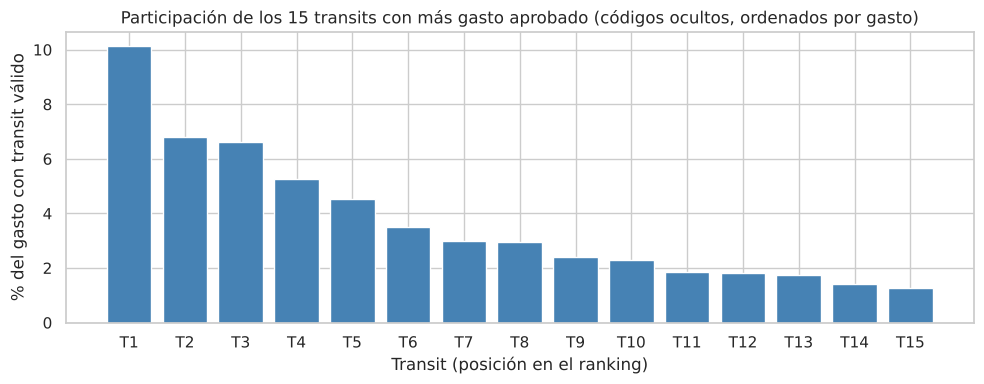

In [42]:
# Transit (área que asume el gasto): solo los valores con formato válido de 5 dígitos (sección 3.2)
tr = aprobadas[aprobadas["seg1_es_transit"]]
gasto_tr = tr.groupby("Account Segment 1")["monto_cad"].sum().sort_values(ascending=False)
acum_tr = gasto_tr.cumsum() / gasto_tr.sum()
fact_tr = tr.groupby("Account Segment 1").size()
print(f"Facturas aprobadas con transit válido: {len(tr):,} ({len(tr) / len(aprobadas):.1%}), "
      f"con {tr['monto_cad'].sum() / aprobadas['monto_cad'].sum():.1%} del gasto aprobado")
print(f"Transits distintos: {len(gasto_tr):,} | transits que explican el 80% de ese gasto: {int((acum_tr < .8).sum() + 1)} "
      f"| participación del top 10: {gasto_tr.head(10).sum() / gasto_tr.sum():.1%}")
print(f"Facturas por transit: mediana {fact_tr.median():.0f}, p90 {fact_tr.quantile(.9):.0f}, máximo {fact_tr.max():,}")
fig, ax = plt.subplots(figsize=(10, 4))
top_tr = (gasto_tr.head(15) / gasto_tr.sum() * 100).reset_index(drop=True)
ax.bar([f"T{i + 1}" for i in top_tr.index], top_tr.values, color="steelblue")
ax.set_title("Participación de los 15 transits con más gasto aprobado (códigos ocultos, ordenados por gasto)")
ax.set_xlabel("Transit (posición en el ranking)"); ax.set_ylabel("% del gasto con transit válido")
plt.tight_layout(); plt.show()

**Transit (área que asume el gasto)**

Este atributo es la dimensión de área que pide el objetivo 1. Solo el 56,6% de las facturas aprobadas tiene un transit con formato válido, pero esas facturas concentran el 80,7% del gasto aprobado; el resto se carga a códigos de proyecto (sección 3.2). Hay 1.324 transits distintos y 55 de ellos explican el 80% del gasto con transit válido, mientras que los 10 más grandes suman el 47,5%. La mediana es de 3 facturas por transit, el percentil 90 es 31 y el máximo es 3.158.

Para el tablero esto significa que la vista por área debe mostrar por separado el gasto con transit válido y el gasto cargado a proyectos, porque si no una quinta parte del gasto quedaría sin área. En la gráfica los códigos de transit se ocultan porque no aportan nada al análisis.

Categorías: 13


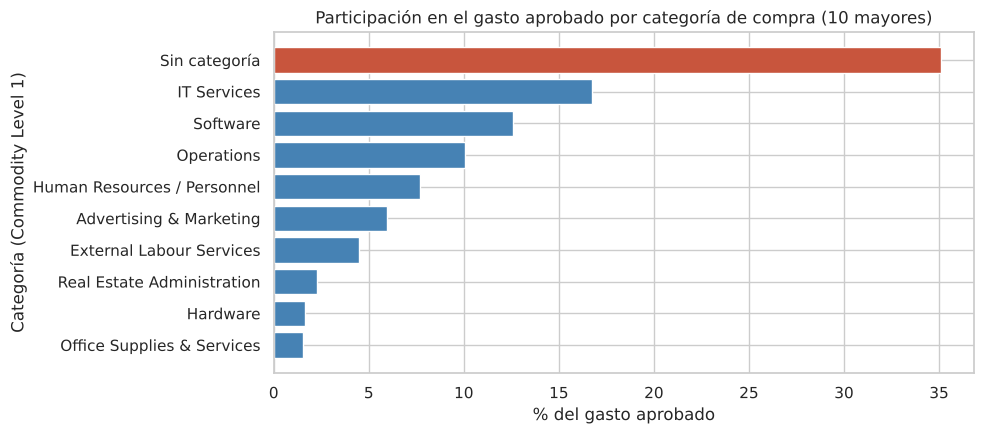

,facturas,gasto_millones_cad,pct_gasto
Commodity Level 1,,,
Sin categoría,14230,"2,504.40",35.10
IT Services,15421,"1,194.90",16.70
Software,2480,896.90,12.60
Operations,3043,716.90,10.00
Human Resources / Personnel,1265,551.10,7.70
Advertising & Marketing,3778,425.80,6.00
External Labour Services,2500,322.00,4.50
Real Estate Administration,3243,164.40,2.30
Hardware,901,119.30,1.70


In [43]:
cat = aprobadas.groupby("Commodity Level 1").agg(facturas=("monto_cad", "size"), gasto_millones_cad=("monto_cad", "sum"))
cat["gasto_millones_cad"] /= 1e6
cat["pct_gasto"] = cat["gasto_millones_cad"] / cat["gasto_millones_cad"].sum() * 100
cat = cat.sort_values("gasto_millones_cad", ascending=False)
print("Categorías:", len(cat))
fig, ax = plt.subplots(figsize=(10, 4.5))
top_c = cat.head(10)[::-1]
ax.barh(top_c.index, top_c["pct_gasto"], color=["#c8553d" if i == "Sin categoría" else "steelblue" for i in top_c.index])
ax.set_title("Participación en el gasto aprobado por categoría de compra (10 mayores)")
ax.set_xlabel("% del gasto aprobado"); ax.set_ylabel("Categoría (Commodity Level 1)")
plt.tight_layout(); plt.show()
cat.head(12).round(1)

**Categoría de compra**

La categoría con más gasto es Sin categoría, con el 35,1% del gasto aprobado (2.504,4 millones de CAD), lo que confirma que la clasificación está incompleta en las facturas sin orden de compra. Entre las categorías que sí están informadas dominan IT Services (16,7%), Software (12,6%), Operations (10,0%) y Human Resources / Personnel (7,7%). Para el tablero del objetivo 1 conviene pedirle al Banco una regla para clasificar las facturas sin categoría, por ejemplo a partir del proveedor o de la cuenta contable.

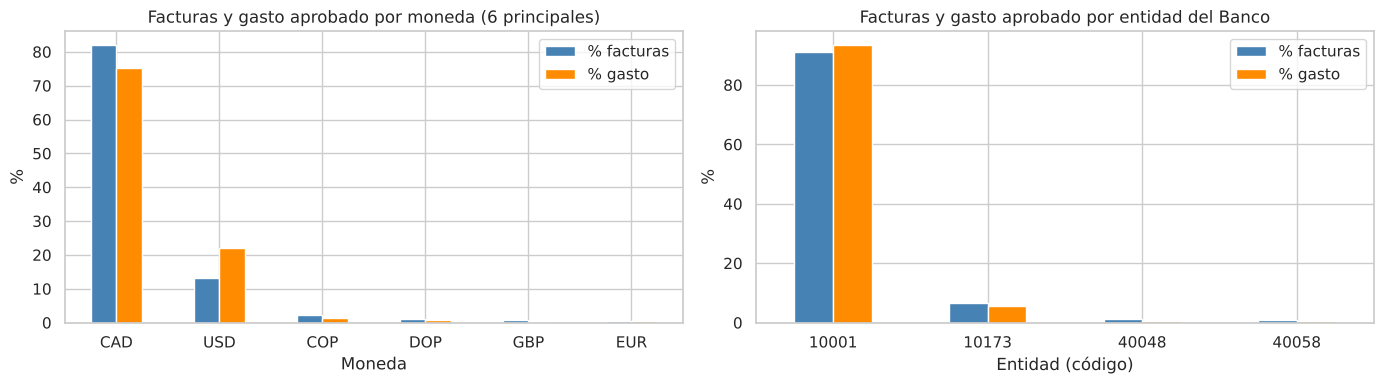

                       facturas  pct_facturas  pct_gasto
Invoice Currency Code                                   
CAD                       39754         82.04      75.31
USD                        6405         13.22      21.95
COP                        1091          2.25       1.27
DOP                         572          1.18       0.80
GBP                         433          0.89       0.29
EUR                         168          0.35       0.35
              facturas  pct_facturas  pct_gasto
prov_entidad                                   
10001            44139         91.09      93.46
10173             3215          6.63       5.49
40048              626          1.29       0.66
40058              477          0.98       0.39


In [44]:
# Moneda y entidad del Banco que contrata (cualitativas nominales)
mon = aprobadas["Invoice Currency Code"].value_counts()
mon_tab = pd.DataFrame({"facturas": mon, "pct_facturas": mon / mon.sum() * 100,
                        "pct_gasto": aprobadas.groupby("Invoice Currency Code")["monto_cad"].sum() / aprobadas["monto_cad"].sum() * 100}
                       ).sort_values("facturas", ascending=False)
ent_tab = aprobadas.groupby(aprobadas["prov_entidad"].fillna("sin dato")).agg(facturas=("monto_cad", "size"), gasto=("monto_cad", "sum"))
ent_tab["pct_facturas"] = ent_tab["facturas"] / ent_tab["facturas"].sum() * 100
ent_tab["pct_gasto"] = ent_tab["gasto"] / ent_tab["gasto"].sum() * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
mon_tab.head(6)[["pct_facturas", "pct_gasto"]].plot(kind="bar", ax=axes[0], rot=0, color=["steelblue", "darkorange"])
axes[0].set_title("Facturas y gasto aprobado por moneda (6 principales)")
axes[0].set_xlabel("Moneda"); axes[0].set_ylabel("%"); axes[0].legend(["% facturas", "% gasto"])
ent_tab[["pct_facturas", "pct_gasto"]].plot(kind="bar", ax=axes[1], rot=0, color=["steelblue", "darkorange"])
axes[1].set_title("Facturas y gasto aprobado por entidad del Banco")
axes[1].set_xlabel("Entidad (código)"); axes[1].set_ylabel("%"); axes[1].legend(["% facturas", "% gasto"])
plt.tight_layout(); plt.show()
print(mon_tab.head(6).round(2)); print(ent_tab.drop(columns="gasto").round(2))

**Moneda y entidad (cualitativas nominales)**

El CAD domina, con el 82,04% de las facturas aprobadas y el 75,31% del gasto. Le sigue el USD con el 13,22% de las facturas pero el 21,95% del gasto, porque sus facturas son más grandes en promedio. El peso colombiano (2,25%) y el peso dominicano (1,18%) tienen muy poca participación. En cuanto a la entidad del Banco que contrata, la 10001 concentra el 91,09% de las facturas y el 93,46% del gasto, y le sigue la 10173 con el 6,63% de las facturas.

Aunque las monedas distintas de CAD son pocas, en la sección 5.6 resultan ser la variable más asociada con la fricción. Por eso se conservan como variable de análisis y no se agrupan en una categoría de otras.

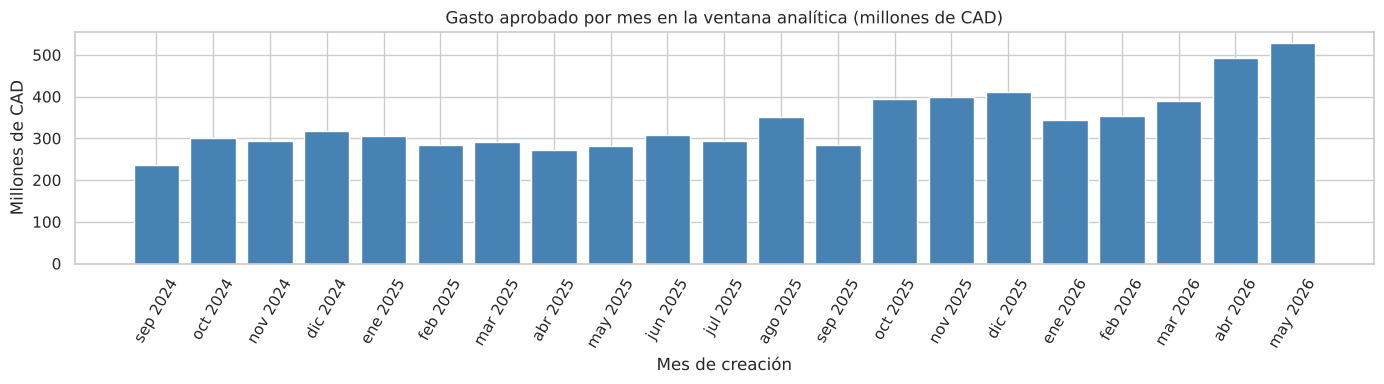

      facturas  gasto   mediana
mean  2,307.50 339.90 30,395.90
50%   2,262.00 309.00 30,168.80
min   1,808.00 235.00 27,302.60
max   2,954.00 529.10 33,640.60

Meses con más gasto: {'may 2026': 529.1, 'abr 2026': 492.4, 'dic 2025': 411.6}


In [45]:
serie = aprobadas.groupby("mes").agg(facturas=("monto_cad", "size"), gasto=("monto_cad", "sum"),
                                     mediana=("monto_cad", "median"))
fig, ax = plt.subplots(figsize=(14, 4))
ax.bar([mes_es(p) for p in serie.index], serie["gasto"] / 1e6, color="steelblue")
ax.set_title("Gasto aprobado por mes en la ventana analítica (millones de CAD)")
ax.set_xlabel("Mes de creación"); ax.set_ylabel("Millones de CAD")
ax.tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.show()
print(serie.assign(gasto=serie["gasto"] / 1e6).describe().loc[["mean", "50%", "min", "max"]].round(1))
print("\nMeses con más gasto:", {mes_es(k): v for k, v in (serie["gasto"] / 1e6).nlargest(3).round(1).items()})

**Gasto mensual**

El gasto aprobado por mes tiene una media de 339,9 millones de CAD (mediana de 309,0) y va de 235,0 a 529,1 millones. Los meses con más gasto son mayo de 2026 (529,1), abril de 2026 (492,4) y diciembre de 2025 (411,6). El número de facturas por mes también crece dentro de la ventana, mientras que la mediana del monto se mantiene estable entre 27.303 y 33.641 CAD. Así que el gasto crece porque hay más facturas y no porque las facturas sean más grandes.

## 5. Análisis bivariado y multivariado

### 5.1 Variables objetivo provisionales

El Banco no tiene registrado cuáles facturas fueron pagos duplicados. Mientras se consigue una muestra etiquetada se usan dos variables provisionales, cada una con sus limitaciones.

La primera es la fricción (con_friccion), que indica si la factura terminó anulada, disputada o rechazada. Se calcula sobre las facturas resueltas y es una señal de que algo en la factura no salió bien, pero no mide fraude ni duplicados, ya que como se vio en la sección 3.5 muchas anulaciones son correcciones normales.

La segunda es el candidato a duplicado (candidato_duplicado). Es una factura aprobada que tiene otra aprobada del mismo proveedor con el mismo monto en los 7 días anteriores, o que comparte un número de factura casi idéntico con otra factura aprobada. Las coincidencias con facturas anuladas no cuentan, porque son correcciones. Es un filtro amplio que también incluye la facturación en lote normal, y se usa para describir en dónde se concentra el riesgo.

In [46]:
# Variable objetivo provisional 1: fricción (anulada, disputada o rechazada) en facturas resueltas
print("Tasa global de fricción en facturas resueltas:", f"{resueltas['con_friccion'].mean():.2%}")
print(resueltas["Invoice Status"].value_counts().to_frame("facturas").T)

def tasa_con_ic(g):
    k, n = g.sum(), g.count()
    lo, hi = ic_prop(k, n)
    return pd.Series({"facturas": n, "con_friccion": k, "tasa_pct": k / n * 100, "ic95_inf": lo * 100, "ic95_sup": hi * 100})

# Variable objetivo provisional 2: candidato a duplicado entre facturas aprobadas de la ventana
ap_v = ap[(ap["Invoice Created Date"] >= VENTANA_INI) & (ap["Invoice Created Date"] < VENTANA_FIN)].copy()
ap_v["dup_mismo_monto_7d"] = ap_v["dias_desde_mismo_monto"].between(0, 7)
ap_v["dup_numero"] = ap_v.index.isin(colision_aprob_idx)
ap_v["candidato_duplicado"] = ap_v["dup_mismo_monto_7d"] | ap_v["dup_numero"]
print(f"\nAprobadas en la ventana: {len(ap_v):,} | candidatas a duplicado: {ap_v['candidato_duplicado'].sum():,} "
      f"({ap_v['candidato_duplicado'].mean():.1%})")

Tasa global de fricción en facturas resueltas: 5.33%
Invoice Status  approved  voided  disputed  rejected
facturas           48457    2436       186       108

Aprobadas en la ventana: 48,457 | candidatas a duplicado: 3,078 (6.4%)


La tasa global de fricción es 5,33%: hay 2.436 anuladas, 186 disputadas y 108 rechazadas frente a 48.457 aprobadas. Entre las aprobadas de la ventana, 3.078 (el 6,4%) son candidatas a duplicado. Las dos variables están desbalanceadas, así que desde ya se sabe que el modelo no se puede evaluar con el porcentaje total de aciertos. Si marcara todo como normal acertaría más del 93% de las veces sin encontrar ningún duplicado. Lo que sirve es mirar qué proporción de los casos marcados se confirma y qué proporción de los duplicados reales logra encontrar.

### 5.2 H1: ¿dónde aparecen los posibles duplicados?

**Hipótesis**

H0: la proporción de facturas aprobadas con el mismo monto en 0 a 7 días es igual en todos los canales.

H1: al menos un canal tiene una proporción distinta.

Como las dos variables son categóricas se usa la prueba chi cuadrado de independencia, con un nivel de significancia de 0,05.

In [47]:
# H1: ¿dónde aparecen los candidatos a duplicado? (facturas aprobadas en la ventana)
t_dup = ap_v.groupby("Invoice Channel").agg(
    facturas=("monto_cad", "size"),
    pct_mismo_monto_0_a_7_dias=("dup_mismo_monto_7d", lambda s: s.mean() * 100),
    pct_numero_casi_identico=("dup_numero", lambda s: s.mean() * 100))
tabla_d = pd.crosstab(ap_v["Invoice Channel"], ap_v["dup_mismo_monto_7d"])
chi2_d, p_d, _, _ = stats.chi2_contingency(tabla_d)
print(f"Canal vs mismo monto en 0 a 7 días: chi2 = {chi2_d:,.1f}, {fmt_p(p_d)}, V de Cramér = {cramers_v(tabla_d):.3f}")
print(f"Candidatos en la ventana: mismo monto en 0 a 7 días = {ap_v['dup_mismo_monto_7d'].sum():,} | "
      f"número casi idéntico = {ap_v['dup_numero'].sum():,} | cualquiera = {ap_v['candidato_duplicado'].sum():,} "
      f"({ap_v['candidato_duplicado'].mean():.1%} de las aprobadas)")
t_dup.sort_values("pct_mismo_monto_0_a_7_dias", ascending=False).round(2)

Canal vs mismo monto en 0 a 7 días: chi2 = 993.8, p < 0,001, V de Cramér = 0.143
Candidatos en la ventana: mismo monto en 0 a 7 días = 3,046 | número casi idéntico = 32 | cualquiera = 3,078 (6.4% de las aprobadas)


,facturas,pct_mismo_monto_0_a_7_dias,pct_numero_casi_identico
Invoice Channel,,,
csp,20800,10.16,0.06
sftp,13690,4.53,0.08
cxml,1395,2.58,0.00
ui,10385,2.41,0.04
email,2187,1.23,0.23


Se rechaza H0 (chi² = 993,8; p < 0,001) y la asociación está entre débil y moderada (V de Cramér de 0,143). El portal de proveedores (csp) tiene la proporción más alta de facturas con el mismo monto en 0 a 7 días, con el 10,16% de sus facturas aprobadas, frente al 4,53% de sftp y el 1,23% de email. Tiene sentido, porque el portal es el canal donde el proveedor carga sus propias facturas y a veces carga varias a la vez. El número casi idéntico a otra factura aprobada es mucho más raro (32 facturas en la ventana) y aparece en todos los canales menos en cxml.

Para el negocio esto quiere decir que la mayoría de los candidatos viene del portal, así que ese canal es la primera prioridad para el modelo. Al mismo tiempo es el canal donde más hay que separar la facturación en lote normal de los duplicados.

### 5.3 H2: canal de ingreso, cadena de aprobación y riesgo

**a) Canal vs fricción**

H0: la tasa de fricción es la misma en todos los canales.

H1: al menos un canal tiene una tasa distinta.

Se usa la prueba chi cuadrado y las tasas se reportan con intervalos de confianza al 95% calculados como en clase, con la proporción más o menos Z veces su error estándar. Se verificó que todas las frecuencias esperadas fueran mayores a 5 (la mínima es 78).

Chi cuadrado = 212.0, gl = 4, p < 0,001, V de Cramér = 0.064; frecuencia esperada mínima = 78


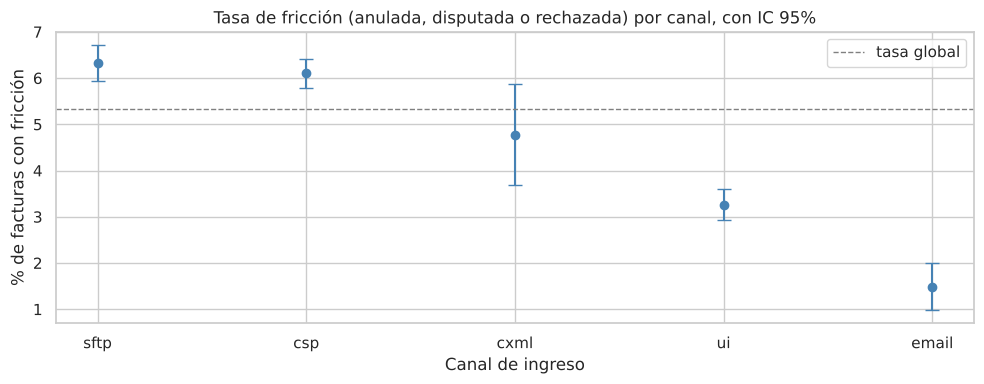

,facturas,con_friccion,tasa_pct,ic95_inf,ic95_sup
Invoice Channel,,,,,
sftp,"14,614.00",924.00,6.32,5.93,6.72
csp,"22,153.00","1,353.00",6.11,5.79,6.42
cxml,"1,465.00",70.00,4.78,3.69,5.87
ui,"10,735.00",350.00,3.26,2.92,3.60
email,"2,220.00",33.00,1.49,0.98,1.99


In [48]:
# H2: ¿la tasa de fricción cambia según el canal de ingreso?
t_canal = resueltas.groupby("Invoice Channel")["con_friccion"].apply(tasa_con_ic).unstack()
t_canal = t_canal[t_canal["facturas"] >= 30].sort_values("tasa_pct", ascending=False)
tabla = pd.crosstab(resueltas["Invoice Channel"], resueltas["con_friccion"]).loc[t_canal.index]
chi2, p, dof, esperado = stats.chi2_contingency(tabla)
print(f"Chi cuadrado = {chi2:,.1f}, gl = {dof}, {fmt_p(p)}, V de Cramér = {cramers_v(tabla):.3f}; "
      f"frecuencia esperada mínima = {esperado.min():.0f}")

fig, ax = plt.subplots(figsize=(10, 4))
ax.errorbar(t_canal.index, t_canal["tasa_pct"],
            yerr=[t_canal["tasa_pct"] - t_canal["ic95_inf"], t_canal["ic95_sup"] - t_canal["tasa_pct"]],
            fmt="o", color="steelblue", capsize=5)
ax.axhline(resueltas["con_friccion"].mean() * 100, color="gray", ls="--", lw=1, label="tasa global")
ax.set_title("Tasa de fricción (anulada, disputada o rechazada) por canal, con IC 95%")
ax.set_xlabel("Canal de ingreso"); ax.set_ylabel("% de facturas con fricción"); ax.legend()
plt.tight_layout(); plt.show()
t_canal.round(2)

Se rechaza H0 (chi² = 212,0; p < 0,001), pero la asociación es débil (V de Cramér de 0,064). Las tasas de fricción por canal son:

| Canal | Tasa de fricción | IC 95% |
|---|---|---|
| sftp | 6,32% | 5,93% a 6,72% |
| csp | 6,11% | 5,79% a 6,42% |
| cxml | 4,78% | 3,69% a 5,87% |
| ui | 3,26% | 2,92% a 3,60% |
| email | 1,49% | 0,98% a 1,99% |

Los intervalos de sftp y csp se cruzan, así que entre esos dos canales no hay evidencia de una diferencia. La diferencia real está entre ese par y los canales internos (ui y email).

**Validación de supuestos: independencia**

Las pruebas anteriores suponen que cada factura es independiente, pero las facturas de un mismo proveedor comparten precios, procesos y errores. Por eso, como en el caso de negocio visto en clase, se vuelve a calcular el intervalo de la diferencia más grande con un bootstrap por conglomerados, donde se remuestrean proveedores y no facturas.

In [49]:
# Supuesto de independencia: las facturas de un mismo proveedor NO son independientes.
# Se recalcula el intervalo de la diferencia más grande con bootstrap por conglomerados (remuestreando proveedores).
canal_alto, canal_bajo = t_canal.index[0], t_canal.index[-1]
sub = resueltas[resueltas["Invoice Channel"].isin([canal_alto, canal_bajo])]
por_prov = sub.groupby(["proveedor_id", "Invoice Channel"])["con_friccion"].agg(["sum", "count"]).unstack(fill_value=0)
rng = np.random.default_rng(RANDOM_STATE)
difs = []
idx = np.arange(len(por_prov))
for _ in range(2000):
    m = por_prov.iloc[rng.choice(idx, size=len(idx), replace=True)].sum()
    difs.append(m[("sum", canal_alto)] / m[("count", canal_alto)] - m[("sum", canal_bajo)] / m[("count", canal_bajo)])
dif_obs = t_canal.loc[canal_alto, "tasa_pct"] - t_canal.loc[canal_bajo, "tasa_pct"]
lo, hi = np.percentile(difs, [2.5, 97.5]) * 100
n_alto, n_bajo = t_canal.loc[canal_alto, "facturas"], t_canal.loc[canal_bajo, "facturas"]
p_a, p_b = t_canal.loc[canal_alto, "tasa_pct"] / 100, t_canal.loc[canal_bajo, "tasa_pct"] / 100
se_ingenuo = np.sqrt(p_a * (1 - p_a) / n_alto + p_b * (1 - p_b) / n_bajo) * 100
print(f"Diferencia {canal_alto} - {canal_bajo}: {dif_obs:.2f} puntos porcentuales")
print(f"IC 95% ingenuo (asume independencia):     [{dif_obs - 1.96 * se_ingenuo:.2f}, {dif_obs + 1.96 * se_ingenuo:.2f}]")
print(f"IC 95% bootstrap por proveedor (2.000 rep.): [{lo:.2f}, {hi:.2f}]")

Diferencia sftp - email: 4.84 puntos porcentuales
IC 95% ingenuo (asume independencia):     [4.20, 5.48]
IC 95% bootstrap por proveedor (2.000 rep.): [3.52, 5.75]


La diferencia entre sftp y email es de 4,84 puntos porcentuales. El intervalo que supone independencia va de 4,20 a 5,48, mientras que el intervalo por conglomerados va de 3,52 a 5,75, casi el doble de ancho. La diferencia se mantiene porque el intervalo no incluye el 0, pero si se ignora que las facturas se agrupan por proveedor se obtiene una precisión que no es real. Por eso la regresión de la sección 5.6 usa errores estándar agrupados por proveedor.

**b) Cadena de aprobación vs fricción**

Antes de usar los campos de aprobación como variables explicativas hay que revisar si el dato existe antes de conocer el resultado de la factura.

In [50]:
# Antes de usar los campos de aprobación como explicativos: ¿se llenan antes o después de conocer el resultado?
fuga = base.groupby("Invoice Status").agg(
    facturas=("monto_cad", "size"),
    pct_sin_n_aprobadores=("n_aprobadores", lambda s: s.isna().mean() * 100),
    pct_sin_aprobador_original=("Original Approver Name", lambda s: s.isna().mean() * 100))
sin_cad = base[(base["Invoice Status"] == "approved") & base["n_aprobadores"].isna()]
print(f"Aprobadas sin cadena de aprobación registrada: {len(sin_cad):,} de {(base['Invoice Status'] == 'approved').sum():,}")
print("Canal de esas facturas (%):", (sin_cad["Invoice Channel"].value_counts(normalize=True) * 100).round(1).to_dict())
fuga.loc[["approved", "voided", "disputed", "rejected"]].round(1)

Aprobadas sin cadena de aprobación registrada: 24,454 de 48,457
Canal de esas facturas (%): {'csp': 78.3, 'ui': 8.1, 'sftp': 6.1, 'cxml': 5.6, 'email': 2.0}


,facturas,pct_sin_n_aprobadores,pct_sin_aprobador_original
Invoice Status,,,
approved,48457,50.50,50.50
voided,2436,99.30,84.90
disputed,186,90.90,71.50
rejected,108,77.80,0.00


Esta tabla muestra uno de los hallazgos más importantes del notebook. El número de aprobadores está vacío en el 99,3% de las facturas anuladas y en el 50,5% de las aprobadas. Una factura anulada casi nunca llega a tener cadena de aprobación porque se anula antes. Si se usara Number of Approvers para explicar la fricción, la relación saldría casi perfecta, pero sería falsa, porque el dato se llena como consecuencia del resultado. Esto es una fuga de información (*data leakage*).

Este resultado también sirve para revisar una justificación del punto 1. Allí se dijo que se trabaja con las facturas de 10.000 CAD o más porque desde ese monto requieren al menos un aprobador y una doble revisión de Procurement. Los datos lo confirman solo en parte, ya que 24.454 de las 48.457 aprobadas (el 50,5%) no tienen una cadena de aprobación registrada en la factura. De esas, el 78,3% entró por el portal (csp) y el 5,6% por cxml, que se emiten contra una orden de compra que ya pasó por aprobación (sección 3.1). Así que la doble revisión puede estar ocurriendo en la orden de compra y no en la factura. Esto no cambia el análisis, pero sí cómo se presenta el corte de 10.000 CAD: se toma como el filtro de la extracción y la regla de aprobación se va a validar con el Banco.

Por eso los campos de aprobación no se usan para explicar la fricción ni como variables del modelo cuando la etiqueta dependa del estado final. La parte de la hipótesis 2 sobre la cadena de aprobación se replantea sobre las facturas aprobadas, que es donde la cadena sí existe, usando como resultado el candidato a duplicado.

**c) Cadena de aprobación vs candidatos a duplicado (facturas aprobadas)**

H0: la proporción de candidatos a duplicado no depende del número de aprobadores ni de que el solicitante sea el aprobador.

H1: sí depende.

In [51]:
# H2 reformulada sobre facturas APROBADAS (donde la cadena de aprobación sí existe):
# ¿los candidatos a duplicado se concentran en facturas sin cadena, con pocos aprobadores o con autoaprobación?
ap_v["aprobadores_cat"] = (pd.cut(ap_v["n_aprobadores"], [0, 1, 2, 4, 100], labels=["1", "2", "3 a 4", "5 o más"])
                           .cat.add_categories("sin cadena").fillna("sin cadena").astype(str))

def tasa_con_ic_col(g, col):
    k, n = g[col].sum(), len(g)
    lo, hi = ic_prop(k, n)
    return pd.Series({"facturas": n, "candidatas": k, "tasa_pct": k / n * 100, "ic95_inf": lo * 100, "ic95_sup": hi * 100})

t_ac = ap_v.groupby("aprobadores_cat").apply(tasa_con_ic_col, col="candidato_duplicado").loc[["sin cadena", "1", "2", "3 a 4", "5 o más"]]
tabla_ac = pd.crosstab(ap_v["aprobadores_cat"], ap_v["candidato_duplicado"])
chi2_ac, p_ac, _, _ = stats.chi2_contingency(tabla_ac)
print(f"Aprobadores vs candidato a duplicado: chi2 = {chi2_ac:,.1f}, {fmt_p(p_ac)}, V de Cramér = {cramers_v(tabla_ac):.3f}")
print(t_ac.round(2), "\n")

# Lo mismo controlando el canal: solo canales donde la cadena de aprobación es la norma (sftp, ui, email)
sub_c = ap_v[ap_v["Invoice Channel"].isin(["sftp", "ui", "email"])]
t_ac2 = sub_c.groupby(sub_c["n_aprobadores"].isna().map({True: "sin cadena", False: "con cadena"})).apply(
    tasa_con_ic_col, col="candidato_duplicado")
print("Solo canales sftp, ui y email:"); print(t_ac2.round(2), "\n")

con_cadena = ap_v[ap_v["n_aprobadores"].notna()]
t_sod = con_cadena.groupby("solicitante_es_aprobador").apply(tasa_con_ic_col, col="candidato_duplicado")
tabla_s = pd.crosstab(con_cadena["solicitante_es_aprobador"], con_cadena["candidato_duplicado"])
chi2_s, p_s, _, _ = stats.chi2_contingency(tabla_s)
print(f"Solicitante = aprobador vs candidato a duplicado: chi2 = {chi2_s:,.1f}, {fmt_p(p_s)}, V de Cramér = {cramers_v(tabla_s):.3f}")
print(t_sod.round(2))

rho_ma, p_ma = stats.spearmanr(con_cadena["monto_cad"], con_cadena["n_aprobadores"])
print(f"\nSpearman monto vs número de aprobadores (aprobadas con cadena): rho = {rho_ma:.3f}, {fmt_p(p_ma)}")

Aprobadores vs candidato a duplicado: chi2 = 878.1, p < 0,001, V de Cramér = 0.135
                 facturas  candidatas  tasa_pct  ic95_inf  ic95_sup
aprobadores_cat                                                    
sin cadena      24,454.00    2,333.00      9.54      9.17      9.91
1                3,744.00       47.00      1.26      0.90      1.61
2                4,763.00      165.00      3.46      2.94      3.98
3 a 4           10,981.00      419.00      3.82      3.46      4.17
5 o más          4,515.00      114.00      2.52      2.07      2.98 



Solo canales sftp, ui y email:
               facturas  candidatas  tasa_pct  ic95_inf  ic95_sup
n_aprobadores                                                    
con cadena    22,318.00      719.00      3.22      2.99      3.45
sin cadena     3,944.00      198.00      5.02      4.34      5.70 



Solicitante = aprobador vs candidato a duplicado: chi2 = 10.6, p = 0,0011, V de Cramér = 0.021
                          facturas  candidatas  tasa_pct  ic95_inf  ic95_sup
solicitante_es_aprobador                                                    
False                    18,354.00      532.00      2.90      2.66      3.14
True                      5,649.00      213.00      3.77      3.27      4.27

Spearman monto vs número de aprobadores (aprobadas con cadena): rho = 0.323, p < 0,001


Con el número de aprobadores se rechaza H0 (chi² = 878,1; p < 0,001; V de Cramér de 0,135). Sin embargo, esta comparación global está muy influida por el canal, porque las facturas sin cadena son sobre todo del portal, que es donde más hay facturación en lote. Para aislar ese efecto se repitió la comparación solo con sftp, ui y email, donde la cadena de aprobación es lo normal. Ahí las facturas sin cadena tienen 5,02% de candidatos frente a 3,22% de las que sí tienen cadena, y los intervalos no se cruzan. Esto apoya la hipótesis 2, ya que las facturas que no pasan por una cadena de aprobación tienen más candidatos a duplicado incluso dentro de los mismos canales.

Cuando el solicitante es el aprobador, la tasa de candidatos es 3,77% frente a 2,90%. La diferencia es significativa (p = 0,0011) pero la asociación es muy pequeña (V de 0,021), así que es una señal complementaria y no un criterio fuerte por sí sola. Por último, la correlación de Spearman entre el monto y el número de aprobadores es de 0,323: a mayor monto, más aprobadores, lo cual es coherente con una política de aprobación por niveles de monto.

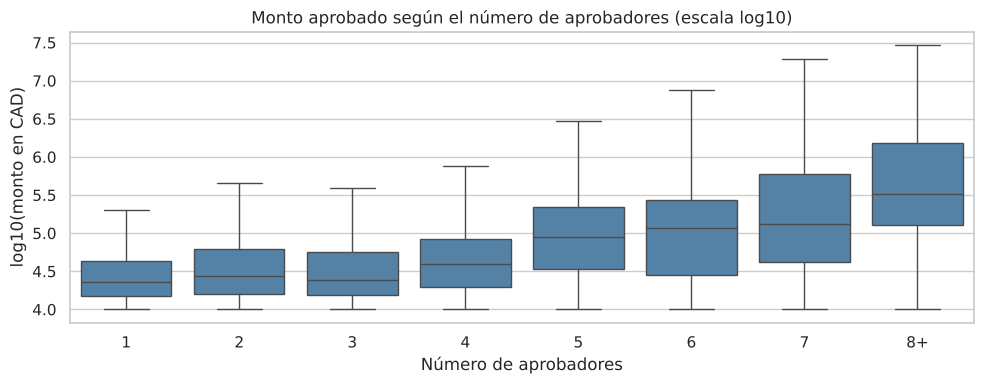

aprobadores               1         2         3         4         5          6          7         8+
mediana_monto_cad 22,830.00 27,085.00 24,481.00 39,516.00 87,765.00 116,382.00 131,198.00 327,110.00
ANOVA de una vía (log10 del monto por número de aprobadores): F = 800.4, p < 0,001


In [52]:
# Gráfico de la relación monto vs número de aprobadores (aprobadas con cadena de aprobación)
d = con_cadena.assign(aprobadores=con_cadena["n_aprobadores"].clip(upper=8).astype(int).astype(str).replace("8", "8+"),
                      log_monto=np.log10(con_cadena["monto_cad"]))
orden_a = ["1", "2", "3", "4", "5", "6", "7", "8+"]
fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(data=d, x="aprobadores", y="log_monto", order=orden_a, showfliers=False, ax=ax, color="steelblue")
ax.set_title("Monto aprobado según el número de aprobadores (escala log10)")
ax.set_xlabel("Número de aprobadores"); ax.set_ylabel("log10(monto en CAD)")
plt.tight_layout(); plt.show()
print(d.groupby("aprobadores")["monto_cad"].median().loc[orden_a].round(0).to_frame("mediana_monto_cad").T)
an_a = stats.f_oneway(*[d.loc[d["aprobadores"] == a, "log_monto"] for a in orden_a])
print(f"ANOVA de una vía (log10 del monto por número de aprobadores): F = {an_a.statistic:,.1f}, {fmt_p(an_a.pvalue)}")

La gráfica muestra que el número de aprobadores sigue al monto, aunque no de forma perfecta. Los primeros tres niveles tienen medianas parecidas: 22.830 CAD con 1 aprobador, 27.085 con 2 y 24.481 con 3. Desde 4 aprobadores la mediana sí sube con claridad: 39.516 CAD con 4, 87.765 con 5, 116.382 con 6, 131.198 con 7 y 327.110 CAD con 8 o más (ANOVA de una vía sobre el log10 del monto, F = 800,4; p < 0,001).

Esto es coherente con una política de delegación de autoridad por monto. Si el Banco comparte la tabla de niveles de aprobación, se podría crear una variable muy útil para el modelo que indique si la factura tuvo menos aprobadores de los que exige su monto. Por eso esa tabla está en la lista de datos que se van a pedir.

### 5.4 H3: ¿qué proveedores concentran el riesgo?

Este análisis se hace a nivel de proveedor porque esa es la unidad independiente. Se usan los 669 proveedores que tienen al menos 10 facturas resueltas en la ventana, para que su tasa de fricción no dependa de una o dos facturas. Como las variables son asimétricas y la relación no tiene por qué ser lineal, se usa Spearman.

H0: ρ = 0 entre cada característica del proveedor y su tasa de fricción.

H1: ρ ≠ 0.

Proveedores con >= 10 facturas resueltas: 669
           variable  rho_spearman  p_valor
0          facturas          0.14     0.00
1    gasto_aprobado          0.15     0.00
2     mediana_monto          0.15     0.00
3   antiguedad_dias          0.18     0.00
4  pct_sin_contrato         -0.28     0.00 

                  count  mean  50%
nuevo_en_ventana                  
False            365.00  0.07 0.04
True             304.00  0.05 0.00
t de Welch, nuevos menos antiguos: -2.19 puntos porcentuales, IC 95% [-3.76, -0.62], p = 0,0063
            count  mean  50%
intragrupo                  
False      640.00  0.06 0.02
True        29.00  0.11 0.07


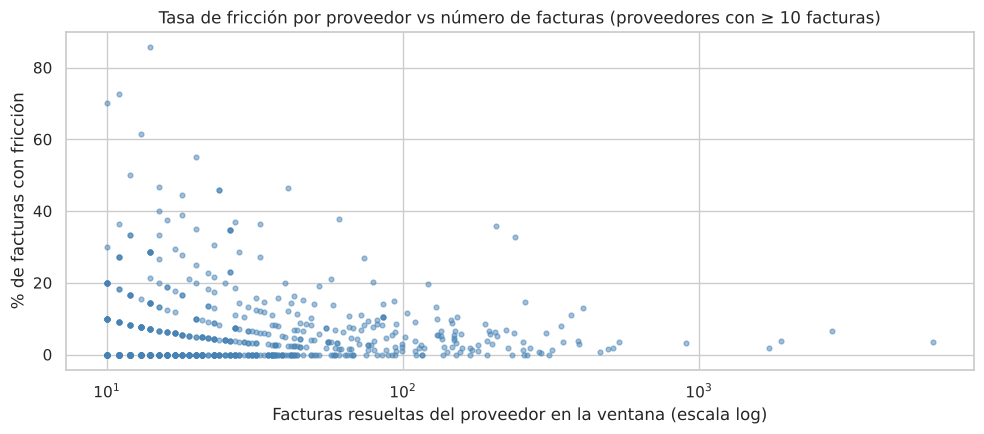

In [53]:
# H3: ¿qué proveedores concentran la fricción? Análisis a nivel proveedor (unidad independiente)
primera = df.groupby("proveedor_id")["Invoice Created Date"].min()          # historia completa desde jun-2022
prov_df = resueltas.groupby("proveedor_id").agg(
    facturas=("con_friccion", "size"), tasa_friccion=("con_friccion", "mean"),
    gasto_aprobado=("monto_cad", lambda s: s[resueltas.loc[s.index, "con_friccion"] == 0].sum()),
    mediana_monto=("monto_cad", "median"),
    pct_sin_contrato=("tiene_contrato", lambda s: 1 - s.mean()),
    intragrupo=("prov_intragrupo", "max"))
prov_df["antiguedad_dias"] = np.clip((pd.Timestamp(VENTANA_INI) - prov_df.index.map(primera)).days, 0, None)
prov_df["nuevo_en_ventana"] = prov_df["antiguedad_dias"] == 0
prov10 = prov_df[prov_df["facturas"] >= 10].copy()
print("Proveedores con >= 10 facturas resueltas:", len(prov10))

filas = []
for v in ["facturas", "gasto_aprobado", "mediana_monto", "antiguedad_dias", "pct_sin_contrato"]:
    rho, p = stats.spearmanr(prov10[v], prov10["tasa_friccion"])
    filas.append({"variable": v, "rho_spearman": rho, "p_valor": p})
print(pd.DataFrame(filas).round(4), "\n")

t_nuevo = prov10.groupby("nuevo_en_ventana")["tasa_friccion"].describe()[["count", "mean", "50%"]]
dif, lo, hi, t, gl, p = welch(prov10.loc[prov10["nuevo_en_ventana"], "tasa_friccion"] * 100, prov10.loc[~prov10["nuevo_en_ventana"], "tasa_friccion"] * 100)
print(t_nuevo.round(3))
print(f"t de Welch, nuevos menos antiguos: {dif:.2f} puntos porcentuales, IC 95% [{lo:.2f}, {hi:.2f}], {fmt_p(p)}")
t_ig = prov10.groupby("intragrupo")["tasa_friccion"].describe()[["count", "mean", "50%"]]
print(t_ig.round(3))

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.scatter(prov10["facturas"], prov10["tasa_friccion"] * 100, s=12, alpha=.5, color="steelblue")
ax.set_xscale("log")
ax.set_title("Tasa de fricción por proveedor vs número de facturas (proveedores con ≥ 10 facturas)")
ax.set_xlabel("Facturas resueltas del proveedor en la ventana (escala log)"); ax.set_ylabel("% de facturas con fricción")
plt.tight_layout(); plt.show()

La hipótesis 3 no se apoya en la dirección que se planteó. Se esperaba que los proveedores nuevos o con poca historia tuvieran más anomalías, pero pasa lo contrario. Los proveedores cuya primera factura cae dentro de la ventana tienen una tasa media de fricción de 5% (mediana de 0%), frente a 7% (mediana de 4%) de los que ya tenían historia. Con la prueba t de Welch la diferencia es de 2,19 puntos porcentuales menos para los nuevos (IC 95% de 0,62 a 3,76 puntos; p = 0,0063), y la antigüedad tiene una asociación positiva pero débil con la fricción (ρ = 0,18). Una posible explicación es que los proveedores antiguos son los que más usan el portal y más corrigen facturas. Además, la antigüedad está truncada porque los datos empiezan en junio de 2022.

Los proveedores con más facturas y más gasto tienen un poco más de fricción (ρ de 0,14 y 0,15), aunque son asociaciones débiles. Los proveedores con más facturas sin contrato tienen menos fricción (ρ negativo de 0,28), lo que es coherente con que la fricción se concentre en el flujo con orden de compra del portal. Los proveedores intragrupo tienen una tasa media más alta (11% frente a 6%), pero son solo 29, así que en la sección 5.6 se revisa si esa diferencia se mantiene al controlar otras variables. Finalmente, en el diagrama de dispersión se ve que las tasas más altas (más de 40%) aparecen en proveedores con pocas facturas, donde una o dos anulaciones mueven mucho el porcentaje.

### 5.5 H4: ¿las facturas con un monto atípico para su proveedor tienen más fricción?

En el punto 4 la hipótesis se planteó con un ejemplo: las facturas con más de tres desviaciones sobre la mediana de su proveedor. Esa regla tiene un problema con estos datos. Con pocas facturas, una factura no puede quedar a tres desviaciones estándar de la media de su grupo, porque el máximo posible es (n menos 1) dividido entre la raíz de n, y ese valor solo pasa de 3 cuando el proveedor tiene 11 facturas o más. En estos datos son 364 de los 985 proveedores analizados (el 37,0%), así que con esa regla más de un tercio de los proveedores nunca tendría una factura atípica. Además, la pregunta del punto 4 también mencionaba la categoría, pero el 35,5% de las facturas no tiene categoría, así que la referencia más confiable es el propio proveedor.

Por eso se usa la regla del rango intercuartílico que se vio en clase, pero calculada para cada proveedor sobre el log10 del monto, como en el caso de negocio, donde la cerca se calcula por grupo para no sesgar la comparación. Se trabaja con los proveedores que tienen al menos 5 facturas resueltas y un IQR mayor a cero, sin los extremos no verificados.

Cada factura queda en uno de cinco niveles: muy bajo (por debajo de Q1 menos 1,5 IQR de su proveedor), bajo (entre esa cerca y Q1), habitual (entre Q1 y Q3), alto (entre Q3 y Q3 más 1,5 IQR) y muy alto (por encima de la cerca superior).

H0: la tasa de fricción es igual para las facturas por encima de la cerca superior y para las que están dentro de las cercas.

H1: la tasa es distinta.

Facturas con historia suficiente: 47652 | proveedores: 985
Proveedores con menos de 11 facturas, donde 3 desviaciones estándar no se pueden alcanzar: 364 de 985 (37.0%)
             facturas  con_friccion  tasa_pct  ic95_inf  ic95_sup
nivel_monto                                                      
muy bajo       584.00         36.00      6.16      4.21      8.11
bajo        11,054.00        522.00      4.72      4.33      5.12
habitual    24,248.00      1,138.00      4.69      4.43      4.96
alto        10,290.00        602.00      5.85      5.40      6.30
muy alto     1,476.00        143.00      9.69      8.18     11.20

Por encima de la cerca superior: 9.69% vs dentro de las cercas: 4.96% | chi2 = 64.9, p < 0,001, V de Cramér = 0.037, frecuencia esperada mínima = 75
Distancia absoluta a la mediana del proveedor (log10), con vs sin fricción: diferencia de medias = 0.068, IC 95% [0.053, 0.083], p < 0,001


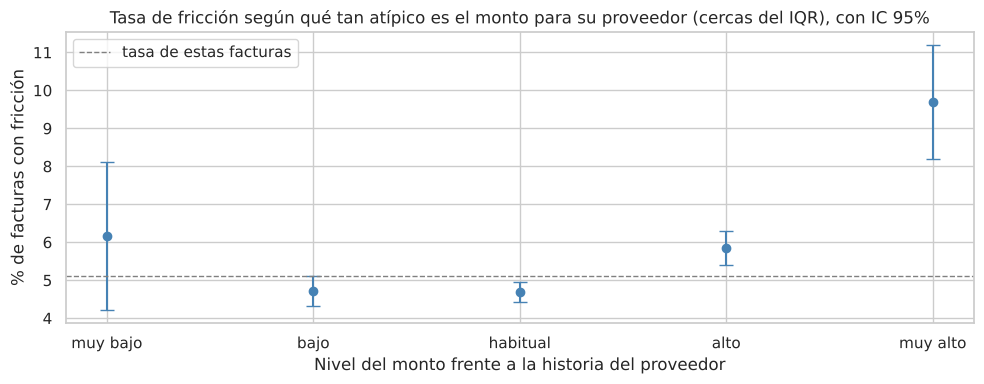

In [54]:
# H4: ¿las facturas con monto atípico para su proveedor tienen más fricción?
# Se usan las cercas del IQR calculadas POR PROVEEDOR sobre el log10 del monto (como en el caso de negocio, donde la cerca
# se calcula por grupo para no sesgar la comparación). Proveedores con >= 5 facturas resueltas.
r = resueltas[~resueltas["extremo_no_verificado"]].copy()
r["log_monto"] = np.log10(r["monto_cad"])
g = r.groupby("proveedor_id")["log_monto"]
r["n_prov"] = g.transform("size")
r["q1_prov"] = g.transform(lambda s: s.quantile(.25))
r["q3_prov"] = g.transform(lambda s: s.quantile(.75))
r["mediana_log_prov"] = g.transform("median")
r["iqr_prov"] = r["q3_prov"] - r["q1_prov"]
r = r[(r["n_prov"] >= 5) & (r["iqr_prov"] > 0)].copy()
# Medida continua: distancia en log10 entre el monto y la mediana de su proveedor (1 = diez veces más grande)
r["desvio_log"] = r["log_monto"] - r["mediana_log_prov"]
cerca_inf = r["q1_prov"] - 1.5 * r["iqr_prov"]; cerca_sup = r["q3_prov"] + 1.5 * r["iqr_prov"]
r["nivel_monto"] = np.select(
    [r["log_monto"] < cerca_inf, r["log_monto"] < r["q1_prov"], r["log_monto"] <= r["q3_prov"], r["log_monto"] <= cerca_sup],
    ["muy bajo", "bajo", "habitual", "alto"], default="muy alto")
orden_n = ["muy bajo", "bajo", "habitual", "alto", "muy alto"]
t_z = r.groupby("nivel_monto")["con_friccion"].apply(tasa_con_ic).unstack().loc[orden_n]
print("Facturas con historia suficiente:", len(r), "| proveedores:", r["proveedor_id"].nunique())
# Con n facturas, el puntaje z de una factura (con la desviación estándar muestral) no puede pasar de (n - 1) / raíz(n),
# así que la regla de 3 desviaciones solo puede marcar algo en proveedores con 11 facturas o más
prov_n = r.groupby("proveedor_id")["n_prov"].first()
print(f"Proveedores con menos de 11 facturas, donde 3 desviaciones estándar no se pueden alcanzar: {(prov_n < 11).sum()} de {len(prov_n)} "
      f"({(prov_n < 11).mean():.1%})")
print(t_z.round(2))

atipico_alto = r["nivel_monto"] == "muy alto"; dentro = r["log_monto"].between(cerca_inf, cerca_sup)
tabla_z = pd.crosstab(np.where(atipico_alto, "por encima de la cerca", "dentro de las cercas")[atipico_alto | dentro],
                      r.loc[atipico_alto | dentro, "con_friccion"])
chi2_z, p_z, _, esp_z = stats.chi2_contingency(tabla_z)
print(f"\nPor encima de la cerca superior: {r.loc[atipico_alto, 'con_friccion'].mean():.2%} vs dentro de las cercas: "
      f"{r.loc[dentro, 'con_friccion'].mean():.2%} | chi2 = {chi2_z:.1f}, {fmt_p(p_z)}, V de Cramér = {cramers_v(tabla_z):.3f}, "
      f"frecuencia esperada mínima = {esp_z.min():.0f}")
dif, lo, hi, t, gl, p = welch(r.loc[r["con_friccion"] == 1, "desvio_log"].abs(), r.loc[r["con_friccion"] == 0, "desvio_log"].abs())
print(f"Distancia absoluta a la mediana del proveedor (log10), con vs sin fricción: diferencia de medias = {dif:.3f}, "
      f"IC 95% [{lo:.3f}, {hi:.3f}], {fmt_p(p)}")

fig, ax = plt.subplots(figsize=(10, 4))
ax.errorbar(orden_n, t_z["tasa_pct"], yerr=[t_z["tasa_pct"] - t_z["ic95_inf"], t_z["ic95_sup"] - t_z["tasa_pct"]],
            fmt="o", color="steelblue", capsize=5)
ax.axhline(r["con_friccion"].mean() * 100, color="gray", ls="--", lw=1, label="tasa de estas facturas")
ax.set_title("Tasa de fricción según qué tan atípico es el monto para su proveedor (cercas del IQR), con IC 95%")
ax.set_xlabel("Nivel del monto frente a la historia del proveedor"); ax.set_ylabel("% de facturas con fricción"); ax.legend()
plt.tight_layout(); plt.show()

La hipótesis 4 se apoya. Las facturas que quedan por encima de la cerca superior de su proveedor tienen una tasa de fricción de 9,69%, frente a 4,96% de las que están dentro de las cercas (chi² = 64,9; p < 0,001). Es casi el doble, aunque la V de Cramér es pequeña (0,037) porque estas facturas son pocas. La prueba t de Welch muestra lo mismo con una medida continua: las facturas con fricción están, en promedio, 0,068 unidades de log10 más lejos de la mediana de su proveedor que las aprobadas (IC 95% de 0,053 a 0,083; p < 0,001).

Algo que no se esperaba es que las facturas del nivel muy bajo también tienen más fricción (6,16%), o sea que la tabla tiene forma de U y lo atípico en cualquier dirección se asocia con más problemas. Por eso la distancia del monto a lo habitual del proveedor es una buena variable para el modelo, siempre que entre en valor absoluto o con las dos colas.

**Monto vs canal (cuantitativa vs categórica)**

Como complemento se compara la distribución del monto aprobado entre canales con un boxplot y con un ANOVA de una vía sobre el log10 del monto, porque en esa escala la distribución es mucho más simétrica.

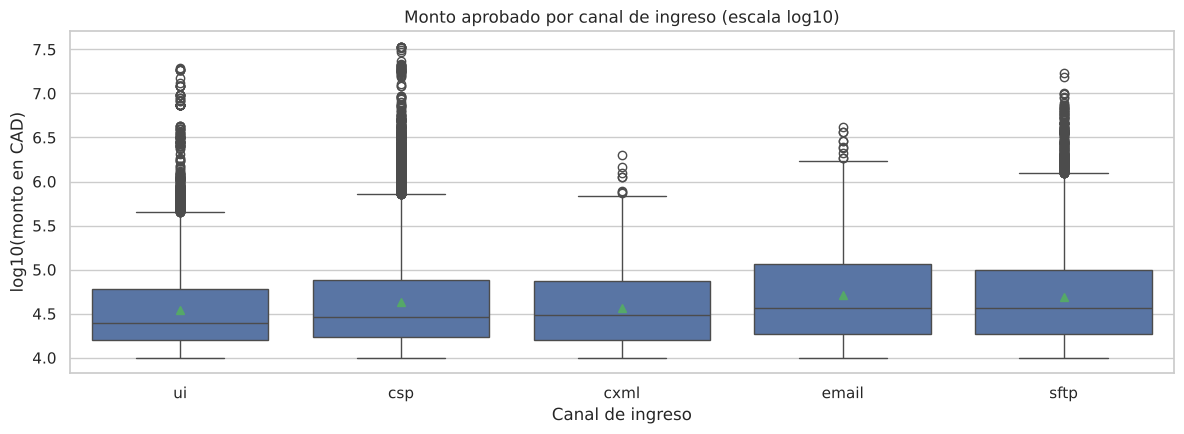

ANOVA de una vía (log10 del monto por canal): F = 134.4, p < 0,001


,count,50%,90%,max
Invoice Channel,,,,
ui,"10,385.00","24,626.14","152,339.58","19,227,336.08"
csp,"20,800.00","29,004.51","240,135.67","34,043,278.62"
cxml,"1,395.00","30,255.02","148,179.36","1,981,145.49"
email,"2,187.00","36,817.82","300,246.54","4,156,288.49"
sftp,"13,690.00","36,997.32","269,427.70","16,911,652.80"


In [55]:
# Monto vs canal (cuantitativa vs categórica): boxplot + ANOVA de una vía sobre el log10 del monto
fig, ax = plt.subplots(figsize=(12, 4.5))
orden = aprobadas.groupby("Invoice Channel")["monto_cad"].median().sort_values().index
orden = [c for c in orden if (aprobadas["Invoice Channel"] == c).sum() >= 30]
sns.boxplot(data=aprobadas[aprobadas["Invoice Channel"].isin(orden)], x="Invoice Channel", y=np.log10(aprobadas["monto_cad"]),
            order=orden, showmeans=True, ax=ax)
ax.set_title("Monto aprobado por canal de ingreso (escala log10)")
ax.set_xlabel("Canal de ingreso"); ax.set_ylabel("log10(monto en CAD)")
plt.tight_layout(); plt.show()
an = stats.f_oneway(*[np.log10(aprobadas.loc[aprobadas["Invoice Channel"] == c, "monto_cad"]) for c in orden])
print(f"ANOVA de una vía (log10 del monto por canal): F = {an.statistic:,.1f}, {fmt_p(an.pvalue)}")
aprobadas.groupby("Invoice Channel")["monto_cad"].describe(percentiles=[.5, .9])[["count", "50%", "90%", "max"]].loc[orden]

El monto típico cambia según el canal (ANOVA, F = 134,4; p < 0,001). Las facturas que se digitan internamente (ui) son las más pequeñas, con una mediana de 24.626 CAD, mientras que las de sftp y email son las más grandes, con medianas cercanas a 37.000 CAD. Por eso el monto y el canal se tienen que analizar juntos, ya que una diferencia de fricción entre canales podría deberse en parte a la diferencia de montos. Esto se controla en el modelo multivariado.

### 5.6 Análisis multivariado

**a) Correlaciones entre variables cuantitativas**

Se usan solo variables que se conocen al momento de crear la factura, sin los campos de aprobación por la fuga de información, y se excluyen los extremos no verificados.

                           log_monto  desvio_log  n_prov  antiguedad_proveedor_dias  con_friccion
log_monto                       1.00        0.70   -0.12                       0.12          0.04
desvio_log                      0.70        1.00    0.05                       0.02          0.02
n_prov                         -0.12        0.05    1.00                       0.30         -0.04
antiguedad_proveedor_dias       0.12        0.02    0.30                       1.00          0.01
con_friccion                    0.04        0.02   -0.04                       0.01          1.00


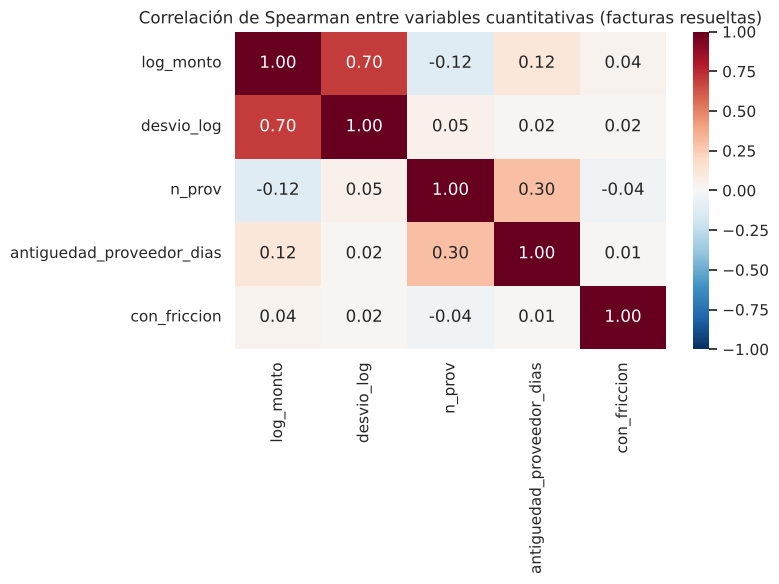

monto vs antigüedad del proveedor (con extremos no verificados): Pearson = 0.0450 | Spearman = 0.1190 | media del monto = 157,579 CAD
monto vs antigüedad del proveedor (sin extremos no verificados): Pearson = 0.0521 | Spearman = 0.1188 | media del monto = 149,852 CAD


In [56]:
# Matriz de correlación de Spearman entre variables cuantitativas conocidas al crear la factura (sin campos de aprobación)
# Los montos con error ya están en nulo y los extremos no verificados están excluidos de r
r["antiguedad_proveedor_dias"] = (r["Invoice Created Date"] - r["proveedor_id"].map(primera)).dt.days
vars_corr = ["log_monto", "desvio_log", "n_prov", "antiguedad_proveedor_dias", "con_friccion"]
corr = r[vars_corr].corr(method="spearman")
print(corr.round(2))
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1)
plt.title("Correlación de Spearman entre variables cuantitativas (facturas resueltas)")
plt.tight_layout(); plt.show()

# Sensibilidad a los extremos: Pearson (sensible a extremos) vs Spearman (por rangos), con y sin extremos no verificados
con_ext = resueltas.copy()
con_ext["antiguedad_proveedor_dias"] = (con_ext["Invoice Created Date"] - con_ext["proveedor_id"].map(primera)).dt.days
con_ext = con_ext.dropna(subset=["antiguedad_proveedor_dias"])
sin_ext = con_ext[~con_ext["extremo_no_verificado"]]
for nombre, d in [("con extremos no verificados", con_ext), ("sin extremos no verificados", sin_ext)]:
    print(f"monto vs antigüedad del proveedor ({nombre}): Pearson = "
          f"{stats.pearsonr(d['monto_cad'], d['antiguedad_proveedor_dias'])[0]:.4f} | Spearman = "
          f"{stats.spearmanr(d['monto_cad'], d['antiguedad_proveedor_dias'])[0]:.4f} | media del monto = {d['monto_cad'].mean():,.0f} CAD")

Ninguna variable cuantitativa por sí sola tiene una asociación importante con la fricción, ya que todas las correlaciones con ella están entre menos 0,04 y 0,04. Entre las variables, las únicas relaciones relevantes son la del monto con su distancia a la mediana del proveedor (0,70), que es esperable porque esa distancia se construye con el monto, y la del número de facturas del proveedor con su antigüedad (0,30).

La sensibilidad a los extremos no verificados muestra algo importante. La correlación de Pearson entre el monto y la antigüedad del proveedor pasa de 0,0450 a 0,0521 al quitarlos y la media del monto baja de 157.579 a 149.852 CAD, mientras que la de Spearman casi no cambia (0,1190 frente a 0,1188) porque trabaja con rangos. Esto confirma que para estas variables Spearman es la medida adecuada y que los extremos sí afectan los estadísticos que dependen de la magnitud.

**b) Vista conjunta de canal, categoría y gasto**

El mapa de calor cruza tres variables: el canal, la categoría y el porcentaje que representa cada categoría dentro del gasto aprobado del canal. Se complementa con una prueba chi cuadrado sobre el número de facturas.

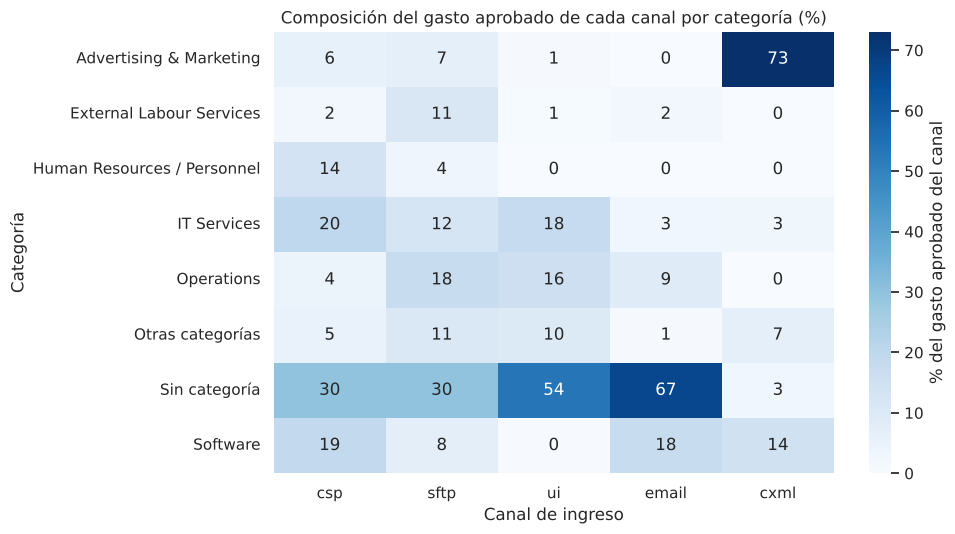

Categoría vs canal (conteos): chi2 = 39,583.0, p < 0,001, V de Cramér = 0.452, frecuencia esperada mínima = 36


In [57]:
# Vista conjunta de tres variables: canal x categoría, coloreada por % del gasto del canal
top_cat = aprobadas.groupby("Commodity Level 1")["monto_cad"].sum().nlargest(7).index
cat_g = aprobadas["Commodity Level 1"].where(aprobadas["Commodity Level 1"].isin(top_cat), "Otras categorías")
canales_p = ["csp", "sftp", "ui", "email", "cxml"]
sub_h = aprobadas["Invoice Channel"].isin(canales_p)
mix = pd.crosstab(cat_g[sub_h], aprobadas.loc[sub_h, "Invoice Channel"], values=aprobadas.loc[sub_h, "monto_cad"],
                  aggfunc="sum", normalize="columns")[canales_p] * 100
plt.figure(figsize=(10, 5.5))
sns.heatmap(mix, annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "% del gasto aprobado del canal"})
plt.title("Composición del gasto aprobado de cada canal por categoría (%)")
plt.xlabel("Canal de ingreso"); plt.ylabel("Categoría"); plt.yticks(rotation=0)
plt.tight_layout(); plt.show()
tabla_cc = pd.crosstab(cat_g[sub_h], aprobadas.loc[sub_h, "Invoice Channel"])
chi2_cc, p_cc, _, esp_cc = stats.chi2_contingency(tabla_cc)
print(f"Categoría vs canal (conteos): chi2 = {chi2_cc:,.1f}, {fmt_p(p_cc)}, V de Cramér = {cramers_v(tabla_cc):.3f}, "
      f"frecuencia esperada mínima = {esp_cc.min():.0f}")

Cada canal tiene un perfil de compra distinto y la asociación entre categoría y canal es fuerte (V de Cramér de 0,452). La frecuencia esperada mínima es 36, así que se cumple el supuesto de la prueba. En email, el 67% del gasto no tiene categoría y en ui es el 54%, frente al 30% del portal y de sftp, así que la falta de categoría se concentra en las facturas que digita el Banco. En cxml, el 73% del gasto es Advertising & Marketing, o sea que ese canal es casi exclusivo de los proveedores de publicidad, y Human Resources / Personnel pasa sobre todo por el portal (14% de su gasto).

Esto muestra que el canal y la categoría no son independientes. En el modelo conviene usarlas juntas o con interacciones, y cualquier comparación entre categorías se debería hacer dentro de cada canal.

**c) Regresión lineal de la fricción**

La regresión lineal permite ver la asociación de cada variable con la fricción manteniendo constantes las demás. La variable respuesta vale 100 si la factura tuvo fricción y 0 si no, así que cada coeficiente se lee directamente en puntos porcentuales. Se incluyen el canal (con csp como referencia), el log10 del monto, si tiene contrato, si el proveedor es intragrupo, si la moneda es CAD, la antigüedad del proveedor y el semestre, por la deriva que se vio en la sección 2. Los coeficientes se leen como asociaciones condicionales y no como efectos causales.

Hay que tener en cuenta dos cosas. La primera es que la regresión supone que las facturas son independientes y eso no es cierto, porque las de un mismo proveedor se parecen. En la sección 5.2 el bootstrap por proveedor dio un intervalo unas 1,7 veces más ancho que el que asume independencia, así que los intervalos de esta regresión son optimistas y los resultados con p cercano a 0,05 se deben leer con cuidado. La segunda es que la respuesta es binaria, así que el R² va a ser bajo y la regresión sirve para comparar asociaciones y no para predecir.

In [58]:
# Regresión lineal (modelo de probabilidad lineal): asociaciones condicionales de varias variables con la fricción.
# La variable respuesta es 100 si la factura tuvo fricción y 0 si no, así cada coeficiente se lee en puntos porcentuales.
m = resueltas[~resueltas["extremo_no_verificado"]].dropna(subset=["proveedor_id"]).copy()
m["friccion_pct"] = m["con_friccion"] * 100
m["log_monto"] = np.log10(m["monto_cad"])
m["semestre"] = m["Invoice Created Date"].dt.year.astype(str) + " S" + np.where(m["Invoice Created Date"].dt.month <= 6, "1", "2")
m["canal"] = m["Invoice Channel"].where(m["Invoice Channel"].isin(["csp", "sftp", "ui", "email", "cxml"]), "otro")
m["intragrupo"] = m["prov_intragrupo"].astype(int)
m["contrato"] = m["tiene_contrato"].astype(int)
m["moneda_cad"] = (m["Invoice Currency Code"] == "CAD").astype(int)
m["antiguedad_anios"] = (m["Invoice Created Date"] - m["proveedor_id"].map(primera)).dt.days / 365.25
modelo = smf.ols("friccion_pct ~ C(canal, Treatment('csp')) + log_monto + contrato + intragrupo + moneda_cad "
                 "+ antiguedad_anios + C(semestre)", data=m).fit()
coef = pd.DataFrame({"coef_puntos_pct": modelo.params, "ic95_inf": modelo.conf_int(ALPHA)[0],
                     "ic95_sup": modelo.conf_int(ALPHA)[1], "p_valor": modelo.pvalues})
coef.index = (coef.index.str.replace(r"C\(canal, Treatment\('csp'\)\)\[T\.", "canal=", regex=True)
              .str.replace(r"C\(semestre\)\[T\.", "semestre=", regex=True).str.replace("]", ""))
print(f"Facturas: {int(modelo.nobs):,} | R² = {modelo.rsquared:.3f} | R² ajustado = {modelo.rsquared_adj:.3f}")
coef.round(3)

Facturas: 51,143 | R² = 0.016 | R² ajustado = 0.015


,coef_puntos_pct,ic95_inf,ic95_sup,p_valor
Intercept,5.20,3.31,7.09,0.00
canal=cxml,-1.01,-2.22,0.21,0.10
canal=email,-4.87,-5.86,-3.87,0.00
canal=sftp,-1.30,-1.83,-0.76,0.00
canal=ui,-2.31,-2.90,-1.73,0.00
semestre=2025 S1,-0.32,-0.92,0.28,0.29
semestre=2025 S2,-1.90,-2.50,-1.30,0.00
semestre=2026 S1,-0.71,-1.35,-0.07,0.03
log_monto,1.42,1.04,1.80,0.00
contrato,-0.54,-1.06,-0.01,0.04


El R² es 0,016, lo que quiere decir que las variables disponibles al crear la factura explican muy poco de la fricción. Este resultado es importante porque muestra que el riesgo no se puede anticipar solo con estas características generales. Hacen falta las variables específicas de duplicado de la sección 3.5 y etiquetas reales.

Manteniendo las demás variables constantes, la asociación más fuerte es la de la moneda: las facturas en CAD tienen 5,91 puntos porcentuales menos de fricción que las de otras monedas (IC 95% de 5,38 a 6,45 puntos). Es una diferencia grande si se compara con la tasa global de 5,33%. Esto sugiere que la conversión, los proveedores del exterior o las entidades fuera de Canadá generan más correcciones. Además, cada vez que el monto se multiplica por 10, la fricción sube 1,42 puntos (IC de 1,04 a 1,80).

En cuanto al canal, email (4,87 puntos menos) y ui (2,31 puntos menos) tienen menos fricción que el portal, y sftp también queda por debajo del portal (1,30 puntos menos, IC de 0,76 a 1,83). Esto significa que la tasa alta de sftp en el análisis bivariado se explicaba por su mezcla de monedas y montos. Ser intragrupo se asocia con 1,83 puntos menos de fricción, al revés de lo que se veía en la sección 5.4, lo que muestra que esa diferencia también venía de otras variables. Tener contrato (0,54 puntos menos; p = 0,04) y la antigüedad del proveedor (0,25 puntos más por año; p = 0,03) quedan cerca del límite, así que con los intervalos optimistas no se deben tomar como asociaciones firmes. Por último, el segundo semestre de 2025 tiene 1,90 puntos menos de fricción que el último de 2024, lo que confirma que era necesario controlar el periodo.

**d) Reducción de dimensionalidad (PCA) de los perfiles de proveedor**

Cada proveedor con al menos 10 facturas resueltas se describe con ocho variables: volumen, monto típico, dispersión del monto, porcentaje sin contrato y su mezcla de canales y monedas. Las variables se estandarizan y se proyectan en dos componentes, y los puntos se colorean según la tasa de fricción para ver si el riesgo se agrupa en algún tipo de proveedor. Los campos de aprobación no se incluyen.

Varianza explicada: [0.278 0.225] | total: 0.503
                       PC1   PC2
log_facturas          0.23 -0.17
log_mediana_monto     0.30  0.10
dispersion_log_monto  0.32  0.18
pct_sin_contrato     -0.54  0.18
pct_sftp             -0.04  0.69
pct_csp               0.54 -0.27
pct_ui               -0.41 -0.46
pct_moneda_cad       -0.10 -0.37


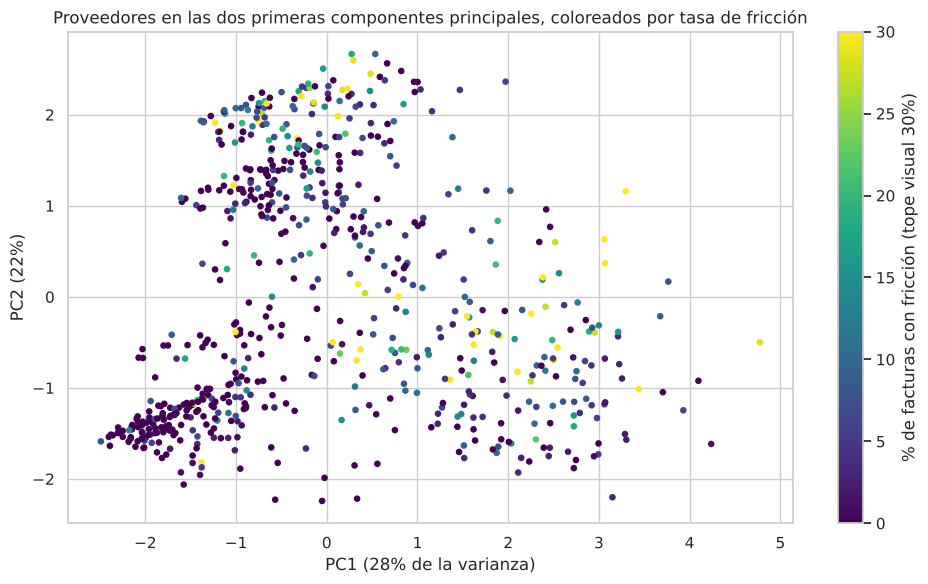

Spearman tasa de fricción vs PC1: 0.395 | vs PC2: 0.228


In [59]:
# Reducción de dimensionalidad: perfiles de proveedor (PCA) para ver si la fricción se agrupa en algún tipo de proveedor
perfil = resueltas.groupby("proveedor_id").agg(
    log_facturas=("monto_cad", lambda s: np.log10(len(s))),
    log_mediana_monto=("monto_cad", lambda s: np.log10(s.median())),
    dispersion_log_monto=("monto_cad", lambda s: np.log10(s).std(ddof=0)),
    pct_sin_contrato=("tiene_contrato", lambda s: 1 - s.mean()),
    pct_sftp=("Invoice Channel", lambda s: (s == "sftp").mean()),
    pct_csp=("Invoice Channel", lambda s: (s == "csp").mean()),
    pct_ui=("Invoice Channel", lambda s: (s == "ui").mean()),
    pct_moneda_cad=("Invoice Currency Code", lambda s: (s == "CAD").mean()),
    tasa_friccion=("con_friccion", "mean"),
    facturas=("con_friccion", "size"))
perfil = perfil[perfil["facturas"] >= 10]
X_cols = [c for c in perfil.columns if c not in ["tasa_friccion", "facturas"]]
pca = PCA(n_components=2, random_state=RANDOM_STATE)
comp = pca.fit_transform(StandardScaler().fit_transform(perfil[X_cols]))
print("Varianza explicada:", pca.explained_variance_ratio_.round(3), "| total:", pca.explained_variance_ratio_.sum().round(3))
cargas = pd.DataFrame(pca.components_.T, index=X_cols, columns=["PC1", "PC2"])
print(cargas.round(2))
fig, ax = plt.subplots(figsize=(10, 6))
sc = ax.scatter(comp[:, 0], comp[:, 1], c=perfil["tasa_friccion"] * 100, cmap="viridis", s=14, vmax=30)
plt.colorbar(sc, label="% de facturas con fricción (tope visual 30%)")
ax.set_title("Proveedores en las dos primeras componentes principales, coloreados por tasa de fricción")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} de la varianza)"); ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%})")
plt.tight_layout(); plt.show()
print("Spearman tasa de fricción vs PC1:", round(stats.spearmanr(comp[:, 0], perfil["tasa_friccion"])[0], 3),
      "| vs PC2:", round(stats.spearmanr(comp[:, 1], perfil["tasa_friccion"])[0], 3))

Las dos primeras componentes explican el 50,3% de la varianza (27,8% y 22,5%). La PC1 separa a los proveedores del portal con contrato y montos variables (cargas positivas en el porcentaje de csp y en la dispersión del monto) de los proveedores sin contrato y digitados internamente (cargas negativas en el porcentaje sin contrato y en el porcentaje de ui). La PC2 está dominada por el uso de sftp.

La tasa de fricción del proveedor se correlaciona más con la PC1 (ρ = 0,395) que con la PC2 (ρ = 0,228), y en la gráfica se ve que los proveedores con más fricción (los puntos claros) se ubican hacia la derecha, en el perfil del portal con contrato. Esto coincide con lo que se vio en la sección 3.5: buena parte de la fricción son correcciones y reenvíos de proveedores que facturan por el portal. Es una fricción operativa que no se debe confundir con el riesgo de un duplicado pagado.

### 5.7 Suficiencia de los datos para el modelo

El enunciado pide validar la calidad y también la suficiencia de los datos para la solución planteada. Para eso se revisan dos cosas. La primera es si hay suficiente historia por proveedor para comparar cada factura con las anteriores. La segunda es cuántos casos hay que etiquetar con el Banco para evaluar el modelo con un margen de error razonable.

In [60]:
# ¿Alcanzan los datos para el modelo? Historia por proveedor y tamaño de la muestra a etiquetar
hist_prov = aprobadas.groupby("proveedor_id").size()
prov5 = hist_prov[hist_prov >= 5].index
cubre = aprobadas[aprobadas["proveedor_id"].isin(prov5)]
print(f"Proveedores con >= 5 facturas aprobadas en la ventana: {len(prov5):,} de {hist_prov.size:,} ({len(prov5) / hist_prov.size:.1%}); "
      f"cubren {len(cubre) / len(aprobadas):.1%} de las facturas y {cubre['monto_cad'].sum() / aprobadas['monto_cad'].sum():.1%} del gasto")

# Tamaño de muestra para estimar la precisión de las alertas (proporción) con 95% de confianza, peor caso p = 0,5
z = stats.norm.ppf(0.975)
for margen in [0.05, 0.07, 0.10]:
    print(f"Margen de error ±{margen:.0%}: {int(np.ceil(z**2 * 0.25 / margen**2))} casos etiquetados")

# Estratos propuestos para la muestra de etiquetado (facturas aprobadas candidatas en la ventana)
estrato = np.select(
    [ap_v["dup_numero"],
     ap_v["dias_desde_mismo_monto"].eq(0) & ap_v["mismo_monto_mismo_transit"],
     ap_v["dias_desde_mismo_monto"].eq(0),
     ap_v["dias_desde_mismo_monto"].between(1, 7)],
    ["A. Número casi idéntico", "B. Mismo monto, mismo día y mismo transit", "C. Mismo monto, mismo día, otro transit",
     "D. Mismo monto en 1 a 7 días"], default="Sin señal")
estratos = pd.Series(estrato, index=ap_v.index).value_counts().drop("Sin señal").sort_index().to_frame("facturas")
estratos["muestra_propuesta"] = [min(n, k) for n, k in zip(estratos["facturas"], [100, 70, 30, 70])]
print("Tamaño total de la muestra propuesta:", estratos["muestra_propuesta"].sum())
estratos

Proveedores con >= 5 facturas aprobadas en la ventana: 961 de 2,775 (34.6%); cubren 93.5% de las facturas y 93.1% del gasto
Margen de error ±5%: 385 casos etiquetados
Margen de error ±7%: 196 casos etiquetados
Margen de error ±10%: 97 casos etiquetados
Tamaño total de la muestra propuesta: 202


,facturas,muestra_propuesta
A. Número casi idéntico,32,32
"B. Mismo monto, mismo día y mismo transit",1441,70
"C. Mismo monto, mismo día, otro transit",420,30
D. Mismo monto en 1 a 7 días,1185,70


Solo 961 de los 2.775 proveedores (el 34,6%) tienen 5 o más facturas aprobadas en la ventana. Sin embargo, esos proveedores cubren el 93,5% de las facturas y el 93,1% del gasto, así que las comparaciones contra la historia del proveedor, como la distancia a lo habitual del proveedor o la periodicidad, sí se pueden hacer para casi todo el gasto. Para los proveedores con poca historia hay que usar reglas más simples, como la similitud del número y el mismo monto.

En cuanto al etiquetado, para estimar la precisión de las alertas con un 95% de confianza y un margen de 7 puntos porcentuales se necesitan 196 casos en el peor escenario (p = 0,5). Con un margen de 5 puntos harían falta 385 y con uno de 10 puntos solo 97. Por eso se propone una muestra estratificada de 202 casos que incluye las 32 facturas con número casi idéntico, que son las más sospechosas, 70 del estrato de mismo monto, mismo día y mismo transit, 30 del estrato de mismo día en otro transit y 70 del estrato de mismo monto entre 1 y 7 días. Estratificar asegura que haya casos de cada patrón y permite estimar la precisión de cada regla por separado.

En conclusión, los datos son suficientes en volumen y cobertura para construir las variables. Lo que falta es la etiqueta, y ese es el insumo que el Banco tiene que aportar antes de la entrega 2.

## 6. Conclusiones del entendimiento de los datos

**¿Los datos tienen la calidad y la suficiencia necesarias?**

Para el objetivo 1, que es tener una vista confiable del gasto, sí. Los atributos de la factura están completos y son consistentes, solo hubo que corregir 3 conversiones y tratar un error de moneda, y los extremos están verificados. La ventana analítica cubre 7.138,0 millones de CAD aprobados. Quedan dos ajustes pendientes: consolidar el maestro de proveedores (22 nombres con varias llaves en la misma entidad y 20 pares casi idénticos por revisar) y separar en el tablero el gasto cargado a transits del gasto cargado a proyectos.

Para el objetivo 2, que es el puntaje de pago duplicado, los datos alcanzan para construir las variables pero no para evaluar el modelo. Los proveedores con suficiente historia cubren el 93,1% del gasto, pero no existe una etiqueta de duplicado confirmado y la fricción es una aproximación débil (R² de 0,016). Por eso se propone una muestra estratificada de 202 casos para que el Banco la etiquete.

**Hallazgos principales**

1. En agosto de 2024 el proceso cambió. El volumen se triplicó y cambiaron los canales y la proporción de facturas con contrato, así que los periodos no son comparables y el análisis se hizo de septiembre de 2024 a mayo de 2026 con control por semestre.
2. Hay duplicados que evaden el control del sistema. Se encontraron 6 grupos de facturas aprobadas con número casi idéntico y el mismo monto (120.379 CAD), y 3.078 candidatos amplios (el 6,4% de las aprobadas) que se concentran en el portal de proveedores (10,16%).
3. Tener el mismo monto no significa ser un duplicado. La facturación mensual, trimestral y anual explica la mayoría de las coincidencias de monto, así que el modelo tiene que aprender la periodicidad de cada proveedor.
4. Los campos de aprobación tienen fuga de información. Se llenan cuando la factura se aprueba, así que no sirven para explicar la fricción. Dentro de las aprobadas, la falta de cadena de aprobación sí se asocia con más candidatos a duplicado (5,02% frente a 3,22%).
5. Las facturas con montos atípicos para su proveedor tienen más fricción (9,69% frente a 4,96%) en las dos colas, y las monedas distintas de CAD son la variable más asociada con la fricción.
6. El gasto está muy concentrado. 150 proveedores (el 5,4%) explican el 80% del gasto y los 10 más grandes el 33,0%, y por área 55 transits explican el 80% del gasto con transit válido.

**Resultado de las hipótesis**

La hipótesis 1, sobre duplicados y fraccionamiento, se apoya en la parte de duplicados. Se encontraron 6 grupos fuertes de facturas aprobadas con número casi idéntico y el mismo monto, y 3.078 candidatos en total. El fraccionamiento no se pudo evaluar, porque la población está truncada en 10.000 CAD y no hay facturas por debajo del corte para ver si alguien parte una compra para quedar justo debajo de un umbral.

La hipótesis 2, sobre el canal y la cadena de aprobación, se apoya en parte. La asociación entre el canal y la fricción es débil (V de Cramér de 0,064) y cambia cuando se controlan la moneda y el monto, ya que sftp, que tenía la tasa más alta, queda por debajo del portal en la regresión. En cambio, la cadena de aprobación sí muestra una diferencia: entre las facturas aprobadas sin cadena hay 5,02% de candidatos a duplicado, frente a 3,22% de las que sí la tienen.

La hipótesis 3, sobre los proveedores nuevos, no se apoya y de hecho pasa lo contrario de lo que se esperaba. Los proveedores nuevos tienen menos fricción que los antiguos, y la antigüedad tiene una correlación positiva aunque débil con la fricción (ρ = 0,18).

La hipótesis 4, sobre los montos atípicos, se apoya. Las facturas que quedan por encima de la cerca del IQR de su proveedor tienen una tasa de fricción de 9,69%, frente a 4,96% de las que están dentro de las cercas, y la diferencia es significativa (p < 0,001).

**Técnicas utilizadas**

En el análisis univariado, las técnicas no gráficas fueron las medidas de tendencia central, de dispersión (desviación estándar e IQR), de posición (cuantiles) y de forma (asimetría y curtosis). Los atípicos se identificaron con la regla del IQR en la escala original, en la escala log10 y por proveedor, y las variables categóricas se describieron con frecuencias absolutas y relativas y con la participación acumulada de Pareto. En la parte gráfica se usaron histogramas en escala original y log10, boxplots, gráficos de barras de frecuencia, el diagrama de Pareto, la curva de concentración del gasto y la serie mensual de facturas.

En el análisis bivariado, la parte no gráfica incluyó tablas cruzadas con la prueba chi cuadrado y la V de Cramér para medir el tamaño de la asociación, intervalos de confianza para proporciones, la prueba t de Welch, el ANOVA de una vía, las correlaciones de Spearman y Pearson, el bootstrap por proveedor para revisar el supuesto de independencia y la similitud de Levenshtein para encontrar números de factura y nombres de proveedor casi iguales. Para verlo de forma gráfica se usaron mapas de calor de nulos y de composición, boxplots por grupo, gráficos de tasas con sus intervalos de confianza por canal y por nivel del monto, un diagrama de dispersión por proveedor y el histograma de días entre facturas del mismo monto.

Por último, en el análisis multivariado se usó la matriz de correlación de Spearman, una regresión lineal con variables categóricas para ver la asociación de cada variable con la fricción manteniendo las demás constantes, y un PCA de los perfiles de proveedor, del que se revisaron las cargas y la varianza explicada. Estos resultados se mostraron con el mapa de calor de las correlaciones, un mapa de calor que cruza canal, categoría y gasto, y la proyección de los proveedores en las dos primeras componentes, coloreada por su tasa de fricción.

**Próximos pasos para la entrega 2**

Lo primero es validar con el stakeholder los 6 grupos de duplicados fuertes, la muestra estratificada de 202 candidatos, los 22 nombres con varias llaves y los 20 pares casi idénticos, las 18 facturas extremas no verificadas y la explicación del cambio de régimen de agosto de 2024. También hay que pedir la tabla de niveles de aprobación por monto, la fecha de pago y el maestro de proveedores con su fecha de alta. Con eso se construyen las variables del modelo, como los días desde la factura del mismo monto, la desviación frente a la periodicidad del proveedor, la similitud de Levenshtein del número de factura, la coincidencia de transit y canal, la distancia del monto a lo habitual del proveedor y la moneda. El primer puntaje se arma con estas reglas, que son las mismas técnicas de duplicados aproximados y de atípicos que se usaron en este notebook. Cuando exista la muestra etiquetada, el puntaje se va a evaluar con dos proporciones: cuántos de los casos marcados se confirman como duplicado y cuántos de los duplicados confirmados aparecen en la cola, cada una con su intervalo de confianza. Los algoritmos de la entrega 2 se van a escoger entre los que se vean en el curso.

### Exportar la base preparada

La base anonimizada con las banderas de calidad se guarda en data/processed/ para la entrega 2. Esta carpeta tampoco se sube al repositorio.

In [61]:
# Exportar la base anonimizada con las banderas de calidad para la entrega 2 (la carpeta data/ no se sube al repositorio)
cols_export = [c for c in df.columns if c not in ["num_factura_original", "prov_nombre_norm"]]
df[cols_export].assign(mes=df["mes"].astype(str), trimestre=df["trimestre"].astype(str)).to_parquet(PROCESSED_PATH, index=False)
print("Archivo exportado:", PROCESSED_PATH, "| filas:", len(df), "| columnas:", len(cols_export))

Archivo exportado: ../data/processed/facturas_anonimizadas.parquet | filas: 75631 | columnas: 52
